<a href="https://colab.research.google.com/github/Bovi-analytics/Mallikarjuna-et-al-2026/blob/main/LOS_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


# Install R and connect to be able to use R magic cells

In [ ]:
!pip uninstall rpy2 -y
!pip install rpy2==3.5.1

Found existing installation: rpy2 3.5.1
Uninstalling rpy2-3.5.1:
  Successfully uninstalled rpy2-3.5.1
  Using cached rpy2-3.5.1-cp313-cp313-linux_x86_64.whl


In [ ]:
%load_ext rpy2.ipython

R cells start with `%%R`. Packages are installed into a persistent library in `BASE_DIR` the first time.

In [ ]:

%%R

# Paths and packages
BASE_DIR <- "/content/drive/Shareddrives/Bovi-Analytics/B&B 2025 Spring semester"
R_LIB <- file.path(BASE_DIR, "R-lib")

.libPaths(c(R_LIB, .libPaths()))

packages <- c("readr", "readxl", "openxlsx", "dplyr", "tidyr", "stringr", "lubridate", "data.table", "skimr",
              "glmnet", "brglm2", "sandwich", "lmtest", "lme4", "pROC", "PRROC", "precrec", "pmsampsize",
              "ResourceSelection", "dcurves", "gbm", "survival", "rpart", "rpart.plot", "partykit",
              "h2o", "ggplot2", "ggbeeswarm", "scales", "patchwork")

# Install only missing packages
missing_pkgs <- setdiff(packages, rownames(installed.packages()))

if (length(missing_pkgs) > 0) {
  install.packages(missing_pkgs, lib = R_LIB,
                   repos = "https://cloud.r-project.org")
}

# Update ggplot2 and patchwork to resolve compatibility
install.packages(c("ggplot2", "patchwork"), lib = R_LIB,
                 repos = "https://cloud.r-project.org")

# Load packages
suppressPackageStartupMessages(
  invisible(lapply(packages, library, character.only = TRUE))
)

cat("Packages loaded. R ", R.version$major, ".", R.version$minor,
    " | h2o ", as.character(packageVersion("h2o")), "\n", sep = "")





	‘/tmp/Rtmpk9Dh6j/downloaded_packages’



Packages loaded. R 4.6.1 | h2o 3.44.0.3


In [ ]:
%%R
# Output folders, figure style and variable labels
FigDir <- file.path(BASE_DIR, "Figures"); TabDir <- file.path(BASE_DIR, "Tables"); OutDir <- file.path(BASE_DIR, "Outputs")
for (d in c(FigDir, TabDir, OutDir)) dir.create(d, showWarnings = FALSE, recursive = TRUE)

# Colours
COL_BLUE <- "#2171b5"; COL_RED <- "#cb181d"; COL_GREEN <- "#238b45"; COL_GREY <- "#636363"; COL_ORANGE <- "#e6550d"

# Publication mode: titles and subtitles are left out of the saved figures (the caption carries them);
# set to FALSE to see titles while exploring.
PUB_MODE <- TRUE
theme_los <- function(base_size = 12) {
  t <- ggplot2::theme_classic(base_size = base_size, base_family = "sans") +
    ggplot2::theme(
      plot.title       = ggplot2::element_text(face = "bold", size = base_size + 1),
      plot.subtitle    = ggplot2::element_text(colour = COL_GREY, size = base_size - 1),
      axis.title       = ggplot2::element_text(face = "bold"),
      axis.text        = ggplot2::element_text(colour = "black"),
      legend.position  = "bottom",
      strip.background = ggplot2::element_blank(),
      strip.text       = ggplot2::element_text(face = "bold"))
  if (PUB_MODE) t <- t + ggplot2::theme(plot.title = ggplot2::element_blank(), plot.subtitle = ggplot2::element_blank())
  t
}

# Readable labels for every variable used in figures and tables (Title Case, units in brackets)
LABEL_MAP <- c(
  LOS_final                                       = "Outcome",
  embryo_age                                      = "Embryo Stage (IETS Code)",
  embryo_grade                                    = "Embryo Grade",
  recipient_cycle_date                            = "Recipient Cycle Day",
  sire_a_semen_type                               = "Semen Type",
  spo_program                                     = "Superovulation Protocol",
  coasting_duration                               = "Coasting Duration (h)",
  cumulus_expansion_post_maturation               = "Cumulus Expansion After IVM",
  heparin_concentration_in_fertilisation_droplets = "Heparin Concentration (µg/mL)",
  prop_good_quality                               = "Proportion of Good-Quality Embryos",
  storage_days                                    = "Frozen Storage (days)",
  rec_period                                      = "Recording Period",
  dam_age_at_opu_months                           = "Donor Age at OPU (months)",
  donor_age_le9                                   = "Donor Age ≤ 9 Months",
  recipient_age_years                             = "Recipient Age (years)",
  season                                          = "Season of Transfer",
  follicle_ratio                                  = "Follicle Ratio (large/small)",
  prop_good_cumulus                               = "Proportion of Oocytes with ≥3 Cumulus Layers",
  embryos_per_oocyte                              = "Embryos per Oocyte",
  cleavage_per_oocyte                             = "Cleavage per Oocyte",
  sire_birth_year                                 = "Sire Birth Year",
  calf_gender                                     = "Calf Sex",
  ivm_duration_h                                  = "IVM Duration (h)",
  ivf_duration_h                                  = "IVF Duration (h)",
  viable_embryos_per_session                      = "Viable Embryos per OPU Session",
  # variables of the conventional analysis file, used only in the comparison with the conventional analysis
  in_vitro_maturation_time                        = "IVM Start (clock time, min)",
  in_vitro_fertilisation_time                     = "IVF Start (clock time, min)",
  stripping_time                                  = "Denudation (clock time, min)",
  cumulus_ratio                                   = "Cumulus Ratio",
  embryos_per_transfer                            = "Viable Embryos per OPU Session",
  sync_category                                   = "Synchrony Category",
  recipient_heat_date                             = "Recipient Heat Day",
  dam_starting_state                              = "Donor Starting State"
)
LEVEL_MAP <- c(intensive = "From July 2024", early = "Before July 2024", other = "Not A",
               "Sexed Semen Female" = "Sexed (Female)", Conventional = "Conventional",
               le9 = "Yes", gt9 = "No", fall = "Autumn", winter = "Winter", spring = "Spring", summer = "Summer",
               Male = "Male", Female = "Female")

# exact name -> label; "variable + level" (e.g. rec_periodintensive, season.summer) -> "Label: Level"
CleanLabel <- function(x) {
  unname(vapply(as.character(x), function(v) {
    if (v %in% names(LABEL_MAP)) return(LABEL_MAP[[v]])
    b <- names(LABEL_MAP)[startsWith(v, names(LABEL_MAP))]
    if (length(b)) {
      b  <- b[which.max(nchar(b))]
      lv <- sub("^\\.", "", substring(v, nchar(b) + 1))
      return(paste0(LABEL_MAP[[b]], ": ", if (lv %in% names(LEVEL_MAP)) LEVEL_MAP[[lv]] else lv))
    }
    tools::toTitleCase(gsub("_", " ", v))
  }, character(1)))
}
CleanLevel <- function(x) ifelse(x %in% names(LEVEL_MAP), LEVEL_MAP[x], x)

# Save each figure as vector PDF, 600-dpi TIFF (journal submission) and 300-dpi PNG; PascalCase file names
SaveFig <- function(plot, name, width = 7, height = 5) {
  ggplot2::ggsave(file.path(FigDir, paste0(name, ".pdf")),  plot, width = width, height = height, device = cairo_pdf)
  ggplot2::ggsave(file.path(FigDir, paste0(name, ".tiff")), plot, width = width, height = height, dpi = 600, compression = "lzw")
  ggplot2::ggsave(file.path(FigDir, paste0(name, ".png")),  plot, width = width, height = height, dpi = 300)
  message("Saved figure: ", name)
}
# Publication column names for saved tables (analysis objects keep their short names)
TABLE_NAMES <- c(
  `n` = "Calves",
  `calves` = "Calves",
  `events` = "Events",
  `pct` = "Events (%)",
  `pct_event` = "Events (%)",
  `node` = "Terminal Node",
  `ET_status` = "Group",
  `c_sections` = "Caesarean Sections",
  `caesarean_sections` = "Caesarean Sections",
  `navel` = "Navel Events",
  `navel_events` = "Navel Events",
  `remarks` = "Large-Calf Remarks",
  `large_calf_remarks` = "Large-Calf Remarks",
  `half_year` = "Half-Year",
  `in_window` = "Within Recording Window",
  `OR` = "Odds Ratio",
  `Lower_CI` = "Lower 95% CI",
  `Upper_CI` = "Upper 95% CI",
  `P_value` = "P",
  `OR_per_10pp` = "Odds Ratio per 10 pp",
  `PR_AUC` = "PR-AUC",
  `PR_AUC_SD` = "PR-AUC SD",
  `PR_AUC_vs_No_Skill` = "PR-AUC / No-Skill",
  `Validation_Events` = "Validation Events (Median)",
  `Test_Events` = "Test Events (Median)",
  `Splits with Test PR-AUC >= 0.30 (%)` = "Splits with Test PR-AUC ≥ 0.30 (%)",
  `Observed_PR_AUC` = "Observed PR-AUC",
  `Null_Median` = "Permutation Median",
  `Null_95th_Percentile` = "Permutation 95th Percentile",
  `unit` = "Cluster",
  `clusters` = "Clusters",
  `clusters_with_event` = "Clusters with an Event",
  `max_events_per_cluster` = "Maximum Events per Cluster",
  `observed` = "Observed Dispersion",
  `permuted_median` = "Permutation Median",
  `Recorded_pct` = "Recorded (%)",
  `Distinct_values` = "Distinct Values",
  `Selected_in_pct_of_bootstraps` = "Selected (% of Bootstrap Samples)")
SaveTab <- function(df, name) {
  df <- as.data.frame(df)
  hit <- names(df) %in% names(TABLE_NAMES)
  names(df)[hit] <- TABLE_NAMES[names(df)[hit]]
  openxlsx::write.xlsx(df, file.path(TabDir, paste0(name, ".xlsx")), rowNames = FALSE)
  readr::write_csv(df, file.path(TabDir, paste0(name, ".csv")))
  message("Saved table: ", name)
}
fmt_or <- function(or, lo, hi) sprintf("%.2f (%.2f–%.2f)", or, lo, hi)
cat("Setup complete. Figures:", FigDir, "| Tables:", TabDir, "\n")

Setup complete. Figures: /content/drive/Shareddrives/Bovi-Analytics/B&B 2025 Spring semester/Figures | Tables: /content/drive/Shareddrives/Bovi-Analytics/B&B 2025 Spring semester/Tables 


# Import the data



## Calf-donor IDs


In [ ]:
%%R
# Load the data for calf-donor IDs
df_raw_calf_donor_IDs <- readr::read_csv(
    file = file.path(BASE_DIR, "raw_data/calfid_rid.CSV"))
glimpse(df_raw_calf_donor_IDs)

New names:
• `` -> `...5`
Rows: 6223 Columns: 5
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (3): ID, BDAT, RDAM
dbl (1): DID
lgl (1): ...5

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 6,223
Columns: 5
$ ID   <chr> "895", "1111", "1220", "1292", "1365", "1383", "1387", "1389", "1…
$ DID  <dbl> 0, 0, 0, 23719, 23719, 24222, 6288, 24548, 24090, 24090, 24135, 2…
$ BDAT <chr> "04/10/18", "10/21/19", "07/30/23", "06/06/23", "10/15/23", "10/2…
$ RDAM <chr> "0", "0", "0", "024057", "024461", "024446", "024476", "023423", …
$ ...5 <lgl> NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, N…


In [ ]:
%%R
# Fix formatting
df_calf_damIDs <- df_raw_calf_donor_IDs %>%
  dplyr::rename(
      calf_ID = 1,
      recipient_ID = RDAM,
      recipient_calving_date = BDAT,
      dam_ID = DID) %>%
    dplyr::mutate(
        recipient_calving_date = as.Date(recipient_calving_date, format = "%m/%d/%y"),
        calf_ID = as.character(calf_ID),
        recipient_ID = as.character(recipient_ID),
         # REMOVE leading zeros
        calf_ID = sub("^0+", "", calf_ID),
        recipient_ID = sub("^0+", "", recipient_ID)
        )
    df_calf_damIDs <- df_calf_damIDs %>%
  dplyr::select(calf_ID, recipient_ID, recipient_calving_date, dam_ID)
glimpse(df_calf_damIDs)

Rows: 6,223
Columns: 4
$ calf_ID                <chr> "895", "1111", "1220", "1292", "1365", "1383", …
$ recipient_ID           <chr> "", "", "", "24057", "24461", "24446", "24476",…
$ recipient_calving_date <date> 2018-04-10, 2019-10-21, 2023-07-30, 2023-06-06…
$ dam_ID                 <dbl> 0, 0, 0, 23719, 23719, 24222, 6288, 24548, 2409…


## Navel treatment data

In [ ]:
%%R
#Load dataset
df_raw_navel_treatements <- readr::read_csv(
    file = file.path(BASE_DIR, "farm_navel_treatments.csv"))
glimpse(df_raw_navel_treatements)

Rows: 116 Columns: 7
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (3): Event, Date, Remark
dbl (2): ID, DIM
lgl (2): Protocols, Technician

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 116
Columns: 7
$ ID         <dbl> 1501, 1506, 1508, 1510, 1537, 1540, 1564, 1565, 1565, 1565,…
$ Event      <chr> "NAVEL", "NAVEL", "NAVEL", "NAVEL", "NAVEL", "NAVEL", "NAVE…
$ DIM        <dbl> 13, 7, 6, 5, 16, 14, 24, 0, 0, 7, 7, 19, 20, 18, 14, 316, 1…
$ Date       <chr> "8/15/2024", "8/15/2024", "8/15/2024", "8/15/2024", "10/1/2…
$ Remark     <chr> "PENICILI", "PENICILI", "PENICILI", "PENICILI", "PENICILI",…
$ Protocols  <lgl> NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA,…
$ Technician <lgl> NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA,…


In [ ]:
%%R

# Navel events within 30 d of birth only (treatments at months of age are not perinatal signs); the event type is
# kept (ultrasonography or surgery vs antibiotic treatment).
df_navel_treatments <- df_raw_navel_treatements %>%
  dplyr::rename(
      calf_ID = ID,
      navel_treatment_date = Date,
      navel_treatment_type = Remark,
      calf_age = DIM
      ) %>%
    dplyr::mutate(
        navel_treatment_date = as.Date(navel_treatment_date, format = "%m/%d/%Y"),
        calf_ID = as.character(calf_ID),
        recipient_calving_date = navel_treatment_date - calf_age,
        navel_type = toupper(trimws(navel_treatment_type)),
        navel_workup = grepl("^(US|ULTRA|SURG)", navel_type),
        navel_abx = grepl("^(PENIC|POLYF)", navel_type)
    ) %>%
    dplyr::filter(calf_age <= 30) %>%
    dplyr::group_by(calf_ID, recipient_calving_date) %>%
    dplyr::summarise(navel_indicator = TRUE,
                     navel_workup = any(navel_workup),
                     navel_abx = any(navel_abx), .groups = "drop")
glimpse(df_navel_treatments)

Rows: 67
Columns: 5
$ calf_ID                <chr> "1501", "1506", "1508", "1510", "1537", "1540",…
$ recipient_calving_date <date> 2024-08-02, 2024-08-08, 2024-08-09, 2024-08-10…
$ navel_indicator        <lgl> TRUE, TRUE, TRUE, TRUE, TRUE, TRUE, TRUE, TRUE,…
$ navel_workup           <lgl> FALSE, FALSE, FALSE, FALSE, FALSE, FALSE, FALSE…
$ navel_abx              <lgl> TRUE, TRUE, TRUE, TRUE, TRUE, TRUE, TRUE, TRUE,…


## Recipient records

In [ ]:
%%R
#Load the data for recipient birthdates
df_raw_recipient_birthdates <- readr::read_csv(
    file = file.path(BASE_DIR, "raw_data/farm_recipient_birthdates.csv")
    )
glimpse(df_raw_recipient_birthdates)


Rows: 4173 Columns: 2
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (2): ID, BDAT

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 4,173
Columns: 2
$ ID   <chr> "1220", "1467", "1477", "1489", "1492", "1498", "1506", "1510", "…
$ BDAT <chr> "7/30/2023", "5/11/2024", "5/20/2024", "5/26/2024", "5/29/2024", …


In [ ]:
%%R
#Rename and format cols correctly for birthdates
df_recipient_birthdates <- df_raw_recipient_birthdates %>%
  dplyr::rename( #Rename cols so that we can use recip ID as keys
      recipient_ID = ID,
      recipient_birthdate = BDAT
      ) %>%
  dplyr::mutate( #Reformat birthdate column to date
      recipient_birthdate = as.Date(recipient_birthdate, format = "%m/%d/%Y")
  )
  glimpse(df_recipient_birthdates)

Rows: 4,173
Columns: 2
$ recipient_ID        <chr> "1220", "1467", "1477", "1489", "1492", "1498", "1…
$ recipient_birthdate <date> 2023-07-30, 2024-05-11, 2024-05-20, 2024-05-26, 2…


In [ ]:
%%R #Load in recipient dam records
#Change col types so data is formatted correctly
df_raw_recipient_records <- readr::read_csv(
    file = file.path(BASE_DIR, "raw_data/farm_calving_records_recipients.csv"),
    col_types = readr::cols(
          ID = readr::col_character(),
          Date = readr::col_character(),
          Remark = readr::col_character(),
          DIM = readr::col_character()
          )
      )
glimpse(df_raw_recipient_records)

Rows: 6,685
Columns: 7
$ ID         <chr> NA, "874", "895", "895", "1111", "1111", "1665", "1665", "1…
$ Event      <chr> NA, "FRESH", "FRESH", "FRESH", "FRESH", "FRESH", "FRESH", "…
$ DIM        <chr> NA, "0", "0", "0", "0", "0", "0", "0", "0", "0", "0", "0", …
$ Date       <chr> NA, "3/1/2023", "2/14/2023", "4/11/2024", "10/26/2023", "8/…
$ Remark     <chr> NA, "F", "MANGUS", "FANGUS", "F", "TRIPLETS", "F", "M", "F-…
$ Protocols  <lgl> NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA,…
$ Technician <lgl> NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA,…


In [ ]:
%%R
 #Rename cols so that we can use them as keys
 #Select relevant columns - we only need id, calving date, calf gender
 #Format dates correctly
df_recipient_records <- df_raw_recipient_records %>%
  dplyr::rename(
      recipient_ID = ID,
      recipient_calving_date = Date,
      calf_gender_remark = Remark) %>%
  dplyr::select(
      recipient_ID,
      recipient_calving_date,
      calf_gender_remark) %>%
  dplyr::mutate(
      recipient_calving_date = as.Date(recipient_calving_date, format = "%m/%d/%Y")
      )
glimpse(df_recipient_records)

Rows: 6,685
Columns: 3
$ recipient_ID           <chr> NA, "874", "895", "895", "1111", "1111", "1665"…
$ recipient_calving_date <date> NA, 2023-03-01, 2023-02-14, 2024-04-11, 2023-1…
$ calf_gender_remark     <chr> NA, "F", "MANGUS", "FANGUS", "F", "TRIPLETS", "…


## Embryo transfer

Each sheet of the embryo-transfer workbook is read separately, given the same column names and a laboratory identifier, and the sheets are combined.

In [ ]:
%%R

# For-loop to read each sheet of the excel file into a seperate data frame (code from Stack Overflow)
embryos_file_path <- file.path(BASE_DIR, "raw_data/farm_frozen_embryo_transfers2017.xlsx")
embryos_sheets <- getSheetNames(embryos_file_path)
for (sheet_name in embryos_sheets) {
  assign(sheet_name, read.xlsx(embryos_file_path, sheet = sheet_name))
}

In [ ]:
%%R
# Check the name of the sheets
embryos_sheets

#Check that each sheet have been converted to df
class(`Boviteq`)
class(`OakwoodSemex`) # Backticks to prevent space from creating an error
class(`TransOva`)
class(`OakwoodTransfers`)


[1] "data.frame"


In [ ]:
%%R
# Change df names to relevant naming convention
boviteq <- Boviteq
oakwood_semex <- `OakwoodSemex`
transova <- TransOva
oakwood_transfers <- `OakwoodTransfers`

In [ ]:
%%R
#Rename the columns
boviteq_renamed_select <- Boviteq %>%
  dplyr::rename(
      recipient_ID = Recip,
      recipient_bred_date = `Bred.Date`,
      embryo_transfer_date = `Trans.Date`,
      recipient_heat_date = `Heat.Date`,
      recipient_heat_time = `Heat.Time`,
      transfer_day_of_week = `Transfer.Date`,
      recipient_cycle_day = `Recip.Day`,
      sire_ID = Sire,
      donor_ID = Donor,
      embryo_age = Stage,
      embryo_grade = Grade,
      preg_open_status = `Preg/Open`,
      preg_open_binary = `1.=.Preg`,
      calf_GTPI = GTPI) %>%
  dplyr::select(
      recipient_ID,
      recipient_bred_date,
      embryo_transfer_date,
      recipient_heat_date,
      recipient_heat_time,
      recipient_cycle_day,
      sire_ID,
      transfer_day_of_week,
      donor_ID,
      embryo_age,
      embryo_grade,
      preg_open_status,
      preg_open_binary) %>%
  dplyr::mutate( #Change to correct data types and reformat dates
      recipient_ID = as.character(recipient_ID),
      sire_ID = as.factor(sire_ID),
      donor_ID = as.factor(donor_ID),
      embryo_age = as.factor(embryo_age),
      embryo_grade = as.factor(embryo_grade),
      embryo_transfer_date = as.Date(as.numeric(embryo_transfer_date), origin = "1899-12-30"),
      recipient_bred_date = as.Date(as.numeric(recipient_bred_date), origin = "1899-12-30"),
      recipient_heat_time = as.numeric(recipient_heat_time),
      recipient_cycle_day = as.numeric(recipient_cycle_day),
      preg_open_binary = as.numeric(preg_open_binary),
      lab = "boviteq"           )
  # We cannot include calf GTPI because it's not included in all of the datasets.
  glimpse(boviteq_renamed_select)
  colnames(transova)

Rows: 7,781
Columns: 14
$ recipient_ID         <chr> NA, "19275", "19271", "19261", "19232", "19202", …
$ recipient_bred_date  <date> NA, 2018-09-04, 2018-08-28, 2018-08-28, 2018-08-…
$ embryo_transfer_date <date> NA, 2018-09-11, 2018-09-04, 2018-09-04, 2018-09-…
$ recipient_heat_date  <chr> NA, "MON", "MON", "MON", "FRI", "MON", "MON", "TH…
$ recipient_heat_time  <dbl> NA, 0.25000000, 0.33333333, 0.83333333, 0.0833333…
$ recipient_cycle_day  <dbl> NA, 8.0, 8.0, 7.5, 8.0, 8.0, 8.0, 8.0, 7.0, 7.5, …
$ sire_ID              <fct> NA, EINSTEIN, EINSTEIN, EINSTEIN, EINSTEIN, EINST…
$ transfer_day_of_week <chr> NA, "TUES", "TUES", "TUES", "FRI", "TUES", "TUES"…
$ donor_ID             <fct> NA, 18382/18596, 18382/18596, 18382/18596, 18382/…
$ embryo_age           <fct> NA, 4, 5, 5, 4, 4, 4, 5, 5, 5, 4, 7, 8, 5, 7, 7, …
$ embryo_grade         <fct> NA, 2, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, …
$ preg_open_status     <chr> NA, "PREG", "OPEN", "PREG", "OPEN", "PREG", "PREG…
$ preg_open_bina

In [ ]:
%%R
#Repeat for the other dfs
oakwood_semex_renamed_select <- oakwood_semex %>%
  dplyr::rename(
      recipient_ID = Recip,
      recipient_bred_date = `Bred.Date`,
      embryo_transfer_date = `Trans.Date`,
      recipient_heat_date = `Heat.Date`,
      recipient_heat_time = `Heat.Time`,
      transfer_day_of_week = `Transfer.Date`,
      recipient_cycle_day = `Recip.Day`,
      sire_ID = Sire,
      donor_ID = Donor,
      embryo_age = Stage,
      embryo_grade = Grade,
      preg_open_status = `Preg/Open`,
      preg_open_binary = `1.=.Preg`) %>%
  dplyr::select(
      recipient_ID,
      recipient_bred_date,
      embryo_transfer_date,
      recipient_heat_date,
      recipient_heat_time,
      recipient_cycle_day,
      sire_ID,
      transfer_day_of_week,
      donor_ID,
      embryo_age,
      embryo_grade,
      preg_open_status,
      preg_open_binary) %>%
  dplyr::mutate( #Change to correct data types and reformat dates
      recipient_ID = as.character(recipient_ID),
      sire_ID = as.factor(sire_ID),
      donor_ID = as.factor(donor_ID),
      embryo_age = as.factor(embryo_age),
      embryo_grade = as.factor(embryo_grade),
      embryo_transfer_date = as.Date(as.numeric(embryo_transfer_date), origin = "1899-12-30"),
      recipient_bred_date = as.Date(as.numeric(recipient_bred_date), origin = "1899-12-30"),
      recipient_heat_time = as.numeric(recipient_heat_time),
      lab = "oakwood_semex"
                 )
  glimpse(oakwood_semex_renamed_select)
  colnames(oakwood_transfers)

Rows: 322
Columns: 14
$ recipient_ID         <chr> "5261", "5276", "5275", "5263", "5292", "5293", "…
$ recipient_bred_date  <date> 2021-07-23, 2021-07-23, 2021-07-27, 2021-07-28, …
$ embryo_transfer_date <date> 2021-07-31, 2021-07-31, 2021-08-04, 2021-08-05, …
$ recipient_heat_date  <chr> "Fri", "Fri", "Tues", "Wed", "Wed", "Sun", "Wed",…
$ recipient_heat_time  <dbl> 0.25000000, 0.25000000, 0.58333333, 0.91666667, 0…
$ recipient_cycle_day  <dbl> 8.5, 8.5, 8.0, 7.5, 8.0, 8.0, 8.0, 8.0, 7.5, 7.0,…
$ sire_ID              <fct> AltaPlinko, Horoscope, RangerRed, Wheelhouse, Alt…
$ transfer_day_of_week <chr> "Sat", "Sat", "Wed", "Thur", "Thur", "Mon", "Thur…
$ donor_ID             <fct> Packers, 82940.0, 82954.0, PomPom, PomPom, Limitl…
$ embryo_age           <fct> 7, 7, 7, 6, 7, 7, 7, 6, 7, 6, 6, 7, 6, 6, 6, 6, 6…
$ embryo_grade         <fct> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1…
$ preg_open_status     <chr> "OPEN", "OPEN", "OPEN", "PREG", "OPEN", "OPEN", "…
$ preg_open_binary

In [ ]:
%%R
colnames(oakwood_transfers)[1] <- "recipient_ID"
oakwood_transfers_renamed_selected <- oakwood_transfers %>%
  dplyr::rename(
      recipient_bred_date = `Bred.Date`,
      embryo_transfer_date = `Trans.Date`,
      recipient_heat_date = `Heat.Date`,
      recipient_heat_time = `Heat.Time`,
      transfer_day_of_week = `Transfer.Date`,
      recipient_cycle_day = `Recip.Day`,
      sire_ID = Sire,
      donor_ID = Donor,
      embryo_age = Stage,
      embryo_grade = Grade,
      preg_open_status = `Option.1`,
      preg_open_binary = `1.=.Preg`) %>%
  dplyr::select(
      recipient_ID,
       transfer_day_of_week,
      recipient_bred_date,
      embryo_transfer_date,
      recipient_heat_date,
      recipient_heat_time,
      recipient_cycle_day,
      sire_ID,
      donor_ID,
      embryo_age,
      embryo_grade,
      preg_open_status,
      preg_open_binary) %>%
  dplyr::mutate( #Change to correct data types and reformat dates
      recipient_ID = as.character(recipient_ID),
      sire_ID = as.factor(sire_ID),
      donor_ID = as.factor(donor_ID),
      embryo_age = as.factor(embryo_age),
      embryo_grade = as.factor(embryo_grade),
      embryo_transfer_date = as.Date(as.numeric(embryo_transfer_date), origin = "1899-12-30"),
      recipient_bred_date = as.Date(as.numeric(recipient_bred_date), origin = "1899-12-30"),
      recipient_heat_time = as.numeric(recipient_heat_time),
      lab = "oakwood_transfers")

glimpse(oakwood_transfers_renamed_selected)
colnames(oakwood_transfers_renamed_selected)


Rows: 1,301
Columns: 14
$ recipient_ID         <chr> NA, "1221", "1235", "1236", "1251", "1268", "1170…
$ transfer_day_of_week <chr> NA, "MON", "MON", "MON", "MON", "MON", "MON", "MO…
$ recipient_bred_date  <date> NA, 2017-10-30, 2017-10-30, 2017-10-30, 2017-10-…
$ embryo_transfer_date <date> NA, 2017-11-06, 2017-11-06, 2017-11-06, 2017-11-…
$ recipient_heat_date  <chr> NA, "SUN", "SUN", "SUN", "MON", "MON", "SUN", "MO…
$ recipient_heat_time  <dbl> NA, 0.87500000, 0.62500000, 0.95833333, 0.0416666…
$ recipient_cycle_day  <dbl> NA, 7.5, 7.5, 7.5, 7.0, 7.0, 8.0, 7.0, 7.0, 7.0, …
$ sire_ID              <fct> NA, FORTUNE, FORTUNE, FORTUNE, FORTUNE, FORTUNE, …
$ donor_ID             <fct> NA, 1958/17248, 1958/17248, 1958/17248, 1958/1724…
$ embryo_age           <fct> NA, 7, 6, 6, 5, 4, 6, 5, 5, 7, 7, 7, 7, 7, 6, 7, …
$ embryo_grade         <fct> NA, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, …
$ preg_open_status     <chr> NA, "PREG", "PREG", "PREG", "PREG", "PREG", "OPEN…
$ preg_open_bina

In [ ]:
%%R
transova_renamed_select <- transova %>%
  dplyr::rename(
      recipient_ID = Recip,
      recipient_bred_date = `Bred.Date`,
      transfer_day_of_week = `Transfer.Date`,
      recipient_heat_date = `Heat.Date`,
      recipient_heat_time = `Heat.Time`, #This dataset is missing the day of the work the trn
      recipient_cycle_day = `Recip.Day`,
      sire_ID = Sire,
      donor_ID = Donor,
      embryo_age = Stage,
      embryo_grade = Grade,
      preg_open_status = `Preg/Open`,
      preg_open_binary = `1.=.Preg`) %>%
  dplyr::select(
      recipient_ID,
      recipient_bred_date,
      transfer_day_of_week,
      recipient_heat_date,
      recipient_heat_time,
      recipient_cycle_day,
      sire_ID,
      donor_ID,
      embryo_age,
      embryo_grade,
      preg_open_status,
      preg_open_binary) %>%
  dplyr::mutate( #Change to correct data types and reformat dates
      recipient_ID = as.character(recipient_ID),
      sire_ID = as.factor(sire_ID),
      donor_ID = as.factor(donor_ID),
      embryo_age = as.factor(embryo_age),
      embryo_grade = as.factor(embryo_grade),
      recipient_bred_date = as.Date(as.numeric(recipient_bred_date), origin = "1899-12-30"),
      embryo_transfer_date = recipient_bred_date %m+% days(7),
      recipient_heat_time = as.numeric(recipient_heat_time),
      lab = "transova"
                 )
  #glimpse(transova_renamed_select)
  glimpse(boviteq_renamed_select)
  #glimpse(oakwood_semex_renamed_select)
  #glimpse(oakwood_transfers_renamed_selected)

Rows: 7,781
Columns: 14
$ recipient_ID         <chr> NA, "19275", "19271", "19261", "19232", "19202", …
$ recipient_bred_date  <date> NA, 2018-09-04, 2018-08-28, 2018-08-28, 2018-08-…
$ embryo_transfer_date <date> NA, 2018-09-11, 2018-09-04, 2018-09-04, 2018-09-…
$ recipient_heat_date  <chr> NA, "MON", "MON", "MON", "FRI", "MON", "MON", "TH…
$ recipient_heat_time  <dbl> NA, 0.25000000, 0.33333333, 0.83333333, 0.0833333…
$ recipient_cycle_day  <dbl> NA, 8.0, 8.0, 7.5, 8.0, 8.0, 8.0, 8.0, 7.0, 7.5, …
$ sire_ID              <fct> NA, EINSTEIN, EINSTEIN, EINSTEIN, EINSTEIN, EINST…
$ transfer_day_of_week <chr> NA, "TUES", "TUES", "TUES", "FRI", "TUES", "TUES"…
$ donor_ID             <fct> NA, 18382/18596, 18382/18596, 18382/18596, 18382/…
$ embryo_age           <fct> NA, 4, 5, 5, 4, 4, 4, 5, 5, 5, 4, 7, 8, 5, 7, 7, …
$ embryo_grade         <fct> NA, 2, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, …
$ preg_open_status     <chr> NA, "PREG", "OPEN", "PREG", "OPEN", "PREG", "PREG…
$ preg_open_bina

In [ ]:
%%R
all_embryo_transfers <- boviteq_renamed_select %>%
  dplyr::union(oakwood_semex_renamed_select) %>%
  dplyr::union(oakwood_transfers_renamed_selected) %>%
  dplyr::union(transova_renamed_select)
all_embryo_transfers <- all_embryo_transfers %>%
  dplyr::mutate(
      approx_recipient_calving_date = all_embryo_transfers$embryo_transfer_date %m+% months(9), #Approximate birthdates
      approx_recipient_calving_date_minus_7 = approx_recipient_calving_date %m-% days(7),
      approx_recipient_calving_date_plus_7 = approx_recipient_calving_date %m+% days(7)
  )
  #separate_rows(donor_ID, sep = "/") #do not seperate here as it explodes and causes duplicates during the joins
  #dplyr::filter(preg_open_binary == 1)
glimpse(all_embryo_transfers)


Rows: 9,665
Columns: 17
$ recipient_ID                          <chr> NA, "19275", "19271", "19261", "…
$ recipient_bred_date                   <date> NA, 2018-09-04, 2018-08-28, 201…
$ embryo_transfer_date                  <date> NA, 2018-09-11, 2018-09-04, 201…
$ recipient_heat_date                   <chr> NA, "MON", "MON", "MON", "FRI", …
$ recipient_heat_time                   <dbl> NA, 0.25000000, 0.33333333, 0.83…
$ recipient_cycle_day                   <dbl> NA, 8.0, 8.0, 7.5, 8.0, 8.0, 8.0…
$ sire_ID                               <fct> NA, EINSTEIN, EINSTEIN, EINSTEIN…
$ transfer_day_of_week                  <chr> NA, "TUES", "TUES", "TUES", "FRI…
$ donor_ID                              <fct> NA, 18382/18596, 18382/18596, 18…
$ embryo_age                            <fct> NA, 4, 5, 5, 4, 4, 4, 5, 5, 5, 4…
$ embryo_grade                          <fct> NA, 2, 1, 1, 1, 1, 1, 1, 1, 1, 2…
$ preg_open_status                      <chr> NA, "PREG", "OPEN", "PREG", "OPE…
$ preg_open_bina

In [ ]:
%%R
#delete column recipient_cycle_day because we are making a new column to prevent confusion
all_embryo_transfers <- subset(all_embryo_transfers, select = -c(recipient_cycle_day))


In [ ]:
%%R
#create column "recipient_cycle_date" using transfer_day_of_week and recipient_heat_date
all_embryo_transfers <- all_embryo_transfers %>%
  dplyr::mutate(
      #convert heat date to uppercase
      recipient_heat_date = trimws(toupper(recipient_heat_date)),
      transfer_day_of_week = trimws(toupper(transfer_day_of_week)),
      recipient_heat_date = dplyr::case_when(
      recipient_heat_date %in% c("THU", "THUR", "THURS") ~ "THURS",
      recipient_heat_date %in% c("TUE", "TUES") ~ "TUES",
      TRUE ~ recipient_heat_date
                                ),
      transfer_day_of_week = dplyr::case_when(
      transfer_day_of_week %in% c("THU", "THUR", "THURS") ~ "THURS",
      transfer_day_of_week %in% c("TUE", "TUES") ~ "TUES",
      TRUE ~ transfer_day_of_week
                                ),
      recipient_cycle_date = case_when(
      recipient_heat_date == transfer_day_of_week ~ 7,

    recipient_heat_date == "MON" & transfer_day_of_week == "SUN"  ~ 6,
    recipient_heat_date %in% c("TUE", "TUES") & transfer_day_of_week == "MON"  ~ 6,
    recipient_heat_date == "WED" & transfer_day_of_week %in% c("TUE", "TUES")  ~ 6,
    recipient_heat_date %in% c("THU", "THUR", "THURS") & transfer_day_of_week == "WED"  ~ 6,
    recipient_heat_date == "FRI" & transfer_day_of_week %in% c("THU", "THUR", "THURS")  ~ 6,
    recipient_heat_date == "SAT" & transfer_day_of_week == "FRI"  ~ 6,
    recipient_heat_date == "SUN" & transfer_day_of_week == "SAT"  ~ 6,
#for day 8
    recipient_heat_date == "MON" & transfer_day_of_week %in% c("TUE", "TUES")  ~ 8,
    recipient_heat_date %in% c("THU", "THUR", "THURS") & transfer_day_of_week == "FRI"  ~ 8,
    recipient_heat_date == "SUN" & transfer_day_of_week == "MON"  ~ 8,
    recipient_heat_date %in% c("TUE", "TUES") & transfer_day_of_week == "WED"  ~ 8,
    recipient_heat_date == "WED" & transfer_day_of_week %in% c("THU", "THUR", "THURS")  ~ 8,
    recipient_heat_date == "FRI" & transfer_day_of_week == "SAT"  ~ 8,
    recipient_heat_date == "SAT" & transfer_day_of_week == "SUN"  ~ 8,
# for day 9
    recipient_heat_date == "MON" & transfer_day_of_week == "WED"  ~ 9,
    recipient_heat_date %in% c("TUE", "TUES") & transfer_day_of_week %in% c("THU", "THUR", "THURS")  ~ 9,
    recipient_heat_date == "WED" & transfer_day_of_week == "FRI"  ~ 9,
    recipient_heat_date %in% c("THU", "THUR", "THURS") & transfer_day_of_week == "SAT"  ~ 9,
    recipient_heat_date == "FRI" & transfer_day_of_week == "SUN"  ~ 9,
    recipient_heat_date == "SAT" & transfer_day_of_week == "MON"  ~ 9,
    recipient_heat_date == "SUN" & transfer_day_of_week %in% c("TUE", "TUES")  ~ 9,
#day 10
    recipient_heat_date == "MON" & transfer_day_of_week %in% c("THU", "THUR", "THURS")  ~ 10,
    recipient_heat_date %in% c("TUE", "TUES") & transfer_day_of_week == "FRI"  ~ 10,
    recipient_heat_date == "WED" & transfer_day_of_week == "SAT"  ~ 10,
    recipient_heat_date %in% c("THU", "THUR", "THURS") & transfer_day_of_week == "SUN"  ~ 10,
    recipient_heat_date == "FRI" & transfer_day_of_week == "MON"  ~ 10,
    recipient_heat_date == "SAT" & transfer_day_of_week %in% c("TUE", "TUES")  ~ 10,
    recipient_heat_date == "SUN" & transfer_day_of_week == "WED"  ~ 10,
      #day 11
    recipient_heat_date == "MON" & transfer_day_of_week == "FRI"  ~ 11,
    recipient_heat_date %in% c("TUE", "TUES") & transfer_day_of_week == "SAT"  ~ 11,
    recipient_heat_date == "WED" & transfer_day_of_week == "SUN"  ~ 11,
    recipient_heat_date %in% c("THU", "THUR", "THURS") & transfer_day_of_week == "MON"  ~ 11,
    recipient_heat_date == "FRI" & transfer_day_of_week %in% c("TUE", "TUES")  ~ 11,
    recipient_heat_date == "SAT" & transfer_day_of_week == "WED"  ~ 11,
    recipient_heat_date == "SUN" & transfer_day_of_week %in% c("THU", "THUR", "THURS")  ~ 11,
      #day 12 can also be day 4 so what should we do??
    recipient_heat_date == "MON" & transfer_day_of_week == "SAT"  ~ 12,
    recipient_heat_date %in% c("TUE", "TUES") & transfer_day_of_week == "SUN"  ~ 12,
    recipient_heat_date == "WED" & transfer_day_of_week == "MON"  ~ 12,
    recipient_heat_date %in% c("THU", "THUR", "THURS") & transfer_day_of_week %in% c("TUE", "TUES")  ~ 12,
    recipient_heat_date == "FRI" & transfer_day_of_week == "WED"  ~ 12,
    recipient_heat_date == "SAT" & transfer_day_of_week %in% c("THU", "THUR", "THURS")  ~ 12,
    recipient_heat_date == "SUN" & transfer_day_of_week == "FRI"  ~ 12,
      is.na(recipient_heat_date) | is.na(transfer_day_of_week) ~ NA_real_,
      TRUE ~ 99
    ))
  glimpse(all_embryo_transfers)

Rows: 9,665
Columns: 17
$ recipient_ID                          <chr> NA, "19275", "19271", "19261", "…
$ recipient_bred_date                   <date> NA, 2018-09-04, 2018-08-28, 201…
$ embryo_transfer_date                  <date> NA, 2018-09-11, 2018-09-04, 201…
$ recipient_heat_date                   <chr> NA, "MON", "MON", "MON", "FRI", …
$ recipient_heat_time                   <dbl> NA, 0.25000000, 0.33333333, 0.83…
$ sire_ID                               <fct> NA, EINSTEIN, EINSTEIN, EINSTEIN…
$ transfer_day_of_week                  <chr> NA, "TUES", "TUES", "TUES", "FRI…
$ donor_ID                              <fct> NA, 18382/18596, 18382/18596, 18…
$ embryo_age                            <fct> NA, 4, 5, 5, 4, 4, 4, 5, 5, 5, 4…
$ embryo_grade                          <fct> NA, 2, 1, 1, 1, 1, 1, 1, 1, 1, 2…
$ preg_open_status                      <chr> NA, "PREG", "OPEN", "PREG", "OPE…
$ preg_open_binary                      <dbl> NA, 1, 0, 1, 0, 1, 1, 0, 0, 1, 1…
$ lab           

## Lab summary data

In [ ]:
%%R

#Load raw lab summaries
df_raw_lab_summary_ny <- read_excel(
  path = file.path(BASE_DIR, "raw_data/lab_data/aurora_ridge_syracuse_ny_summary.xlsx")
)

df_raw_lab_summary_wi <- read_excel(
  path = file.path(BASE_DIR, "raw_data/lab_data/aurora_ridge_madison_wi_summary.xlsx")
)

#Formatting
clean_lab_names <- function(df) {
  df %>%
    rename_with(tolower) %>%
    rename_with(~ gsub(" ", "_", .x)) %>%
    rename_with(~ gsub("-", "_", .x)) %>%
    rename_with(~ gsub("%", "percent", .x)) %>%
    rename_with(~ gsub(">", "greater_than", .x)) %>%
    rename_with(~ gsub("≥", "greater_than_or_equal_to", .x))
}

#NY lab data
df_lab_summary_ny <- df_raw_lab_summary_ny %>%
  clean_lab_names() %>%
  rename(
    donor_ID               = dam_short_name,
    sire_ID                = sire_a_short_name,
    embryo_collection_date = embryo_lot_date
  ) %>%
  mutate(boviteq_lab_ID = "ny")

#WI lab data
df_lab_summary_wi <- df_raw_lab_summary_wi %>%
  clean_lab_names() %>%
  rename(
    donor_ID               = dam_short_name,
    sire_ID                = sire_a_short_name,
    embryo_collection_date = embryo_lot_date
  ) %>%
  mutate(boviteq_lab_ID = "wi")

#Columns that should split together
split_cols <- c(
  "donor_ID",
  "dam_boviteq_number",
  "dam_starting_state",
  "spo_program",
  "coasting_duration",
  "dam_birth_date",
  "dam_age_at_opu",
  "dam_registration_number",
  "dam_complete_name",
  "dam_breed"
)

#Combine + clean + split
lab_data <- bind_rows(df_lab_summary_ny, df_lab_summary_wi) %>%

  mutate(
    sire_ID = str_remove(sire_ID, "\\s*\\(.*\\)"),
    sire_ID = str_trim(sire_ID),
    sire_ID = toupper(sire_ID),
    donor_number = str_extract(donor_ID, "\\d+"),
    donor_number = as.character(donor_number),

    embryo_collection_date = as.Date(embryo_collection_date)
  ) %>%

  #Replace multiline separators with unique delimiter
  mutate(
    across(
      all_of(split_cols),
      ~ str_replace_all(as.character(.), "\n", "|||")
    )
  ) %>%

  #Split donor-level columns in parallel
  separate_rows(
    all_of(split_cols),
    sep = "\\|\\|\\|"
  ) %>%

  #Clean split columns
  mutate(
    across(
      all_of(split_cols),
      ~ str_trim(.)
    ),
    donor_ID = str_replace_all(donor_ID, "\\.0$", "")
  ) %>%
  #Remove empty donor rows
  filter(
    !is.na(donor_ID),
    donor_ID != ""
  ) %>%

  #Derived variables
  mutate(
    prop_good_quality = good_quality_morulas / number_of_morulas,
    prop_poor_quality = poor_quality_morulas / number_of_morulas
  )

#Check remaining \ issues
n_remaining <- lab_data %>%
  select(all_of(split_cols)) %>%
  filter(if_any(everything(), ~ str_detect(., "\n"))) %>%
  nrow()
cat("\nRows still containing \\n:", n_remaining, "\n")
cat("Total rows after split:", nrow(lab_data), "\n")

glimpse(lab_data)

# Donor numbers are extracted after pooled lots are split, so that every donor of a pooled lot keeps its own number.
lab_data <- lab_data %>%
  dplyr::mutate(donor_number = sub("^0+", "", stringr::str_extract(donor_ID, "\\d+")))
cat("lab rows:", nrow(lab_data), " unique donor numbers:", dplyr::n_distinct(lab_data$donor_number), "\n")



Rows still containing \n: 0 
Total rows after split: 1390 
Rows: 1,390
Columns: 69
$ opu_date                                        <dttm> 2022-12-06, 2022-12-0…
$ insemination_date                               <dttm> 2022-12-06, 2022-12-0…
$ embryo_lot                                      <chr> "22DE14", "22DE14", "2…
$ embryo_collection_date                          <date> 2022-12-14, 2022-12-1…
$ flush_date                                      <dttm> 2022-12-14, 2022-12-1…
$ laboratory                                      <chr> "Boviteq USA", "Bovite…
$ collection_site                                 <chr> "White Oak Vet Clinic"…
$ dam_boviteq_number                              <chr> "HO24417", "HO24935", …
$ donor_ID                                        <chr> "AHEAD 6348", "GAMEDAY…
$ dam_complete_name                               <chr> "Aurora AHEAD 6348-ET"…
$ dam_registration_number                         <chr> "HO840F3233449771", "H…
$ dam_breed                         

## C Sections

In [ ]:
%%R #Load in farm csection data
library(readr)
df_raw_farm_caesarean_sections_recipients <- readr::read_csv(
    file = file.path(BASE_DIR, "raw_data/farm_caesarean_sections_recipients.csv"),
    col_types = readr::cols(
        ID = readr::col_character(),
        Date = readr::col_character(),
        Remark = readr::col_character(),
        )
    )

In [ ]:
%%R
#Apply naming convention to cols in csection data
df_farm_caesarean_sections_recipients <- df_raw_farm_caesarean_sections_recipients %>%
  dplyr::rename(
    recipient_ID = ID,
    recipient_calving_date = Date,
    caesarean_remark = Remark
  ) %>%
  dplyr::select(
    recipient_ID,
    recipient_calving_date,
    caesarean_remark
  ) %>%
  dplyr::mutate(
    recipient_calving_date = as.Date(recipient_calving_date, format = "%m/%d/%Y"),
    caesarean_indicator = as.factor(TRUE)
  )
glimpse(df_farm_caesarean_sections_recipients)

Rows: 18
Columns: 4
$ recipient_ID           <chr> "23605", "23730", "24138", "24299", "24297", "2…
$ recipient_calving_date <date> 2023-02-01, 2023-04-04, 2023-07-19, 2023-09-25…
$ caesarean_remark       <chr> "CSECTION", "CSECTION", "CSECTION", "CSECTION",…
$ caesarean_indicator    <fct> TRUE, TRUE, TRUE, TRUE, TRUE, TRUE, TRUE, TRUE,…


In [ ]:
%%R #Load in csection data from calves that died
library(readr)
df_raw_farm_csectionsdied <- readr::read_csv(
    file = file.path(BASE_DIR, "raw_data/c_sections_died.csv"),
    col_types = readr::cols(
        calf_ID = readr::col_character(),
        remark = readr::col_character(),
        event = readr::col_character(),
        ))
df_csections_died <- df_raw_farm_csectionsdied %>%
  dplyr::rename( #Rename cols to match csection data
      recipient_ID = calf_ID,
      caesarean_remark = remark,
      recipient_calving_date = date
  ) %>%
  dplyr::select( #Select same cols as csection data
      recipient_ID,
      caesarean_remark,
      recipient_calving_date
  ) %>%
  dplyr::mutate( #Fix date
      recipient_calving_date = as.Date(recipient_calving_date, format = "%m/%d/%Y"),
      caesarean_indicator = as.factor(TRUE)
  )
  #Union of calves that are alive and that died
df_csections <- dplyr::union(df_farm_caesarean_sections_recipients, df_csections_died) #Union csection data with died csections data
glimpse(df_csections)

Rows: 21
Columns: 4
$ recipient_ID           <chr> "23605", "23730", "24138", "24299", "24297", "2…
$ recipient_calving_date <date> 2023-02-01, 2023-04-04, 2023-07-19, 2023-09-25…
$ caesarean_remark       <chr> "CSECTION", "CSECTION", "CSECTION", "CSECTION",…
$ caesarean_indicator    <fct> TRUE, TRUE, TRUE, TRUE, TRUE, TRUE, TRUE, TRUE,…


## Donor birthdates

In [ ]:
%%R #Load in donor birthdate farm data
library(readr)
df_raw_farm_donor_birthdates <- readr::read_csv(
    file = file.path(BASE_DIR, "raw_data/farm_donor_birthdates.csv"),
    col_types = readr::cols( #Fix col types
        ID = readr::col_character(),
        SID = readr::col_character(),
        Date = readr::col_character(),
        )
    )

In [ ]:
%%R
# Apply naming convention to donor birthdate data
df_farm_donor_birthdates <- df_raw_farm_donor_birthdates %>%
  dplyr::rename(
    donor_ID = ID,
    donor_sire_ID = SID,
    donor_birth_date = BDAT
  ) %>%
  dplyr::select( #Select relevant cols
    donor_ID,
    donor_sire_ID,
    donor_birth_date
  ) %>%
  dplyr::mutate( #Fix dates
    donor_birth_date = as.Date(donor_birth_date, format = "%m/%d/%Y")
  )
glimpse(df_farm_donor_birthdates)

Rows: 99
Columns: 3
$ donor_ID         <chr> "1111", "1220", "1789", "5971", "6288", "6333", "6336…
$ donor_sire_ID    <chr> "14H14085", "7H16276", "7H15430", "11H15036", "250H15…
$ donor_birth_date <date> 2019-10-21, 2023-07-30, 2021-12-06, 2020-11-28, 2021…


# Joins


## Joining C-sections and Navel Treatments to calf-donor records

In [ ]:
%%R

#Join the Csection & Navel treatment data with the calf-donor IDs
# The caesarean-section files contain both cow and calf identities. A calf is flagged if its own ID or its
# recipient's ID has a caesarean section recorded within 3 d of its birth.
cs_events <- df_csections %>%
  dplyr::transmute(cs_ID = sub("^0+", "", trimws(recipient_ID)), cs_date = recipient_calving_date) %>%
  dplyr::distinct()
csec_hit <- function(cid, rid, d) any((cs_events$cs_ID == cid | cs_events$cs_ID == rid) &
                                      abs(as.numeric(cs_events$cs_date - d)) <= 3, na.rm = TRUE)

df_joined <- df_calf_damIDs %>%
  dplyr::left_join(df_navel_treatments,
                   join_by("calf_ID", "recipient_calving_date")
                   ) %>%
  dplyr::filter(!is.na(recipient_ID), recipient_ID != "") %>%
  dplyr::mutate(
      caesarean_binary = as.numeric(mapply(csec_hit, calf_ID, recipient_ID, recipient_calving_date)),
      caesarean_indicator = ifelse(caesarean_binary == 1, TRUE, NA),
      caesarean_remark = ifelse(caesarean_binary == 1, "CSECTION", NA_character_),
      navel_treatment_binary = case_when(
          navel_indicator == TRUE ~ 1,
          TRUE ~ 0),
      LOS_positive = ifelse(caesarean_binary == 1 | navel_treatment_binary == 1, 1, 0)
  ) %>%
  dplyr::arrange(desc(LOS_positive))

glimpse(df_joined)
table(df_joined$LOS_positive)
cat("calves linked to a c-section:", sum(df_joined$caesarean_binary), "\n")

Rows: 6,202
Columns: 12
$ calf_ID                <chr> "1501", "1506", "1508", "1510", "1537", "1540",…
$ recipient_ID           <chr> "25273", "25236", "24153", "25399", "25488", "2…
$ recipient_calving_date <date> 2024-08-02, 2024-08-08, 2024-08-09, 2024-08-10…
$ dam_ID                 <dbl> 25346, 25736, 25354, 11933, 25285, 25888, 25346…
$ navel_indicator        <lgl> TRUE, TRUE, TRUE, TRUE, TRUE, TRUE, TRUE, TRUE,…
$ navel_workup           <lgl> FALSE, FALSE, FALSE, FALSE, FALSE, FALSE, FALSE…
$ navel_abx              <lgl> TRUE, TRUE, TRUE, TRUE, TRUE, TRUE, TRUE, TRUE,…
$ caesarean_binary       <dbl> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,…
$ caesarean_indicator    <lgl> NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA,…
$ caesarean_remark       <chr> NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA,…
$ navel_treatment_binary <dbl> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,…
$ LOS_positive           <dbl> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,…
calves linked to

##Gender data

In [ ]:
%%R

#Adding recipient calving records for Gender Remark
df_joined <- df_joined %>%
dplyr::left_join(df_recipient_records,
                 join_by("recipient_ID","recipient_calving_date")
)
glimpse(df_joined)
unique(df_joined$calf_gender_remark)

Rows: 6,202
Columns: 13
$ calf_ID                <chr> "1501", "1506", "1508", "1510", "1537", "1540",…
$ recipient_ID           <chr> "25273", "25236", "24153", "25399", "25488", "2…
$ recipient_calving_date <date> 2024-08-02, 2024-08-08, 2024-08-09, 2024-08-10…
$ dam_ID                 <dbl> 25346, 25736, 25354, 11933, 25285, 25888, 25346…
$ navel_indicator        <lgl> TRUE, TRUE, TRUE, TRUE, TRUE, TRUE, TRUE, TRUE,…
$ navel_workup           <lgl> FALSE, FALSE, FALSE, FALSE, FALSE, FALSE, FALSE…
$ navel_abx              <lgl> TRUE, TRUE, TRUE, TRUE, TRUE, TRUE, TRUE, TRUE,…
$ caesarean_binary       <dbl> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,…
$ caesarean_indicator    <lgl> NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA,…
$ caesarean_remark       <chr> NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA,…
$ navel_treatment_binary <dbl> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,…
$ LOS_positive           <dbl> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,…
$ calf_gender_re

In [ ]:
%%R
library(stringr)

 df_joined <- df_joined %>%
  dplyr::mutate(
    LOS_remark_indicator =
    dplyr::if_else(
      !is.na(calf_gender_remark) &
      str_detect(str_to_upper(calf_gender_remark), "BIG|HUGE"), #Adding gender remarks to LOS
      1, 0
    ))
 df_joined <- df_joined %>%
  dplyr::mutate(
    LOS_final = pmax(LOS_positive, LOS_remark_indicator, na.rm = TRUE)
  )
glimpse(df_joined)
table(df_joined$LOS_final,
      useNA = "always")

Rows: 6,202
Columns: 15
$ calf_ID                <chr> "1501", "1506", "1508", "1510", "1537", "1540",…
$ recipient_ID           <chr> "25273", "25236", "24153", "25399", "25488", "2…
$ recipient_calving_date <date> 2024-08-02, 2024-08-08, 2024-08-09, 2024-08-10…
$ dam_ID                 <dbl> 25346, 25736, 25354, 11933, 25285, 25888, 25346…
$ navel_indicator        <lgl> TRUE, TRUE, TRUE, TRUE, TRUE, TRUE, TRUE, TRUE,…
$ navel_workup           <lgl> FALSE, FALSE, FALSE, FALSE, FALSE, FALSE, FALSE…
$ navel_abx              <lgl> TRUE, TRUE, TRUE, TRUE, TRUE, TRUE, TRUE, TRUE,…
$ caesarean_binary       <dbl> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,…
$ caesarean_indicator    <lgl> NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA,…
$ caesarean_remark       <chr> NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA,…
$ navel_treatment_binary <dbl> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,…
$ LOS_positive           <dbl> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,…
$ calf_gender_re

In [ ]:
%%R
sum(df_joined$recipient_ID %in% all_embryo_transfers$recipient_ID, na.rm = TRUE)

[1] 3323


In [ ]:
%%R

sum(!(df_joined$recipient_ID %in% all_embryo_transfers$recipient_ID), na.rm = TRUE)

[1] 2879


In [ ]:
%%R
df_joined <- df_joined %>%
  mutate(
    ET_status = ifelse(
      recipient_ID %in% all_embryo_transfers$recipient_ID,
      "ET",
      "Non_ET"
    )
  )
  glimpse(df_joined)

Rows: 6,202
Columns: 16
$ calf_ID                <chr> "1501", "1506", "1508", "1510", "1537", "1540",…
$ recipient_ID           <chr> "25273", "25236", "24153", "25399", "25488", "2…
$ recipient_calving_date <date> 2024-08-02, 2024-08-08, 2024-08-09, 2024-08-10…
$ dam_ID                 <dbl> 25346, 25736, 25354, 11933, 25285, 25888, 25346…
$ navel_indicator        <lgl> TRUE, TRUE, TRUE, TRUE, TRUE, TRUE, TRUE, TRUE,…
$ navel_workup           <lgl> FALSE, FALSE, FALSE, FALSE, FALSE, FALSE, FALSE…
$ navel_abx              <lgl> TRUE, TRUE, TRUE, TRUE, TRUE, TRUE, TRUE, TRUE,…
$ caesarean_binary       <dbl> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,…
$ caesarean_indicator    <lgl> NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA,…
$ caesarean_remark       <chr> NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA,…
$ navel_treatment_binary <dbl> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,…
$ LOS_positive           <dbl> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,…
$ calf_gender_re

In [ ]:
%%R
print(
  df_joined %>%
    group_by(ET_status) %>%
    summarise(
      n_recipients = n_distinct(recipient_ID),
      c_sections = sum(caesarean_binary == 1, na.rm = TRUE),
      navel_treatments = sum(navel_treatment_binary == 1, na.rm = TRUE),
      los_remarks = sum(LOS_remark_indicator == 1, na.rm = TRUE),
      los_cases = sum(LOS_final == 1, na.rm = TRUE),
    ),
  width = Inf
)

# A tibble: 2 × 6
  ET_status n_recipients c_sections navel_treatments los_remarks los_cases
  <chr>            <int>      <int>            <int>       <int>     <int>
1 ET                2614          6               55          18        75
2 Non_ET            2010          0                7           3        10


## Farm Embryo transfer joins
Left join connecting recipient records, navel/csection data, to the embryo transfer sheet

In [ ]:
%%R

# Calves are linked to transfers diagnosed pregnant whose implied gestation length (calving - transfer + 7 d) is
# 250-310 d; if several qualify, the one closest to 280 d is kept. Transfers recorded as open are not used
# (calves after an open transfer were most likely conceived after a later service).
et_preg <- all_embryo_transfers %>% dplyr::filter(preg_open_binary == 1)
cat("candidate ET rows recorded open (excluded):", sum(all_embryo_transfers$preg_open_binary == 0, na.rm = TRUE), "\n")

et_match <- df_joined %>%
  dplyr::select(calf_ID, recipient_ID, recipient_calving_date) %>%
  dplyr::inner_join(et_preg, by = "recipient_ID", relationship = "many-to-many") %>%
  dplyr::mutate(gestation_length = as.numeric(recipient_calving_date - embryo_transfer_date) + 7) %>%
  dplyr::filter(dplyr::between(gestation_length, 250, 310)) %>%
  dplyr::group_by(calf_ID) %>%
  dplyr::slice_min(abs(gestation_length - 280), n = 1, with_ties = FALSE) %>%
  dplyr::ungroup() %>%
  dplyr::select(-recipient_ID, -recipient_calving_date)

df_all_transfers_LOS <- df_joined %>% dplyr::left_join(et_match, by = "calf_ID")
glimpse(df_all_transfers_LOS)
cat("calves linked to a pregnant ET record:", sum(!is.na(df_all_transfers_LOS$embryo_transfer_date)), "\n")
table(df_all_transfers_LOS$LOS_final, useNA = "always")

candidate ET rows recorded open (excluded): 5222 
Rows: 6,202
Columns: 33
$ calf_ID                               <chr> "1501", "1506", "1508", "1510", …
$ recipient_ID                          <chr> "25273", "25236", "24153", "2539…
$ recipient_calving_date                <date> 2024-08-02, 2024-08-08, 2024-08…
$ dam_ID                                <dbl> 25346, 25736, 25354, 11933, 2528…
$ navel_indicator                       <lgl> TRUE, TRUE, TRUE, TRUE, TRUE, TR…
$ navel_workup                          <lgl> FALSE, FALSE, FALSE, FALSE, FALS…
$ navel_abx                             <lgl> TRUE, TRUE, TRUE, TRUE, TRUE, TR…
$ caesarean_binary                      <dbl> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,…
$ caesarean_indicator                   <lgl> NA, NA, NA, NA, NA, NA, NA, NA, …
$ caesarean_remark                      <chr> NA, NA, NA, NA, NA, NA, NA, NA, …
$ navel_treatment_binary                <dbl> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,…
$ LOS_positive                          <dbl> 

In [ ]:
# Gestation length by event type
g    <- lab_farm_data$gestation_length
ob   <- grepl("BIG|HUGE", lab_farm_data$calf_gender_remark) | lab_farm_data$caesarean_binary == 1
nav  <- lab_farm_data$navel_treatment_binary == 1
none <- !ob & !nav
print(t.test(g[ob], g[none]))            # cesarean or "big" vs no event
print(t.test(g[nav & !ob], g[none]))     # navel only vs no event
print(table(cut(g, c(249, 280, 284, 285, 288, 310))))

# A tibble: 3 × 7
  Group                           calves events c_sections navel remarks   pct
  <fct>                            <int>  <int>      <int> <int>   <int> <dbl>
1 Embryo Transfer                    757     61          6    45      14   8.1
2 Recipient, No Matching Transfer    783      9          0     9       0   1.1
3 No Embryo-Transfer Record          526      8          0     6       2   1.5


Embryo transfer vs no ET record: OR 5.67 (95% CI 2.67-13.85), P = 5.6e-08 | stratified by recording period: MH OR 4.13 (1.91-10.23), P = 4.2e-05


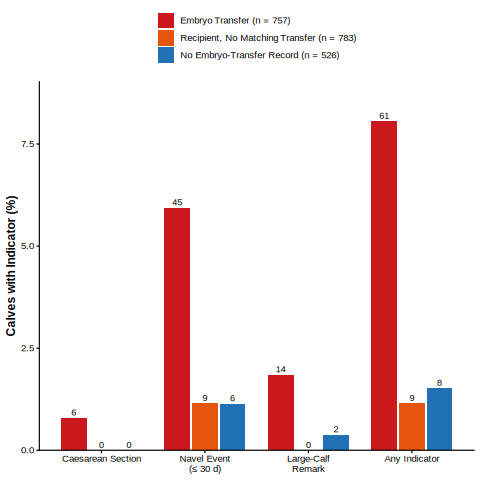

In [ ]:
%%R
# Case-definition check (Methods 2.2, Figure 1). Singletons born within the outcome-recording window, in three groups:
#  - calves from a pregnancy-confirmed embryo transfer (linked above, implied gestation 250-310 d);
#  - calves of recipients that appear in the ET records but without a matching transfer (most likely conceived by
#    insemination): same cows, different route of conception;
#  - calves of cows without ET records.
preg_calves <- unique(df_all_transfers_LOS$calf_ID[!is.na(df_all_transfers_LOS$embryo_transfer_date)])
et_win <- df_joined %>%
  filter(recipient_calving_date >= as.Date("2023-01-01"), recipient_calving_date <= as.Date("2024-12-23")) %>%
  filter(!grepl("/|TWIN|^FF|^MM|TRIPLET", toupper(calf_gender_remark))) %>%
  group_by(calf_ID) %>%
  summarise(dam_in_et = any(ET_status == "ET"), calving = min(recipient_calving_date),
            LOS = max(LOS_final, na.rm = TRUE), cs = max(caesarean_binary, na.rm = TRUE),
            navel = max(navel_treatment_binary, na.rm = TRUE), remark = max(LOS_remark_indicator, na.rm = TRUE),
            .groups = "drop") %>%
  mutate(across(c(LOS, cs, navel, remark), ~ ifelse(is.finite(.x), .x, 0)),
         group = factor(dplyr::case_when(calf_ID %in% preg_calves ~ "Embryo Transfer",
                                         dam_in_et ~ "Recipient, No Matching Transfer",
                                         TRUE ~ "No Embryo-Transfer Record"),
                        levels = c("Embryo Transfer", "Recipient, No Matching Transfer", "No Embryo-Transfer Record")),
         late = calving >= as.Date("2024-07-01"))
et_tab <- et_win %>% group_by(Group = group) %>%
  summarise(calves = n(), events = sum(LOS == 1), c_sections = sum(cs == 1), navel = sum(navel == 1),
            remarks = sum(remark == 1), .groups = "drop") %>%
  mutate(pct = round(100 * events / calves, 1))
print(et_tab)
SaveTab(et_tab, "Table_ETvsNonET_CaseDefinition")
# embryo transfer vs no ET record: crude (Fisher) and stratified by recording period (exact Mantel-Haenszel)
et_cmp <- et_win %>% dplyr::filter(group != "Recipient, No Matching Transfer") %>%
  dplyr::mutate(et = factor(group == "Embryo Transfer", c(TRUE, FALSE)), ev = factor(LOS == 1, c(TRUE, FALSE)))
et_fisher <- fisher.test(table(et_cmp$et, et_cmp$ev))
et_mh <- mantelhaen.test(table(et_cmp$et, et_cmp$ev, et_cmp$late), exact = TRUE)
cat(sprintf("Embryo transfer vs no ET record: OR %.2f (95%% CI %.2f-%.2f), P = %.2g | stratified by recording period: MH OR %.2f (%.2f-%.2f), P = %.2g\n",
            et_fisher$estimate, et_fisher$conf.int[1], et_fisher$conf.int[2], et_fisher$p.value,
            et_mh$estimate, et_mh$conf.int[1], et_mh$conf.int[2], et_mh$p.value))

fig1_df <- et_tab %>%
  tidyr::pivot_longer(c(c_sections, navel, remarks, events), names_to = "Indicator", values_to = "Count") %>%
  mutate(Indicator = factor(Indicator, levels = c("c_sections", "navel", "remarks", "events"),
                            labels = c("Caesarean Section", "Navel Event\n(≤ 30 d)", "Large-Calf\nRemark", "Any Indicator")),
         Label = factor(paste0(Group, " (n = ", format(calves, big.mark = ",", trim = TRUE), ")"),
                        levels = unique(paste0(Group, " (n = ", format(calves, big.mark = ",", trim = TRUE), ")"))),
         Pct = 100 * Count / calves)
p_fig1 <- ggplot(fig1_df, aes(x = Indicator, y = Pct, fill = Label)) +
  geom_col(position = position_dodge(width = 0.8), width = 0.75) +
  geom_text(aes(label = Count), position = position_dodge(width = 0.8), vjust = -0.4, size = 3.2) +
  scale_fill_manual(values = c(COL_RED, COL_ORANGE, COL_BLUE), name = NULL) +
  scale_y_continuous(expand = expansion(mult = c(0, 0.12))) +
  labs(title = "LOS-Compatible Indicators by Calf Origin",
       x = NULL, y = "Calves with Indicator (%)") +
  theme_los() + theme(legend.position = "top", legend.direction = "vertical")
SaveFig(p_fig1, "Fig01_IndicatorsByCalfOrigin", width = 7, height = 5)
print(p_fig1)

## Joining Donor and Recipient Birthdates

In [ ]:
%%R
#Join all_transfers_LOS with donors and recipient birthdates
df_all_transfers_LOS_bdates <- df_all_transfers_LOS %>%
  dplyr::left_join(df_recipient_birthdates, by = "recipient_ID") %>%
  dplyr::left_join(df_farm_donor_birthdates, by = "donor_ID") %>%
  dplyr::arrange(desc(caesarean_binary))

glimpse(df_all_transfers_LOS_bdates)
table(df_all_transfers_LOS$LOS_final)

Rows: 6,202
Columns: 36
$ calf_ID                               <chr> "26234", "26437", "26660", "2681…
$ recipient_ID                          <chr> "24138", "24299", "24593", "2477…
$ recipient_calving_date                <date> 2023-07-18, 2023-09-25, 2023-12…
$ dam_ID                                <dbl> 23551, 24207, 1789, 3952, 24832,…
$ navel_indicator                       <lgl> NA, NA, NA, NA, TRUE, NA, TRUE, …
$ navel_workup                          <lgl> NA, NA, NA, NA, FALSE, NA, FALSE…
$ navel_abx                             <lgl> NA, NA, NA, NA, TRUE, NA, TRUE, …
$ caesarean_binary                      <dbl> 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0,…
$ caesarean_indicator                   <lgl> TRUE, TRUE, TRUE, TRUE, TRUE, TR…
$ caesarean_remark                      <chr> "CSECTION", "CSECTION", "CSECTIO…
$ navel_treatment_binary                <dbl> 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1,…
$ LOS_positive                          <dbl> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,…
$ calf_gender_re

In [ ]:
%%R

df_all_transfers_LOS_bdates <- df_all_transfers_LOS_bdates %>%
  mutate(
    donor_ID = as.character(donor_ID),
    donor_ID = str_replace_all(donor_ID, "[/,\n]", "|||"),
    donor_ID = str_replace_all(donor_ID, "(\\d)\\s+(\\d)", "\\1|||\\2"),

    sire_ID = toupper(str_trim(as.character(sire_ID)))
  ) %>%
  #split
  separate_rows(donor_ID, sep = "\\|\\|\\|") %>%
  #clean
  mutate(
    donor_ID = str_squish(donor_ID),
    # Remove.0
    donor_ID = str_replace_all(donor_ID, "\\.0$", "")
  ) %>%
  # Remove any empty rows before lab join
  filter(
    !is.na(donor_ID) & donor_ID != "",
    !is.na(sire_ID) & sire_ID != "",
    !is.na(embryo_transfer_date)
  )
glimpse(df_all_transfers_LOS_bdates)

# Resolve the genetic dam. dam_ID (DID in the calf file) is the calf's own dam when it is a
# single laboratory donor; for pooled lots it is a concatenation (e.g. 788890933 = 11788/11890/11933) and
# 99999 marks purchased/external embryos without laboratory records.
lab_donor_numbers <- unique(lab_data$donor_number)
df_all_transfers_LOS_bdates <- df_all_transfers_LOS_bdates %>%
  dplyr::mutate(dam_ID_chr = sub("\\.0$", "", format(dam_ID, scientific = FALSE, trim = TRUE)),
                external_embryo = dam_ID_chr == "99999",
                dam_resolved = dam_ID_chr %in% lab_donor_numbers) %>%
  dplyr::group_by(calf_ID) %>%
  dplyr::mutate(any_dam_match = any(donor_ID == dam_ID_chr)) %>%
  dplyr::ungroup() %>%
  dplyr::filter(!(dam_resolved & any_dam_match) | donor_ID == dam_ID_chr) %>%
  dplyr::filter(!external_embryo)
cat("rows after dam resolution:", nrow(df_all_transfers_LOS_bdates), " calves:", dplyr::n_distinct(df_all_transfers_LOS_bdates$calf_ID), "\n")


Rows: 3,127
Columns: 36
$ calf_ID                               <chr> "26234", "26234", "26234", "2643…
$ recipient_ID                          <chr> "24138", "24138", "24138", "2429…
$ recipient_calving_date                <date> 2023-07-18, 2023-07-18, 2023-07…
$ dam_ID                                <dbl> 23551, 23551, 23551, 24207, 2420…
$ navel_indicator                       <lgl> NA, NA, NA, NA, NA, NA, NA, NA, …
$ navel_workup                          <lgl> NA, NA, NA, NA, NA, NA, NA, NA, …
$ navel_abx                             <lgl> NA, NA, NA, NA, NA, NA, NA, NA, …
$ caesarean_binary                      <dbl> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,…
$ caesarean_indicator                   <lgl> TRUE, TRUE, TRUE, TRUE, TRUE, TR…
$ caesarean_remark                      <chr> "CSECTION", "CSECTION", "CSECTIO…
$ navel_treatment_binary                <dbl> 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0,…
$ LOS_positive                          <dbl> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,…
$ calf_gender_re

In [ ]:
%%R
#Simplify the dataset, remove columns that contain almost all NAs
farm_data <- df_all_transfers_LOS_bdates %>%
  dplyr::select(-preg_open_status,
                -approx_recipient_calving_date_minus_7,
                -approx_recipient_calving_date_plus_7,
                -caesarean_remark,
                -donor_sire_ID,
                -donor_birth_date, #The lab data has this information
  )

glimpse(farm_data)
table(farm_data$LOS_final,
      useNA = "always")

Rows: 1,603
Columns: 34
$ calf_ID                       <chr> "26234", "26437", "26660", "26817", "268…
$ recipient_ID                  <chr> "24138", "24299", "24593", "24779", "247…
$ recipient_calving_date        <date> 2023-07-18, 2023-09-25, 2023-12-12, 202…
$ dam_ID                        <dbl> 23551, 24207, 1789, 3952, 24832, 25175, …
$ navel_indicator               <lgl> NA, NA, NA, NA, TRUE, NA, TRUE, TRUE, TR…
$ navel_workup                  <lgl> NA, NA, NA, NA, FALSE, NA, FALSE, FALSE,…
$ navel_abx                     <lgl> NA, NA, NA, NA, TRUE, NA, TRUE, TRUE, TR…
$ caesarean_binary              <dbl> 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0…
$ caesarean_indicator           <lgl> TRUE, TRUE, TRUE, TRUE, TRUE, TRUE, NA, …
$ navel_treatment_binary        <dbl> 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1…
$ LOS_positive                  <dbl> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1…
$ calf_gender_remark            <chr> "F-ET", "FET", "FET", "FET", "FET", "FET…
$ LOS_remark_ind

In [ ]:
%%R
#Export to csv
write.csv(farm_data, file.path(OutDir, "farm_data.csv"), row.names = FALSE)

## Lab and farm data joins

In [ ]:
%%R

# Each calf is matched to the laboratory lots of its donor and sire produced on or before the transfer date
# (inequality join) and keeps the most recent one; frozen-storage time and the number of candidate lots
# (linkage ambiguity) are kept for the sensitivity analyses.
lab_farm_data <- farm_data %>%
  dplyr::left_join(
      lab_data,
      by = dplyr::join_by(donor_ID == donor_number, sire_ID == sire_ID, embryo_transfer_date >= embryo_collection_date),
      keep = TRUE, suffix = c(".x", ".y"), relationship = "many-to-many") %>%
  mutate(date_diff = as.numeric(embryo_transfer_date - embryo_collection_date)) %>%
  group_by(calf_ID) %>%
  mutate(n_candidate_lots = dplyr::n_distinct(embryo_lot[!is.na(embryo_lot)])) %>%
  slice_min(date_diff, n = 1, with_ties = FALSE) %>%
  ungroup() %>%
  rename(storage_days = date_diff)

glimpse(lab_farm_data)
table(lab_farm_data$LOS_final)

Rows: 1,501
Columns: 105
$ calf_ID                                         <chr> "1292", "1365", "1383"…
$ recipient_ID                                    <chr> "24057", "24461", "244…
$ recipient_calving_date                          <date> 2023-06-06, 2023-10-1…
$ dam_ID                                          <dbl> 23719, 23719, 24222, 6…
$ navel_indicator                                 <lgl> NA, NA, NA, NA, NA, NA…
$ navel_workup                                    <lgl> NA, NA, NA, NA, NA, NA…
$ navel_abx                                       <lgl> NA, NA, NA, NA, NA, NA…
$ caesarean_binary                                <dbl> 0, 0, 0, 0, 0, 0, 0, 0…
$ caesarean_indicator                             <lgl> NA, NA, NA, NA, NA, NA…
$ navel_treatment_binary                          <dbl> 0, 0, 0, 0, 0, 0, 0, 0…
$ LOS_positive                                    <dbl> 0, 0, 0, 0, 0, 0, 0, 0…
$ calf_gender_remark                              <chr> "M-ET", "M-ET", "MET",…
$ LOS_remark_in

# Analysis cohort
Laboratory-linked singleton calves, outcome components, and the outcome-recording window.

In [ ]:
%%R
# Analysis cohort
# Outcome sources and the periods they cover: navel events 14 Jan 2023 - 23 Dec 2024; caesarean sections
# 1 Feb 2023 - 27 Sep 2024; calving remarks 1 Jan 2023 - 3 Mar 2025. Calves born after a source stopped being
# recorded would be counted as unaffected, so the main analysis is restricted to calvings up to 23 Dec 2024
# (`in_window`). Calves born later are kept in `lab_farm_all` only for the sensitivity analysis of this choice.
start_date <- as.Date("2023-01-01")
end_date   <- as.Date("2024-12-23")

lf_linked <- lab_farm_data %>% filter(!is.na(embryo_lot))                               # laboratory-linked calves
lf_2023   <- lf_linked %>% filter(recipient_calving_date >= start_date)                      # born from 2023
lab_farm_data <- lf_2023 %>%
  mutate(is_twin_flag = grepl("/|TWIN|^FF|^MM|TRIPLET", toupper(calf_gender_remark))) %>%
  filter(!is_twin_flag) %>%                                                              # singletons only
  mutate(
    in_window     = recipient_calving_date <= end_date,
    rec_period    = factor(ifelse(recipient_calving_date >= as.Date("2024-07-01"), "intensive", "early"),
                           levels = c("early", "intensive")),
    donor_cluster = ifelse(dam_resolved, paste0("D", dam_ID_chr), paste0("L", embryo_lot)),
    # outcome components, kept for the sensitivity analyses
    ev_navel        = as.integer(navel_treatment_binary == 1),
    ev_navel_workup = as.integer(navel_workup %in% TRUE),
    ev_csec         = as.integer(caesarean_binary == 1),
    ev_remark       = as.integer(LOS_remark_indicator == 1),
    ev_strict       = as.integer(ev_csec == 1 | ev_remark == 1 | ev_navel_workup == 1)
  )

n_sires_window <- dplyr::n_distinct(lab_farm_data$sire_ID.x[lab_farm_data$in_window])

# Derivation of the analysis set (Supplementary Table S1)
ev <- function(d) sum(as.numeric(as.character(d$LOS_final)) == 1, na.rm = TRUE)
flow_tab <- data.frame(
  Step = c("Calves registered in the farm file", "With a recipient (dam) identity",
           "Linked to a pregnancy-confirmed embryo transfer (gestation 250-310 d)",
           "Genetic dam resolved; purchased/external embryos excluded", "Linked to a laboratory lot",
           "Born from 1 January 2023", "Singletons", "Born within the outcome-recording window (to 23 December 2024)"),
  Calves = c(nrow(df_calf_damIDs), dplyr::n_distinct(df_joined$calf_ID),
             dplyr::n_distinct(df_all_transfers_LOS$calf_ID[!is.na(df_all_transfers_LOS$embryo_transfer_date)]),
             dplyr::n_distinct(farm_data$calf_ID), nrow(lf_linked), nrow(lf_2023), nrow(lab_farm_data), sum(lab_farm_data$in_window)),
  Events = c(NA, ev(dplyr::distinct(df_joined, calf_ID, .keep_all = TRUE)),
             ev(dplyr::distinct(dplyr::filter(df_all_transfers_LOS, !is.na(embryo_transfer_date)), calf_ID, .keep_all = TRUE)),
             ev(dplyr::distinct(farm_data, calf_ID, .keep_all = TRUE)), ev(lf_linked), ev(lf_2023), ev(lab_farm_data),
             ev(lab_farm_data[lab_farm_data$in_window, ])))
print(flow_tab, row.names = FALSE)
SaveTab(flow_tab, "TableS1_DerivationOfAnalysisSet")

# Recording intensity: navel events per calendar month (whole farm) and calvings per quarter
navel_month <- df_raw_navel_treatements %>% dplyr::mutate(d = as.Date(Date, format = "%m/%d/%Y")) %>%
  dplyr::filter(d >= as.Date("2023-01-01"), d <= as.Date("2024-12-31")) %>% dplyr::count(month = format(d, "%Y-%m"))
navel_month <- data.frame(month = format(seq(as.Date("2023-01-01"), as.Date("2024-12-01"), by = "month"), "%Y-%m")) %>%
  dplyr::left_join(navel_month, by = "month") %>% dplyr::mutate(n = dplyr::coalesce(n, 0L))
cat("Navel events per month: Jan 2023-Jun 2024", paste(range(navel_month$n[navel_month$month < "2024-07"]), collapse = "-"),
    "| Jul-Dec 2024", paste(range(navel_month$n[navel_month$month >= "2024-07"]), collapse = "-"), "\n")
cd <- df_calf_damIDs$recipient_calving_date; cd <- cd[!is.na(cd) & cd >= as.Date("2023-01-01") & cd <= as.Date("2024-12-31")]
calv_q <- table(paste(format(cd, "%Y"), quarters(cd)))
cat("Calvings per quarter, 2023-2024:", paste(range(calv_q), collapse = "-"), "\n")

# Events by half-year of calving: shows why calves born after the outcome files ended cannot be used
calving_period_tab <- lab_farm_data %>%
  mutate(half_year = paste0(format(recipient_calving_date, "%Y"), " H",
                            ifelse(as.integer(format(recipient_calving_date, "%m")) <= 6, 1, 2))) %>%
  group_by(half_year) %>%
  summarise(calves = n(), events = sum(LOS_final == 1), pct = round(100 * mean(LOS_final == 1), 1),
            navel_events = sum(ev_navel), caesarean_sections = sum(ev_csec), large_calf_remarks = sum(ev_remark),
            in_window = ifelse(all(in_window), "Yes", ifelse(any(in_window), "To 23 December", "No")), .groups = "drop")
print(calving_period_tab)
SaveTab(calving_period_tab, "TableS_EventsByCalvingPeriod")
cat("All laboratory-linked singletons from 2023:", nrow(lab_farm_data), "calves,", sum(lab_farm_data$LOS_final == 1),
    "events | within the recording window:", sum(lab_farm_data$in_window), "calves,",
    sum(lab_farm_data$LOS_final[lab_farm_data$in_window] == 1), "events\n")

                                                                  Step Calves
                                    Calves registered in the farm file   6223
                                       With a recipient (dam) identity   6202
 Linked to a pregnancy-confirmed embryo transfer (gestation 250-310 d)   1638
             Genetic dam resolved; purchased/external embryos excluded   1501
                                            Linked to a laboratory lot   1386
                                              Born from 1 January 2023   1030
                                                            Singletons   1017
        Born within the outcome-recording window (to 23 December 2024)    652
 Events
     NA
     85
     65
     61
     57
     57
     57
     54


Navel events per month: Jan 2023-Jun 2024 0-4 | Jul-Dec 2024 8-25 
Calvings per quarter, 2023-2024: 222-363 
# A tibble: 6 × 8
  half_year calves events   pct navel_events caesarean_sections
  <chr>      <int>  <int> <dbl>        <int>              <int>
1 2023 H1       89      4   4.5            0                  0
2 2023 H2      148      5   3.4            1                  3
3 2024 H1      144      8   5.6            3                  2
4 2024 H2      288     38  13.2           35                  0
5 2025 H1      295      2   0.7            0                  0
6 2025 H2       53      0   0              0                  0
# ℹ 2 more variables: large_calf_remarks <int>, in_window <chr>


All laboratory-linked singletons from 2023: 1017 calves, 57 events | within the recording window: 652 calves, 54 events


## Feature engineering

In [ ]:
%%R

# Cluster identifiers are kept aside (not used as predictors) for grouped splitting and cluster-robust standard errors
cluster_df <- lab_farm_data %>% dplyr::transmute(donor_cluster, embryo_lot)
lab_farm_data <- lab_farm_data %>%
  dplyr::mutate(
    LOS_final = factor(LOS_final, levels = c(0, 1),
                       labels = c("Healthy", "LOS")),
    is_pooled_batch = factor(ifelse(grepl("|||", dam_boviteq_number, fixed = TRUE),
                                    "Yes", "No"))
  ) %>%
  dplyr::select(-c(
    calf_ID, recipient_ID, donor_ID.x,
    sire_ID.x, dam_complete_name,
    dam_registration_number, sire_a_complete_name,
    embryo_lot, caesarean_indicator,
    navel_indicator, LOS_positive, LOS_remark_indicator,
    donor_level, follicles_1_4_mm, follicles_greater_than_15_mm
  )) %>%
  dplyr::mutate(
    dplyr::across(c(
      `0_to_2_layers_of_cumulus`, greater_than_or_equal_to_3_layers_of_cumulus,
      degenerated_oocytes, coasting_duration, total_aspirated_follicles,
      follicles_5_6_mm, follicles_7_10_mm, follicles_11_15_mm
    ), as.numeric),
    dam_birth_date         = as.Date(dam_birth_date),
    dam_age_at_opu_months  = as.numeric(stringr::str_extract(dam_age_at_opu, "\\d+")),
    embryo_age             = as.numeric(as.character(embryo_age)),
    embryo_age             = ifelse(embryo_age > 20, NA, embryo_age),
    embryo_grade           = as.factor(embryo_grade),
    lab                    = as.factor(lab),
    sire_a_semen_type      = as.factor(sire_a_semen_type),
    embryo_transfer_date   = as.Date(embryo_transfer_date),
    recipient_bred_date    = as.Date(recipient_bred_date),
    recipient_calving_date = as.Date(recipient_calving_date),
    recipient_birthdate    = as.Date(recipient_birthdate)
  )

str(lab_farm_data)
summary(lab_farm_data)

tibble [1,017 × 101] (S3: tbl_df/tbl/data.frame)
 $ recipient_calving_date                         : Date[1:1017], format: "2023-06-06" "2023-10-15" ...
 $ dam_ID                                         : num [1:1017] 23719 23719 24222 6288 24548 ...
 $ navel_workup                                   : logi [1:1017] NA NA NA NA NA NA ...
 $ navel_abx                                      : logi [1:1017] NA NA NA NA NA NA ...
 $ caesarean_binary                               : num [1:1017] 0 0 0 0 0 0 0 0 0 0 ...
 $ navel_treatment_binary                         : num [1:1017] 0 0 0 0 0 0 0 0 0 0 ...
 $ calf_gender_remark                             : chr [1:1017] "M-ET" "M-ET" "MET" "MET" ...
 $ LOS_final                                      : Factor w/ 2 levels "Healthy","LOS": 1 1 1 1 1 1 1 1 1 1 ...
 $ ET_status                                      : chr [1:1017] "ET" "ET" "ET" "ET" ...
 $ recipient_bred_date                            : Date[1:1017], format: "2022-09-06" "2023-01-15"

In [ ]:
%%R
#features
#Embryo–recipient synchrony
lab_farm_data <- lab_farm_data %>%
  mutate(
    days_between_heat_and_transfer =
      as.numeric(embryo_transfer_date - recipient_bred_date),

    embryo_sync =
      embryo_age - days_between_heat_and_transfer,

    sync_abs = abs(embryo_sync),

    sync_category = case_when(
      sync_abs == 0 ~ "perfect",
      sync_abs == 1 ~ "moderate",
      sync_abs >= 2 ~ "poor",
      TRUE ~ NA_character_
    )
  )

#Recipient age before giving birth
lab_farm_data <- lab_farm_data %>%
  mutate(
    recipient_age_days =
      as.numeric(recipient_calving_date - recipient_birthdate),

    recipient_age_years = recipient_age_days / 365
  )

#Seasonal effect
lab_farm_data <- lab_farm_data %>%
  mutate(
    transfer_month = as.numeric(format(embryo_transfer_date, "%m")),
    season = case_when(
      transfer_month %in% c(12,1,2) ~ "winter",
      transfer_month %in% c(3,4,5) ~ "spring",
      transfer_month %in% c(6,7,8) ~ "summer",
      TRUE ~ "fall"
    )
  )

#Embryo quality ratios
lab_farm_data <- lab_farm_data %>%
  mutate(
    cleavage_rate = number_of_cleaved_embryos / total_structures_found,
    viability_rate = number_of_viable_embryos / total_structures_found,
    morula_rate = number_of_morulas / total_structures_found
  )

#Follicle distribution
lab_farm_data <- lab_farm_data %>%
  mutate(
    small_follicles = follicles_5_6_mm,
    large_follicles = follicles_11_15_mm,
    follicle_ratio = large_follicles / (small_follicles + 1) #follicle ratio
  )

#Oocyte Quality Ratio
lab_farm_data <- lab_farm_data %>%
  mutate(
    prop_good_cumulus =
      greater_than_or_equal_to_3_layers_of_cumulus / total_structures_found,

    prop_poor_cumulus =
      `0_to_2_layers_of_cumulus` / total_structures_found,

    cumulus_ratio =
      greater_than_or_equal_to_3_layers_of_cumulus /
      (`0_to_2_layers_of_cumulus` + 1)
  )

#Maturation to Fertilisation Time Ratio
lab_farm_data <- lab_farm_data %>%
  mutate(
    total_lab_time =
      in_vitro_maturation_duration +
      in_vitro_fertilisation_duration,

    maturation_to_fertilisation_ratio =
      in_vitro_maturation_duration /
      (in_vitro_fertilisation_duration + 1)
  )

  #efficiency
  lab_farm_data <- lab_farm_data %>%
  mutate(
    embryos_per_oocyte =
      number_of_viable_embryos / oocytes_in_maturation,

    cleavage_per_oocyte =
      number_of_cleaved_embryos / oocytes_in_maturation
  )

  #sire birth year
  lab_farm_data <- lab_farm_data %>%
  mutate(
    sire_birth_year = as.integer(format(as.Date(.data$sire_a_birth_date), "%Y"))
  )

  #embryo density
  lab_farm_data <- lab_farm_data %>%
  mutate(
    embryos_per_transfer = number_of_viable_embryos,
    embryo_density =
      number_of_viable_embryos / (days_between_heat_and_transfer + 1)
  )
#exclude FSH NA values (since it is showing up in the models)
lab_farm_data <- lab_farm_data %>%
  mutate(
    spo_program = dplyr::case_when(
      is.na(.data$spo_program) ~ "Unknown",
      trimws(as.character(.data$spo_program)) == "" ~ "Unknown",
            .data$spo_program == "P180F" ~ "1.5 cc FSH x 6",
      .data$spo_program == "P240F" ~ "2 cc FSH x 6",
      .data$spo_program == "P300F" ~ "2.5 cc FSH x 6",
      TRUE ~ as.character(.data$spo_program)
    ),
    spo_program = as.factor(.data$spo_program)
  )

lab_farm_data <- lab_farm_data %>%
  mutate(
    age_sync_interaction =
      recipient_age_years * sync_abs,

    embryo_age_vs_recipient_age =
      embryo_age / (recipient_age_years + 1)
  )

 #season sync
  lab_farm_data <- lab_farm_data %>%
  mutate(
    season_sync =
      interaction(season, sync_category)
  )

  #embryo grade
  lab_farm_data <- lab_farm_data %>%
  mutate(
    embryo_grade = as.character(.data$embryo_grade),
    embryo_grade = dplyr::if_else(
      .data$embryo_grade %in% c("1", "2"),
      .data$embryo_grade,
      NA_character_
    ),
    embryo_grade = factor(.data$embryo_grade, levels = c("1", "2"))
  )

#cleanup
lab_farm_data <- lab_farm_data %>%
  mutate(
    caesarean_binary = as.factor(caesarean_binary),
    navel_treatment_binary = as.factor(navel_treatment_binary),
    sync_category = as.factor(sync_category),
    season = as.factor(season),
    #convert transfer_month to a regular factor
    transfer_month = as.factor(as.character(transfer_month)),
     sire_age_missing = if_else(is.na(sire_a_age_at_semen_collection), 1, 0),
    sire_a_age_at_semen_collection = if_else(
      is.na(sire_a_age_at_semen_collection),
      median(sire_a_age_at_semen_collection, na.rm = TRUE),
      sire_a_age_at_semen_collection
  ))
  #creating a coloumn for gender and twins
  lab_farm_data <- lab_farm_data %>%
  mutate(
    calf_gender = case_when(
      grepl("^M|^m|/M", calf_gender_remark) ~ "Male",
      grepl("^F|^f|/F", calf_gender_remark) ~ "Female",
      TRUE ~ NA_character_
    ),

    #Keep twins separate because a Male Twin is different from a Male Single
    is_twin = if_else(
      grepl("/|TWIN|FF|MM", calf_gender_remark, ignore.case = TRUE), "Twin", "Single"
    )
  ) %>%
  mutate(
    calf_gender = as.factor(calf_gender),
    is_twin = as.factor(is_twin)
  )
#factor conversion
lab_farm_data$cumulus_expansion_post_maturation <-
  factor(lab_farm_data$cumulus_expansion_post_maturation)

str(lab_farm_data)
summary(lab_farm_data)


# Verified laboratory variables
# "in_vitro_maturation_time", "in_vitro_fertilisation_time" and "stripping_time" are the clock times
# (minutes after midnight) at which maturation, fertilisation and denudation began; the durations are separate
# fields. The identities below, checked on every OPU session in the laboratory files, confirm this:
# IVM duration = 1,440 - IVM start + IVF start; IVF duration = 1,440 - IVF start + denudation time.
sessions <- lab_data %>%
  dplyr::distinct(embryo_lot, in_vitro_maturation_time, in_vitro_fertilisation_time, stripping_time,
                  in_vitro_maturation_duration, in_vitro_fertilisation_duration) %>%
  dplyr::mutate(dplyr::across(-embryo_lot, ~ suppressWarnings(as.numeric(.x))))
chk_ivm <- with(sessions, in_vitro_maturation_duration == 1440 - in_vitro_maturation_time + in_vitro_fertilisation_time)
chk_ivf <- with(sessions, in_vitro_fertilisation_duration == 1440 - in_vitro_fertilisation_time + stripping_time)
cat("OPU sessions:", nrow(sessions), "| IVM identity holds in", sum(chk_ivm, na.rm = TRUE), "of", sum(!is.na(chk_ivm)),
    "| IVF identity holds in", sum(chk_ivf, na.rm = TRUE), "of", sum(!is.na(chk_ivf)), "sessions with complete fields\n")
lab_farm_data <- lab_farm_data %>%
  mutate(
    ivm_duration_h = in_vitro_maturation_duration / 60,
    ivf_duration_h = in_vitro_fertilisation_duration / 60,
    viable_embryos_per_session = number_of_viable_embryos,   # viable embryos produced per OPU session
    donor_age_le9 = factor(ifelse(dam_age_at_opu_months <= 9, "le9", "gt9"), levels = c("gt9", "le9")),
    # grades other than A are sparse; collapsed to A vs other
    cumulus_expansion_post_maturation = factor(ifelse(cumulus_expansion_post_maturation == "A", "A", "other"))
  )
# embryo_age holds the IETS stage code (4-8) recorded on the transfer sheet, not the age of the embryo in days

tibble [1,017 × 131] (S3: tbl_df/tbl/data.frame)
 $ recipient_calving_date                         : Date[1:1017], format: "2023-06-06" "2023-10-15" ...
 $ dam_ID                                         : num [1:1017] 23719 23719 24222 6288 24548 ...
 $ navel_workup                                   : logi [1:1017] NA NA NA NA NA NA ...
 $ navel_abx                                      : logi [1:1017] NA NA NA NA NA NA ...
 $ caesarean_binary                               : Factor w/ 2 levels "0","1": 1 1 1 1 1 1 1 1 1 1 ...
 $ navel_treatment_binary                         : Factor w/ 2 levels "0","1": 1 1 1 1 1 1 1 1 1 1 ...
 $ calf_gender_remark                             : chr [1:1017] "M-ET" "M-ET" "MET" "MET" ...
 $ LOS_final                                      : Factor w/ 2 levels "Healthy","LOS": 1 1 1 1 1 1 1 1 1 1 ...
 $ ET_status                                      : chr [1:1017] "ET" "ET" "ET" "ET" ...
 $ recipient_bred_date                            : Date[1:1017], for

## Analysis dataset and descriptive statistics

In [ ]:
%%R
# Analysis dataset
# Excluded: identifiers and dates, outcome components, raw counts replaced by proportions, clock times
# (replaced by durations), mislabelled or duplicate variables, the synchrony variable (derived from the IETS
# stage code rather than embryo age), post-calving information (gestation length) and linkage helpers.
exclude_vars <- c(
  "recipient_calving_date", "approx_recipient_calving_date",
  "donor_number", "laboratory", "collection_site",
  "dam's_owner_complete_name", "navel_treatment_binary", "caesarean_binary",
  "calf_gender_remark", "sire_a_semen_lot", "dam_boviteq_number", "dam_ID",
  "boviteq_lab_ID", "performed_by", "sire_a_registration_number", "sire_a_semen_code",
  "recipient_bred_date", "embryo_transfer_date", "opu_date", "insemination_date",
  "embryo_collection_date", "flush_date", "dam_birth_date", "recipient_birthdate",
  "total_structures_found", "cleavage_percent", "morulas_percent",
  "embryos_percent", "days_between_heat_and_transfer", "preg_open_binary",
  "dam's_owner_short_name", "recipient_age_days", "dam_age_at_opu",
  "total_aspirated_follicles", "small_follicles", "large_follicles",
  "follicles_5_6_mm", "follicles_7_10_mm", "follicles_11_15_mm",
  "oocytes_in_maturation", "0_to_2_layers_of_cumulus",
  "greater_than_or_equal_to_3_layers_of_cumulus", "degenerated_oocytes",
  "number_of_cleaved_embryos", "number_of_morulas", "number_of_viable_embryos",
  "good_quality_morulas", "poor_quality_morulas", "potentially_freezable_embryos",
  "total_discarded", "total_frozens",
  "viability_rate", "morula_rate", "predictions_of_viable_embryos",
  "prop_poor_cumulus", "cleavage_rate", "transfer_day_of_week", "season_sync",
  "sire_a_age_at_semen_collection", "transfer_month",
  "sync_abs", "age_sync_interaction", "embryo_age_vs_recipient_age",
  "is_twin", "lab", "sire_a_birth_date",
  "prop_poor_quality", "dam_atq_number",
  "in_vitro_maturation_duration", "in_vitro_fertilisation_duration",
  "is_pooled_batch", "donor_ID.y", "sire_ID.y", "total_lab_time",
  "maturation_to_fertilisation_ratio", "sire_a_breed_code", "lot_number",
  "recipient_heat_time", "sire_age_missing", "embryo_sync", "embryo_density",
  # clock times, mislabelled or replaced variables
  "in_vitro_maturation_time", "in_vitro_fertilisation_time", "stripping_time",
  "cumulus_ratio", "embryos_per_transfer", "sync_category", "recipient_heat_date", "dam_starting_state",
  # post-calving information, linkage helpers, cluster identifiers and outcome components
  "gestation_length", "dam_ID_chr", "external_embryo", "any_dam_match", "dam_resolved",
  "n_candidate_lots", "is_twin_flag", "donor_cluster", "donor_age_le9", "in_window",
  "navel_workup", "navel_abx", "ev_navel", "ev_navel_workup", "ev_csec", "ev_remark", "ev_strict"
)

win <- lab_farm_data$in_window
md_all <- lab_farm_data %>% dplyr::select(-any_of(exclude_vars))
# variables with < 30% missing values and > 1 distinct value WITHIN the analysis window
keep_cols <- names(md_all)[vapply(md_all[win, ], function(x) mean(is.na(x)) < 0.30 && dplyr::n_distinct(x, na.rm = TRUE) > 1, logical(1))]
master_all <- md_all[, keep_cols]
master_all$LOS_final <- factor(ifelse(as.character(master_all$LOS_final) == "LOS", "LOS", "Healthy"), levels = c("Healthy", "LOS"))

# all calvings from 2023 (sensitivity analyses only) and the main analysis set (recording window)
lab_farm_all  <- lab_farm_data
cluster_all   <- cluster_df
master_data   <- master_all[win, ]
lab_farm_data <- lab_farm_data[win, ]
cluster_df    <- cluster_df[win, ]
master_cluster <- cluster_df$donor_cluster
stopifnot(length(master_cluster) == nrow(master_data))

cat("Analysis set:", nrow(master_data), "calves,", sum(master_data$LOS_final == "LOS"), "events,",
    ncol(master_data) - 1, "candidate predictors\n")
cat("Laboratory lots (OPU collection dates):", n_distinct(cluster_df$embryo_lot),
    "| donor clusters:", n_distinct(cluster_df$donor_cluster), "| sires:", n_sires_window, "\n")
print(data.frame(variable = names(master_data)[-1], label = CleanLabel(names(master_data)[-1])), row.names = FALSE)
readr::write_csv(master_data, file.path(OutDir, "analysis_dataset.csv"))

Analysis set: 652 calves, 54 events, 23 candidate predictors
Laboratory lots (OPU collection dates): 51 | donor clusters: 65 | sires: 72 
                                        variable
                                      embryo_age
                                    embryo_grade
                            recipient_cycle_date
                               sire_a_semen_type
                                     spo_program
                               coasting_duration
               cumulus_expansion_post_maturation
 heparin_concentration_in_fertilisation_droplets
                               prop_good_quality
                                    storage_days
                                      rec_period
                           dam_age_at_opu_months
                             recipient_age_years
                                          season
                                  follicle_ratio
                               prop_good_cumulus
                             

# A tibble: 2 × 6
  rec_period calves events   pct fsh_1.5cc_x6 donors_le9_months
  <fct>       <int>  <int> <dbl>        <int>             <int>
1 early         381     17   4.5           47                53
2 intensive     271     37  13.7          203               169
            donor_age_le9
FSH_1.5cc_x6 gt9 le9
       FALSE 362  40
       TRUE   68 182
Outcome components: navel event <= 30 d 39 | caesarean section 5 | large-calf remark 14 | any 54 


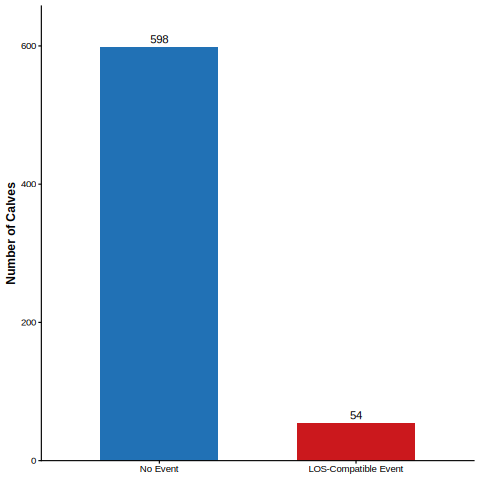

In [ ]:
%%R
# Descriptives: recording period, protocol and donor age (Results 3.1)
y_all <- lab_farm_data$LOS_final == "LOS"
rec_tab <- lab_farm_data %>% mutate(y = LOS_final == "LOS") %>% group_by(rec_period) %>%
  summarise(calves = n(), events = sum(y), pct = round(100 * mean(y), 1),
            fsh_1.5cc_x6 = sum(spo_program == "1.5 cc FSH x 6", na.rm = TRUE),
            donors_le9_months = sum(donor_age_le9 == "le9", na.rm = TRUE), .groups = "drop")
print(rec_tab)
print(with(lab_farm_data, table(FSH_1.5cc_x6 = spo_program == "1.5 cc FSH x 6", donor_age_le9)))
cat("Outcome components: navel event <= 30 d", sum(lab_farm_data$ev_navel), "| caesarean section", sum(lab_farm_data$ev_csec),
    "| large-calf remark", sum(lab_farm_data$ev_remark), "| any", sum(y_all), "\n")

inc_df <- tibble::tibble(Outcome = factor(ifelse(y_all, "LOS-Compatible Event", "No Event"),
                                          levels = c("No Event", "LOS-Compatible Event")))
p_inc <- ggplot(inc_df, aes(x = Outcome, fill = Outcome)) +
  geom_bar(width = 0.6) +
  geom_text(stat = "count", aes(label = after_stat(count)), vjust = -0.5, size = 4) +
  scale_fill_manual(values = c("No Event" = COL_BLUE, "LOS-Compatible Event" = COL_RED), guide = "none") +
  scale_y_continuous(expand = expansion(mult = c(0, 0.1))) +
  labs(title = "Incidence of LOS-Compatible Events",
       subtitle = paste0("n = ", nrow(inc_df), " | ", round(100 * mean(y_all), 1), "%"),
       x = NULL, y = "Number of Calves") +
  theme_los()
SaveFig(p_inc, "Fig02_Incidence", width = 5, height = 4.5)
print(p_inc)

In [ ]:
%%R
# Overlap of the donor and stimulation variables (Results 3; Supplementary Table S9)
# Young donors were mostly stimulated with the 1.5 cc FSH x 6 protocol, and the proportion of oocytes with >= 3
# cumulus layers is a session-level laboratory value; this table shows how far the three variables coincide and the
# proportion of calves with an event by thirds of the cumulus variable within each recording period.
ov <- if (exists("master_data")) master_data else readr::read_csv(file.path(OutDir, "analysis_dataset.csv"), show_col_types = FALSE)
ov <- as.data.frame(ov) %>%
  dplyr::mutate(y = as.character(LOS_final) == "LOS",
                young = ifelse(dam_age_at_opu_months <= 9, "Donor ≤ 9 months", "Donor > 9 months"),
                fsh = ifelse(as.character(spo_program) == "1.5 cc FSH x 6", "1.5 cc FSH × 6", "Other protocols"),
                cum_third = cut(prop_good_cumulus, quantile(prop_good_cumulus, c(0, 1/3, 2/3, 1)), include.lowest = TRUE,
                                labels = c("lower third", "middle third", "upper third")),
                period = ifelse(as.character(rec_period) == "intensive", "from 1 July 2024", "before 1 July 2024"))
med_iqr <- function(x) sprintf("%.2f (%.2f–%.2f)", median(x), quantile(x, 0.25), quantile(x, 0.75))
summ <- function(d, grp) d %>% dplyr::group_by(Group = .data[[grp]]) %>%
  dplyr::summarise(Calves = dplyr::n(), Events = sum(y), `Events (%)` = round(100 * mean(y), 1),
                   `Oocytes with ≥ 3 Cumulus Layers, Median (IQR)` = med_iqr(prop_good_cumulus), .groups = "drop") %>%
  dplyr::mutate(Group = as.character(Group))
overlap_tab <- dplyr::bind_rows(
  summ(ov, "young"),
  summ(ov, "fsh"),
  summ(ov %>% dplyr::mutate(g = paste(young, fsh, sep = ", ")), "g"),
  summ(ov %>% dplyr::mutate(g = paste0("Born ", period, ", cumulus variable in the ", cum_third)), "g"))
print(as.data.frame(overlap_tab), row.names = FALSE)
cat("Cumulus thirds cut at", paste(round(quantile(ov$prop_good_cumulus, c(1/3, 2/3)), 3), collapse = " and "), "\n")
SaveTab(overlap_tab, "TableS_DonorStimulationOverlap")


                                                         Group Calves Events
                                              Donor > 9 months    430     21
                                              Donor ≤ 9 months    222     33
                                                1.5 cc FSH × 6    250     36
                                               Other protocols    402     18
                              Donor > 9 months, 1.5 cc FSH × 6     68      7
                             Donor > 9 months, Other protocols    362     14
                              Donor ≤ 9 months, 1.5 cc FSH × 6    182     29
                             Donor ≤ 9 months, Other protocols     40      4
  Born before 1 July 2024, cumulus variable in the lower third    164      6
 Born before 1 July 2024, cumulus variable in the middle third    114      2
  Born before 1 July 2024, cumulus variable in the upper third    103      9
    Born from 1 July 2024, cumulus variable in the lower third     58      5

In [ ]:
%%R
# Stimulation protocol and donor starting state (Supplementary Table S9, continued)
# Every protocol is shown by recording period, not only the 1.5 cc FSH x 6 contrast used in the pre-specified models;
# donor starting state (progesterone-injected or pregnant at the start of stimulation), not a candidate predictor, is checked.
chk <- as.data.frame(lab_farm_data) %>%
  dplyr::mutate(y = as.integer(as.character(LOS_final) %in% c("1", "LOS")),
                period = ifelse(as.character(rec_period) == "intensive", "From July 2024", "Before July 2024"),
                protocol = gsub(" x ", " × ", as.character(spo_program)),
                young = ifelse(dam_age_at_opu_months <= 9, "Donor ≤ 9 months", "Donor > 9 months"),
                start_state = as.character(dam_starting_state))
rate <- function(d, ...) d %>% dplyr::group_by(...) %>%
  dplyr::summarise(Calves = dplyr::n(), Events = sum(y), `Events (%)` = round(100 * mean(y), 1), .groups = "drop")
firth_chk <- function(d, v) {
  d <- d %>% dplyr::filter(!is.na(.data[[v]]))
  f <- glm(as.formula(paste("y ~", v, "+ rec_period")), data = d, family = binomial, method = "brglmFit")
  ct <- lmtest::coeftest(f, vcov. = sandwich::vcovCL(f, cluster = d$donor_cluster, type = "HC0"))
  r <- ct[grepl(paste0("^", v), rownames(ct)), , drop = FALSE]
  data.frame(Level = sub(paste0("^", v), "", rownames(r)), Calves = nrow(d), Events = sum(d$y),
             `OR (95% CI)` = sprintf("%.2f (%.2f–%.2f)", exp(r[, 1]), exp(r[, 1] - 1.96 * r[, 2]), exp(r[, 1] + 1.96 * r[, 2])),
             P = signif(r[, 4], 2), row.names = NULL, check.names = FALSE)
}
# every protocol by recording period
tab_protocol <- rate(chk, Protocol = protocol, `Recording Period` = period)
print(as.data.frame(tab_protocol), row.names = FALSE)
# donor age and the 1.5 cc protocol within each recording period
print(as.data.frame(rate(chk, `Recording Period` = period, Donor = young,
                         Protocol = ifelse(protocol == "1.5 cc FSH × 6", "1.5 cc FSH × 6", "Other"))), row.names = FALSE)
# donor starting state by recording period, with donor age
tab_state <- chk %>% dplyr::filter(!is.na(start_state)) %>%
  dplyr::group_by(`Starting State` = start_state, `Recording Period` = period) %>%
  dplyr::summarise(Calves = dplyr::n(), Events = sum(y), `Events (%)` = round(100 * mean(y), 1),
                   `Donors ≤ 9 Months (Calves)` = sum(young == "Donor ≤ 9 months"),
                   `Donor Age, Median (Months)` = median(dam_age_at_opu_months), .groups = "drop")
print(as.data.frame(tab_state), row.names = FALSE)
print(table(chk$start_state, chk$protocol, useNA = "ifany"))
# Firth regression with recording period, donor-cluster-robust 95% CI
chk$protocol_grp <- relevel(factor(ifelse(chk$protocol %in% c("1.5 cc FSH × 6", "2 cc FSH × 6", "2.5 cc FSH × 6", "P240F", "P300F"),
                                          chk$protocol, "Other protocols")), ref = "2.5 cc FSH × 6")
s2 <- chk %>% dplyr::filter(start_state %in% c("P4 Injected", "Pregnant")) %>%
  dplyr::mutate(start_state = relevel(factor(start_state), ref = "P4 Injected"))
tab_or <- rbind(
  cbind(Comparison = "Stimulation protocol (reference 2.5 cc FSH × 6)", firth_chk(chk, "protocol_grp")),
  cbind(Comparison = "Donor starting state (reference P4 injected)", firth_chk(s2, "start_state")),
  cbind(Comparison = "Donor starting state, donors > 9 months only", firth_chk(s2 %>% dplyr::filter(young == "Donor > 9 months"), "start_state")))
print(tab_or, row.names = FALSE)
p3 <- chk %>% dplyr::filter(protocol == "P300F")
cat("P300F:", nrow(p3), "calves,", sum(p3$y), "events,", dplyr::n_distinct(p3$donor_cluster), "donor clusters; events per cluster:",
    paste(sort(tapply(p3$y, p3$donor_cluster, sum), decreasing = TRUE), collapse = ", "), "\n")
SaveTab(tab_protocol, "TableS_ProtocolByPeriod")
SaveTab(tab_state, "TableS_DonorStartingState")
SaveTab(tab_or, "TableS_ProtocolStartingStateFirth")


        Protocol Recording Period Calves Events Events (%)
  1.5 cc FSH × 6 Before July 2024     47      5       10.6
  1.5 cc FSH × 6   From July 2024    203     31       15.3
    2 cc FSH × 6 Before July 2024    160      5        3.1
    2 cc FSH × 6   From July 2024     44      2        4.5
 2.25 cc FSH × 6 Before July 2024      3      0        0.0
  2.5 cc FSH × 6 Before July 2024    149      7        4.7
  2.5 cc FSH × 6   From July 2024     14      2       14.3
    3 cc FSH × 6 Before July 2024      4      0        0.0
          Custom Before July 2024     14      0        0.0
          Custom   From July 2024     10      2       20.0
           P350F Before July 2024      4      0        0.0
 Recording Period            Donor       Protocol Calves Events Events (%)
 Before July 2024 Donor > 9 months 1.5 cc FSH × 6     13      1        7.7
 Before July 2024 Donor > 9 months          Other    315     12        3.8
 Before July 2024 Donor ≤ 9 months 1.5 cc FSH × 6     34      4    

In [ ]:
%%R
# Navel-record types before and from July 2024, and cumulus scores of older donors over time
navel_raw <- readr::read_csv(file.path(BASE_DIR, "farm_navel_treatments.csv"), col_types = readr::cols(.default = "c")) %>%
  dplyr::transmute(date = as.Date(trimws(Date), "%m/%d/%Y"), age_d = as.numeric(DIM), remark = toupper(trimws(Remark))) %>%
  dplyr::mutate(period = ifelse(date >= as.Date("2024-07-01"), "From July 2024", "Before July 2024"),
                type = dplyr::case_when(grepl("^(US|ULTRA)", remark) ~ "Ultrasonography",
                                        grepl("^(SURG|SUTURE|WRAP)", remark) ~ "Surgery or wrap",
                                        grepl("^(MONITOR|LGVEIN)", remark) ~ "Other",
                                        TRUE ~ "Antibiotic"))
tab_navel <- navel_raw %>% dplyr::group_by(`Recording Period` = period) %>%
  dplyr::summarise(Records = dplyr::n(), Antibiotic = sum(type == "Antibiotic"), Ultrasonography = sum(type == "Ultrasonography"),
                   `Surgery or Wrap` = sum(type == "Surgery or wrap"), `Calf Age, Median (d)` = median(age_d, na.rm = TRUE), .groups = "drop")
print(as.data.frame(tab_navel), row.names = FALSE)
SaveTab(tab_navel, "TableS_NavelRecordTypes")
cum_ses <- lab_data %>%
  dplyr::mutate(d = as.Date(embryo_collection_date),
                p = as.numeric(greater_than_or_equal_to_3_layers_of_cumulus) / as.numeric(total_structures_found),
                age = as.numeric(stringr::str_extract(as.character(dam_age_at_opu), "\\d+")),
                `Half-Year` = paste0(format(d, "%Y"), ifelse(as.numeric(format(d, "%m")) <= 6, " H1", " H2"))) %>%
  dplyr::filter(!is.na(p), d >= as.Date("2022-01-01"))
tab_cum <- cum_ses %>% dplyr::group_by(`Half-Year`) %>%
  dplyr::summarise(`Donor Lots` = dplyr::n(), `Median, All Donors` = round(median(p), 2),
                   `Donor Lots > 9 Months` = sum(age > 9, na.rm = TRUE), `Median, Donors > 9 Months` = round(median(p[age > 9], na.rm = TRUE), 2),
                   `Share of Donors ≤ 9 Months` = round(mean(age <= 9, na.rm = TRUE), 2), .groups = "drop")
print(as.data.frame(tab_cum), row.names = FALSE)
SaveTab(tab_cum, "TableS_CumulusOverTime")


 Recording Period Records Antibiotic Ultrasonography Surgery or Wrap
 Before July 2024      22         22               0               0
   From July 2024      94         64              20               8
 Calf Age, Median (d)
                   22
                    9


 Half-Year Donor Lots Median, All Donors Donor Lots > 9 Months
   2022 H1         91               0.44                    77
   2022 H2        136               0.35                   130
   2023 H1        124               0.33                   104
   2023 H2        148               0.43                    51
   2024 H1        189               0.37                   110
   2024 H2        182               0.38                   149
   2025 H1         67               0.33                    64
 Median, Donors > 9 Months Share of Donors ≤ 9 Months
                      0.44                       0.15
                      0.35                       0.04
                      0.30                       0.16
                      0.43                       0.66
                      0.35                       0.42
                      0.41                       0.18
                      0.33                       0.04


In [ ]:
%%R
# Registration of calves in the calf file (Limitations; Supplementary Table S1, note)
# Calving remarks on the recipient's record begin with the calf's sex (F/M), contain "ET" for calves from embryo
# transfer and "DOA" for calves dead at birth. Each calving is checked for a calf of that recipient registered in the
# calf file within 3 d of the calving date (outcome-recording window).
calv <- readr::read_csv(file.path(BASE_DIR, "raw_data/farm_calving_records_recipients.csv"),
                        col_types = readr::cols(.default = "c")) %>%
  dplyr::transmute(recipient_ID = sub("^0+", "", trimws(ID)), date = as.Date(trimws(Date), "%m/%d/%Y"),
                   remark = toupper(trimws(Remark))) %>%
  dplyr::filter(date >= as.Date("2023-01-01"), date <= as.Date("2024-12-23"))
reg_calves <- readr::read_csv(file.path(BASE_DIR, "raw_data/calfid_rid.CSV"), col_types = readr::cols(.default = "c")) %>%
  dplyr::transmute(recipient_ID = sub("^0+", "", trimws(RDAM)), bdat = as.Date(trimws(BDAT), "%m/%d/%y")) %>%
  dplyr::filter(!is.na(recipient_ID), recipient_ID != "")
reg <- calv %>% dplyr::left_join(reg_calves, by = "recipient_ID", relationship = "many-to-many") %>%
  dplyr::group_by(recipient_ID, date, remark) %>%
  dplyr::summarise(registered = any(abs(as.numeric(bdat - date)) <= 3, na.rm = TRUE), .groups = "drop") %>%
  dplyr::mutate(sex = substr(remark, 1, 1), et = grepl("ET", remark), doa = grepl("DOA", remark))
tab_reg <- dplyr::bind_rows(
  reg %>% dplyr::filter(!doa, sex %in% c("F", "M")) %>%
    dplyr::mutate(Group = paste(ifelse(et, "Embryo-transfer", "Other"), ifelse(sex == "F", "heifer calves", "bull calves"))) %>%
    dplyr::group_by(Group) %>% dplyr::summarise(Calvings = dplyr::n(), Registered = sum(registered), .groups = "drop"),
  reg %>% dplyr::filter(doa) %>% dplyr::group_by(Group = ifelse(et, "Embryo-transfer calves dead at birth (DOA)", "Other calves dead at birth (DOA)")) %>%
    dplyr::summarise(Calvings = dplyr::n(), Registered = sum(registered), .groups = "drop")) %>%
  dplyr::mutate(`Registered (%)` = round(100 * Registered / Calvings, 1))
print(as.data.frame(tab_reg), row.names = FALSE)
SaveTab(tab_reg, "TableS_CalfRegistration")


New names:
• `` -> `...5`
                                      Group Calvings Registered Registered (%)
                Embryo-transfer bull calves      499        176           35.3
              Embryo-transfer heifer calves      610        574           94.1
                          Other bull calves     1783          1            0.1
                        Other heifer calves     2976       1362           45.8
 Embryo-transfer calves dead at birth (DOA)       44          1            2.3
           Other calves dead at birth (DOA)       96          5            5.2


## Incidence by recording period and data dictionary

In [ ]:
%%R
# Incidence of LOS-compatible events by recording period (exact binomial 95% CI)
# Navel events were recorded at 0-4 per month until June 2024 and at 8-25 per month from July 2024. The
# incidence in each period shows how strongly the measured frequency depends on how intensively signs are recorded.
pct_ci <- function(x, n) { b <- binom.test(x, n)$conf.int; sprintf("%.1f (%.1f–%.1f)", 100 * x / n, 100 * b[1], 100 * b[2]) }
inc_one <- function(d, label) {
  data.frame(Group = label, Calves = nrow(d), Events = sum(d$ev_csec | d$ev_navel | d$ev_remark),
             `LOS-Compatible Event, % (95% CI)` = pct_ci(sum(d$ev_csec | d$ev_navel | d$ev_remark), nrow(d)),
             `Caesarean Section, %` = round(100 * mean(d$ev_csec), 1),
             `Navel Event ≤ 30 d, %` = round(100 * mean(d$ev_navel), 1),
             `Navel Ultrasonography or Surgery, %` = round(100 * mean(d$ev_navel_workup), 1),
             `Large-Calf Remark, %` = round(100 * mean(d$ev_remark), 1),
             `Excluding Antibiotic-Only Navel Events, % (95% CI)` = pct_ci(sum(d$ev_strict), nrow(d)), check.names = FALSE)
}
inc_d <- lab_farm_all %>% dplyr::filter(in_window)
inc_tab <- rbind(inc_one(inc_d %>% dplyr::filter(rec_period == "early"), "Laboratory-linked calves, born 1 Jan 2023 – 30 Jun 2024"),
                 inc_one(inc_d %>% dplyr::filter(rec_period == "intensive"), "Laboratory-linked calves, born 1 Jul – 23 Dec 2024"),
                 inc_one(inc_d, "Laboratory-linked calves, whole recording window"))
# risk ratio, intensive vs early recording (log-scale Wald 95% CI)
rr <- with(inc_d, {
  x1 <- sum((ev_csec | ev_navel | ev_remark)[rec_period == "intensive"]); n1 <- sum(rec_period == "intensive")
  x0 <- sum((ev_csec | ev_navel | ev_remark)[rec_period == "early"]);     n0 <- sum(rec_period == "early")
  r <- (x1 / n1) / (x0 / n0); se <- sqrt(1 / x1 - 1 / n1 + 1 / x0 - 1 / n0); c(r, exp(log(r) + c(-1.96, 1.96) * se)) })
cat(sprintf("Risk ratio, intensive vs early recording: %.2f (95%% CI %.2f–%.2f)\n", rr[1], rr[2], rr[3]))

# embryo-transfer vs other calves, by recording period (case-definition check of Figure 1, split by period)
et_period <- et_win %>% dplyr::filter(group != "Recipient, No Matching Transfer") %>%
  dplyr::mutate(ET_status = ifelse(group == "Embryo Transfer", "ET", "Non_ET"),
                period = ifelse(late, "1 Jul – 23 Dec 2024", "1 Jan 2023 – 30 Jun 2024"))
et_period_tab <- do.call(rbind, lapply(sort(unique(et_period$period)), function(p) {
  d <- et_period[et_period$period == p, ]; e <- d[d$ET_status == "ET", ]; o <- d[d$ET_status != "ET", ]
  ft <- fisher.test(matrix(c(sum(e$LOS == 1), nrow(e) - sum(e$LOS == 1), sum(o$LOS == 1), nrow(o) - sum(o$LOS == 1)), 2, byrow = TRUE))
  data.frame(Group = paste0("Embryo transfer vs no embryo-transfer record, born ", p),
             Calves = paste(nrow(e), "vs", nrow(o)), Events = paste(sum(e$LOS == 1), "vs", sum(o$LOS == 1)),
             `LOS-Compatible Event, % (95% CI)` = paste(pct_ci(sum(e$LOS == 1), nrow(e)), "vs", pct_ci(sum(o$LOS == 1), nrow(o))),
             `Odds Ratio (95% CI)` = fmt_or(ft$estimate, ft$conf.int[1], ft$conf.int[2]), check.names = FALSE)
}))
# embryo-transfer vs other calves pooled over recording periods (exact Mantel-Haenszel common odds ratio)
mh_arr <- array(unlist(lapply(sort(unique(et_period$period)), function(p) { d <- et_period[et_period$period == p, ]
  c(sum(d$LOS[d$ET_status == "ET"] == 1), sum(d$LOS[d$ET_status != "ET"] == 1),
    sum(d$LOS[d$ET_status == "ET"] != 1), sum(d$LOS[d$ET_status != "ET"] != 1)) })), dim = c(2, 2, dplyr::n_distinct(et_period$period)))
mh <- mantelhaen.test(mh_arr, exact = TRUE)
et_period_tab <- rbind(et_period_tab, data.frame(Group = "Embryo transfer vs no embryo-transfer record, pooled over periods (Mantel–Haenszel)",
  Calves = "", Events = "", `LOS-Compatible Event, % (95% CI)` = "", `Odds Ratio (95% CI)` = fmt_or(mh$estimate, mh$conf.int[1], mh$conf.int[2]), check.names = FALSE))
cat(sprintf("ET vs non-ET, Mantel-Haenszel OR over recording periods: %.2f (95%% CI %.2f-%.2f), P = %.3f\n", mh$estimate, mh$conf.int[1], mh$conf.int[2], mh$p.value))
inc_tab$`Odds Ratio (95% CI)` <- ""
for (v in setdiff(names(inc_tab), names(et_period_tab))) et_period_tab[[v]] <- ""
# selection check: calves from pregnancy-confirmed transfers (singletons, recording window) that could not be linked
# to a laboratory lot (mostly purchased embryos) vs the linked analysis set
unl <- df_all_transfers_LOS %>% dplyr::filter(!is.na(embryo_transfer_date)) %>% dplyr::distinct(calf_ID, .keep_all = TRUE) %>%
  dplyr::filter(recipient_calving_date >= as.Date("2023-01-01"), recipient_calving_date <= as.Date("2024-12-23"),
                !grepl("/|TWIN|^FF|^MM|TRIPLET", toupper(calf_gender_remark)), !calf_ID %in% lf_2023$calf_ID) %>%
  dplyr::mutate(y = as.integer(LOS_final == 1), late = recipient_calving_date >= as.Date("2024-07-01"))
sel_rows <- data.frame(Group = c("Not linked to a laboratory lot, born 1 Jan 2023 – 30 Jun 2024", "Not linked to a laboratory lot, born 1 Jul – 23 Dec 2024",
                                 "Not linked to a laboratory lot, whole recording window"),
                       Calves = c(sum(!unl$late), sum(unl$late), nrow(unl)), Events = c(sum(unl$y[!unl$late]), sum(unl$y[unl$late]), sum(unl$y)),
                       check.names = FALSE)
sel_rows$`LOS-Compatible Event, % (95% CI)` <- mapply(pct_ci, sel_rows$Events, sel_rows$Calves)
for (v in setdiff(names(inc_tab), names(sel_rows))) sel_rows[[v]] <- ""
inc_out <- rbind(inc_tab, sel_rows[, names(inc_tab)], et_period_tab[, names(inc_tab)])
print(inc_out, row.names = FALSE)
SaveTab(inc_out, "TableS_IncidenceByRecordingPeriod")

Risk ratio, intensive vs early recording: 3.06 (95% CI 1.76–5.32)
ET vs non-ET, Mantel-Haenszel OR over recording periods: 4.13 (95% CI 1.91-10.23), P = 0.000
                                                                               Group
                             Laboratory-linked calves, born 1 Jan 2023 – 30 Jun 2024
                                  Laboratory-linked calves, born 1 Jul – 23 Dec 2024
                                    Laboratory-linked calves, whole recording window
                       Not linked to a laboratory lot, born 1 Jan 2023 – 30 Jun 2024
                            Not linked to a laboratory lot, born 1 Jul – 23 Dec 2024
                              Not linked to a laboratory lot, whole recording window
         Embryo transfer vs no embryo-transfer record, born 1 Jan 2023 – 30 Jun 2024
              Embryo transfer vs no embryo-transfer record, born 1 Jul – 23 Dec 2024
 Embryo transfer vs no embryo-transfer record, pooled over periods (Mantel–H

In [ ]:
%%R
#Data dictionary: source, derivation, verification and use of every analysed field
src_lab   <- "Laboratory OPU–IVP summary (raw_data/lab_data/*summary.xlsx)"
src_et    <- "Embryo-transfer records (raw_data/farm_frozen_embryo_transfers2017.xlsx)"
src_calv  <- "Farm calving records (raw_data/farm_calving_records_recipients.csv)"
src_rbd   <- "Recipient birth dates (raw_data/farm_recipient_birthdates.csv)"
dd <- tibble::tribble(
  ~var,                                              ~Source,  ~`Source Field(s)`,                                                       ~`Definition / Derivation`,                                                                                   ~Check,                                                                                         ~Use,
  "LOS_final",                                       "Farm",   "Caesarean-section files; navel-treatment file; calving remarks",         "Any of: caesarean section (calf or recipient ID, ± 3 d of calving); navel event ≤ 30 d of birth; calving remark 'big' or 'huge'", "Coverage of each source; frequency in ET vs other calves; components analysed separately",   "Outcome",
  "gestation_length",                                "Farm",   "Calving date; transfer date",                                            "Calving date − transfer date + 7 d",                                                                         "Linkage accepted 250–310 d; narrower windows tested",                                           "Second outcome; linkage",
  "rec_period",                                      "Derived","Calving date",                                                           "Born before vs from 1 July 2024 (change in navel recording)",                                                "Monthly navel records; calvings per quarter",                                                   "Adjustment (all models)",
  "dam_age_at_opu_months",                           "Lab",    "dam_age_at_opu",                                                         "Donor age at OPU (months)",                                                                                  "Range 7–24 months",                                                                             "Candidate predictor; pre-specified (≤ 9, ≤ 10, ≤ 12 months, per 3 months)",
  "spo_program",                                     "Lab",    "spo_program",                                                            "Superovulation (FSH) protocol; missing coded 'Unknown'",                                                     "Cross-tabulated with donor age and recording period",                                           "Candidate predictor; pre-specified (1.5 cc FSH × 6)",
  "coasting_duration",                               "Lab",    "coasting_duration",                                                      "Coasting period before OPU",                                                                                 "Units to be confirmed with the laboratory",                                                     "Candidate predictor",
  "follicle_ratio",                                  "Lab",    "follicles_11_15_mm; follicles_5_6_mm",                                   "Large (11–15 mm) / (small (5–6 mm) + 1) follicles",                                                          "Counts non-negative",                                                                            "Candidate predictor",
  "prop_good_cumulus",                               "Lab",    "greater_than_or_equal_to_3_layers_of_cumulus; total_structures_found",  "Proportion of oocytes with ≥ 3 cumulus layers",                                                              "Bounded 0–1",                                                                                     "Candidate predictor; pre-specified (per 10 pp)",
  "cumulus_expansion_post_maturation",               "Lab",    "cumulus_expansion_post_maturation",                                      "Cumulus expansion grade after IVM (A vs other)",                                                             "Grades other than A sparse; collapsed",                                                          "Candidate predictor",
  "heparin_concentration_in_fertilisation_droplets", "Lab",    "heparin_concentration_in_fertilisation_droplets",                        "Heparin concentration in fertilisation droplets (µg/mL)",                                                    "Varies within sire for 29 of 72 sires in the analysis set",                                                                          "Candidate predictor; pre-specified",
  "ivm_duration_h",                                  "Lab",    "in_vitro_maturation_duration",                                           "Maturation duration (h)",                                                                                    "= 1,440 − IVM start + IVF start (min) in all sessions with complete fields",                   "Candidate predictor; pre-specified",
  "ivf_duration_h",                                  "Lab",    "in_vitro_fertilisation_duration",                                        "Fertilisation duration (h)",                                                                                 "= 1,440 − IVF start + denudation start (min) in all sessions with complete fields",            "Candidate predictor; pre-specified",
  "in_vitro_maturation_time",                        "Lab",    "in_vitro_maturation_time; in_vitro_fertilisation_time; stripping_time", "Clock time (min after midnight) at which maturation, fertilisation and denudation began",                   "Identities above; labelled 'time' in the source file",                                          "Excluded as exposure durations; tested as time of day",
  "cleavage_per_oocyte",                             "Lab",    "number_of_cleaved_embryos; oocytes_in_maturation",                       "Cleaved embryos / oocytes in maturation",                                                                    "Bounded 0–1",                                                                                     "Candidate predictor",
  "embryos_per_oocyte",                              "Lab",    "number_of_viable_embryos; oocytes_in_maturation",                        "Viable embryos / oocytes in maturation",                                                                     "Bounded 0–1",                                                                                     "Candidate predictor",
  "viable_embryos_per_session",                      "Lab",    "number_of_viable_embryos",                                               "Viable embryos per OPU session (labelled 'embryos per transfer' in an earlier analysis)",                    "Session-level count",                                                                            "Candidate predictor",
  "prop_good_quality",                               "Lab",    "good_quality_morulas; number_of_morulas",                                "Proportion of good-quality morulae",                                                                         "Bounded 0–1",                                                                                     "Candidate predictor",
  "sire_a_semen_type",                               "Lab",    "sire_a_semen_type",                                                      "Conventional vs sexed (female) semen",                                                                       "—",                                                                                              "Candidate predictor; pre-specified",
  "sire_birth_year",                                 "Lab",    "sire_a_birth_date",                                                      "Year of birth of the sire",                                                                                  "—",                                                                                              "Candidate predictor",
  "storage_days",                                    "Derived","Transfer date; embryo collection date of the linked lot",                "Frozen-storage time (d)",                                                                                    "Depends on the lot chosen; alternative linkage rule tested",                                    "Candidate predictor",
  "embryo_age",                                      "ET",     "Embryo stage",                                                           "IETS stage code (4–9) on the transfer sheet (not embryo age in days)",                                       "Codes match laboratory embryo records",                                                          "Candidate predictor; within-session comparison",
  "embryo_grade",                                    "ET",     "Embryo grade",                                                           "IETS quality grade (1, 2)",                                                                                  "Codes match laboratory embryo records",                                                          "Candidate predictor; within-session comparison",
  "recipient_cycle_date",                            "ET",     "Recipient heat day; transfer weekday",                                   "Day of the recipient's cycle at transfer",                                                                   "Derived from weekdays",                                                                          "Candidate predictor",
  "embryo_sync",                                     "Derived","Embryo stage code; days from heat to transfer",                          "Stage code − days from heat to transfer",                                                                    "Uses the stage code as if it were age in days",                                                 "Excluded from prediction; |asynchrony| used in within-session comparison",
  "recipient_age_years",                             "Farm",   "Recipient birth date; calving date",                                     "Recipient age at calving (years)",                                                                           "29% missing (birth dates not recorded)",                                                        "Candidate predictor",
  "season",                                          "Derived","Transfer date",                                                          "Season of transfer (winter Dec–Feb, spring, summer, autumn)",                                               "Distribution by recording period and window",                                                   "Candidate predictor; pre-specified",
  "calf_gender",                                     "Farm",   "Calving remark",                                                         "Calf sex from the calving remark; twins identified from the same remark",                                    "Remarks available January 2023 – March 2025",                                                    "Candidate predictor; adjustment",
  "donor_cluster",                                   "Derived","Genetic dam (calf file); laboratory lot",                                "Genetic dam when resolved, otherwise the laboratory lot",                                                    "—",                                                                                              "Grouped cross-validation; cluster-robust SE",
  "embryo_lot",                                      "Lab",    "embryo_lot",                                                             "Laboratory lot = OPU collection date (pools several donors)",                                                "Checked against laboratory embryo records",                                                     "Linkage; clustering analyses",
  "n_candidate_lots",                                "Derived","Inequality join of calves to laboratory lots",                           "Number of lots of the donor and sire produced on or before the transfer date",                              "—",                                                                                              "Linkage sensitivity analyses")
dd_stats <- function(v) {
  x <- lab_farm_all[[v]][lab_farm_all$in_window]
  if (is.null(x)) return(c("—", "—"))
  miss <- round(100 * mean(is.na(x)), 1)
  rng <- if (is.numeric(x)) sprintf("%s–%s", format(signif(min(x, na.rm = TRUE), 3)), format(signif(max(x, na.rm = TRUE), 3)))
         else paste(utils::head(names(sort(table(x), decreasing = TRUE)), 4), collapse = "; ")
  c(as.character(miss), rng)
}
st <- t(vapply(dd$var, dd_stats, character(2)))
data_dict <- dd %>% dplyr::mutate(Variable = CleanLabel(var), `Missing in Analysis Set (%)` = st[, 1], `Range or Main Levels` = st[, 2]) %>%
  dplyr::select(Variable, Source, `Source Field(s)`, `Definition / Derivation`, Check, Use, `Missing in Analysis Set (%)`, `Range or Main Levels`)
print(data_dict, n = Inf, width = Inf)
SaveTab(data_dict, "TableS_DataDictionary")

# A tibble: 30 × 8
   Variable                                     Source 
   <chr>                                        <chr>  
 1 Outcome                                      Farm   
 2 Gestation Length                             Farm   
 3 Recording Period                             Derived
 4 Donor Age at OPU (months)                    Lab    
 5 Superovulation Protocol                      Lab    
 6 Coasting Duration (h)                        Lab    
 7 Follicle Ratio (large/small)                 Lab    
 8 Proportion of Oocytes with ≥3 Cumulus Layers Lab    
 9 Cumulus Expansion After IVM                  Lab    
10 Heparin Concentration (µg/mL)                Lab    
11 IVM Duration (h)                             Lab    
12 IVF Duration (h)                             Lab    
13 IVM Start (clock time, min)                  Lab    
14 Cleavage per Oocyte                          Lab    
15 Embryos per Oocyte                           Lab    
16 Viable Embryos per OPU Ses

# Machine learning: H2O AutoML
Donor-grouped training/test split, AutoML with donor-grouped cross-validation, interpretation of the best tree-based model (variable importance, SHAP), threshold, calibration and decision curve.

In [ ]:
%%R
# Donor-grouped train/test split and H2O AutoML
# Laboratory variables are identical for calves from the same OPU lot, so calves are split by donor cluster:
# all calves of a cluster are in the training set or in the test set, never both. Cross-validation folds are
# also grouped by donor cluster (fold_column). Models are compared on cross-validated PR-AUC only; the test set
# is used once, for the final models.
set.seed(123)
clusters <- unique(master_cluster)
shuffled <- sample(clusters)
cum_n    <- cumsum(table(master_cluster)[shuffled])
test_clusters <- shuffled[seq_len(which(cum_n >= 0.15 * nrow(master_data))[1])]
is_test  <- master_cluster %in% test_clusters

train_df <- master_data[!is_test, ]
test_df  <- master_data[ is_test, ]
train_cluster <- master_cluster[!is_test]
test_cluster  <- master_cluster[ is_test]
fold_of_cluster <- setNames(sample(rep(1:5, length.out = length(unique(train_cluster)))), unique(train_cluster))
train_df$fold_id <- as.integer(fold_of_cluster[train_cluster])
cat("Training set:", nrow(train_df), "calves,", sum(train_df$LOS_final == "LOS"), "events | test set:",
    nrow(test_df), "calves,", sum(test_df$LOS_final == "LOS"), "events\n")

Training set: 547 calves, 42 events | test set: 105 calves, 12 events


In [ ]:
%%R
# H2O AutoML (40 models, donor-grouped 5-fold cross-validation)
h2o.init(nthreads = -1, max_mem_size = "8G")
h2o.no_progress()
train_hf <- as.h2o(train_df)
test_hf  <- as.h2o(test_df)
y <- "LOS_final"
x <- setdiff(colnames(train_hf), c(y, "fold_id"))
train_hf[, y] <- as.factor(train_hf[, y])
test_hf[, y]  <- as.factor(test_hf[, y])

aml <- h2o.automl(
  x = x, y = y,
  training_frame = train_hf,
  fold_column = "fold_id",
  max_models = 40L,
  seed = 123L,
  balance_classes = TRUE,
  keep_cross_validation_predictions = TRUE,
  exclude_algos = c("StackedEnsemble"),
  sort_metric = "AUCPR",
  stopping_metric = "AUCPR"
)
lb <- as.data.frame(aml@leaderboard)
print(head(lb, 10))

 Connection successful!

R is connected to the H2O cluster: 
    H2O cluster uptime:         2 hours 21 minutes 
    H2O cluster timezone:       Etc/UTC 
    H2O data parsing timezone:  UTC 
    H2O cluster version:        3.44.0.3 
    H2O cluster version age:    2 years, 10 months and 22 days 
    H2O cluster name:           H2O_started_from_R_root_owz569 
    H2O cluster total nodes:    1 
    H2O cluster total memory:   7.86 GB 
    H2O cluster total cores:    2 
    H2O cluster allowed cores:  2 
    H2O cluster healthy:        TRUE 
    H2O Connection ip:          localhost 
    H2O Connection port:        54321 
    H2O Connection proxy:       NA 
    H2O Internal Security:      FALSE 
    R Version:                  R version 4.6.1 (2026-06-24) 


00:13:47.712: Fold column fold_id will be used for cross-validation. nfolds parameter will be ignored.                                              model_id     aucpr       auc
1  DeepLearning_grid_1_AutoML_3_20261112_01347_model_2 0.

In [ ]:
%%R
# Model retained for interpretation
# The best tree-based model (GBM or XGBoost) by cross-validated PR-AUC is interpreted, because exact SHAP values
# (TreeSHAP) exist for tree ensembles. The overall leader is reported for comparison.
model_perf <- function(id) {
  m <- h2o.getModel(id); xv <- h2o.performance(m, xval = TRUE); te <- h2o.performance(m, newdata = test_hf)
  data.frame(model = id, algorithm = m@algorithm,
             cv_auc = round(h2o.auc(xv), 3), cv_pr_auc = round(h2o.aucpr(xv), 3),
             test_auc = round(h2o.auc(te), 3), test_pr_auc = round(h2o.aucpr(te), 3))
}
best_by_algo <- sapply(c("GBM", "XGBoost", "DRF", "GLM", "DeepLearning"),
                       function(a) lb$model_id[startsWith(lb$model_id, a)][1])
perf_tab <- do.call(rbind, lapply(na.omit(best_by_algo), model_perf))
perf_tab$no_skill_cv <- round(mean(train_df$LOS_final == "LOS"), 3)
perf_tab$no_skill_test <- round(mean(test_df$LOS_final == "LOS"), 3)
print(perf_tab, row.names = FALSE)
SaveTab(perf_tab, "Table_ModelPerformance_H2O")

best_model  <- h2o.getModel(lb$model_id[grepl("^(GBM|XGBoost)", lb$model_id)][1])
MODEL_LABEL <- if (grepl("^GBM", best_model@model_id)) "GBM" else "XGBoost"
cat("Overall leader:", aml@leader@model_id, "\nInterpreted model:", best_model@model_id, "\n")

                                               model    algorithm cv_auc
          GBM_grid_1_AutoML_3_20261112_01347_model_2          gbm  0.587
                   XGBoost_3_AutoML_3_20261112_01347      xgboost  0.607
                       DRF_1_AutoML_3_20261112_01347          drf  0.632
                       GLM_1_AutoML_3_20261112_01347          glm  0.601
 DeepLearning_grid_1_AutoML_3_20261112_01347_model_2 deeplearning  0.619
 cv_pr_auc test_auc test_pr_auc no_skill_cv no_skill_test
     0.156    0.749       0.418       0.077         0.114
     0.156    0.718       0.216       0.077         0.114
     0.128    0.629       0.189       0.077         0.114
     0.142    0.733       0.263       0.077         0.114
     0.200    0.524       0.123       0.077         0.114


Overall leader: DeepLearning_grid_1_AutoML_3_20261112_01347_model_2 
Interpreted model: GBM_grid_1_AutoML_3_20261112_01347_model_2 


In [ ]:
%%R
# Random vs donor-grouped cross-validation (same XGBoost settings)
cv_compare <- function(fold_arg) {
  m <- do.call(h2o.xgboost, c(list(x = x, y = y, training_frame = train_hf, seed = 1, ntrees = 200,
                                   max_depth = 4, learn_rate = 0.05), fold_arg))
  p <- h2o.performance(m, xval = TRUE)
  c(AUC = h2o.auc(p), PR_AUC = h2o.aucpr(p))
}
cv_comp <- rbind(random_folds  = cv_compare(list(nfolds = 5, fold_assignment = "Stratified")),
                 grouped_folds = cv_compare(list(fold_column = "fold_id")),
                 no_skill      = c(0.5, mean(train_df$LOS_final == "LOS")))
print(round(cv_comp, 3))

                AUC PR_AUC
random_folds  0.531  0.087
grouped_folds 0.610  0.115
no_skill      0.500  0.077


In [ ]:
%%R
# Sample size and missing values
n_events <- sum(master_data$LOS_final == "LOS")
n_pred   <- ncol(master_data) - 1
cv_c     <- h2o.auc(h2o.performance(best_model, xval = TRUE))
cat("Events:", n_events, "| candidate predictors:", n_pred, "| EPV:", round(n_events / n_pred, 2),
    "| cross-validated C-statistic:", round(cv_c, 3), "\n")
print(pmsampsize(type = "b", prevalence = n_events / nrow(master_data), parameters = n_pred, cstatistic = cv_c))

miss_df <- data.frame(Variable = CleanLabel(names(master_data)),
                      N_Missing = sapply(master_data, function(v) sum(is.na(v))),
                      Pct_Missing = round(sapply(master_data, function(v) mean(is.na(v))) * 100, 1)) %>%
  dplyr::filter(Pct_Missing > 0) %>% dplyr::arrange(dplyr::desc(Pct_Missing))
print(miss_df, row.names = FALSE)
SaveTab(miss_df, "TableS_MissingValues")

Events: 54 | candidate predictors: 23 | EPV: 2.35 | cross-validated C-statistic: 0.587 
Given input C-statistic = 0.5867987  & prevalence = 0.08282209  
Cox-Snell R-sq = 0.0072  
 
NB: Assuming 0.05 acceptable difference in apparent & adjusted R-squared 
NB: Assuming 0.05 margin of error in estimation of intercept 
NB: Events per Predictor Parameter (EPP) assumes prevalence = 0.08282209  
 
           Samp_size Shrinkage Parameter CS_Rsq Max_Rsq Nag_Rsq    EPP
Criteria 1     28635     0.900        23 0.0072   0.435   0.017 103.11
Criteria 2      1042     0.249        23 0.0072   0.435   0.017   3.75
Criteria 3       117     0.900        23 0.0072   0.435   0.017   0.42
Final          28635     0.900        23 0.0072   0.435   0.017 103.11
 
 Minimum sample size required for new model development based on user inputs = 28635, 
 with 2372 events (assuming an outcome prevalence = 0.08282209) and an EPP = 103.11 
 
               Variable N_Missing Pct_Missing
 Recipient Age (years)       

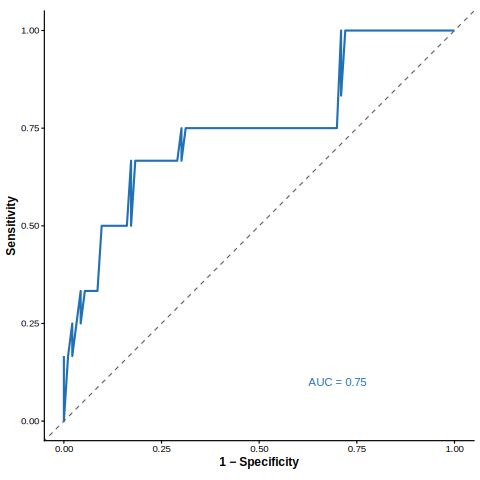

In [ ]:
%%R
# ROC and precision-recall curves of the interpreted model (test set)
test_labels <- as.numeric(test_df$LOS_final == "LOS")
pred_prob   <- as.data.frame(h2o.predict(best_model, test_hf))$LOS
roc_ml  <- pROC::roc(test_labels, pred_prob, quiet = TRUE, direction = "<")
p_roc <- ggplot(data.frame(fpr = 1 - roc_ml$specificities, tpr = roc_ml$sensitivities), aes(fpr, tpr)) +
  geom_line(colour = COL_BLUE, linewidth = 1) +
  geom_abline(linetype = "dashed", colour = COL_GREY) +
  annotate("text", x = 0.7, y = 0.1, label = sprintf("AUC = %.2f", pROC::auc(roc_ml)), colour = COL_BLUE, size = 4) +
  labs(title = "ROC Curve (Test Set)", x = "1 − Specificity", y = "Sensitivity") +
  coord_equal() + theme_los()
SaveFig(p_roc, "FigS_ROC_InterpretedModel", width = 5, height = 5)
print(p_roc)

Threshold: 0.0305 | cross-validated recall: 0.786 | precision: 0.083 
         Actual
Predicted Healthy LOS
  Healthy      18   0
  LOS          75  12


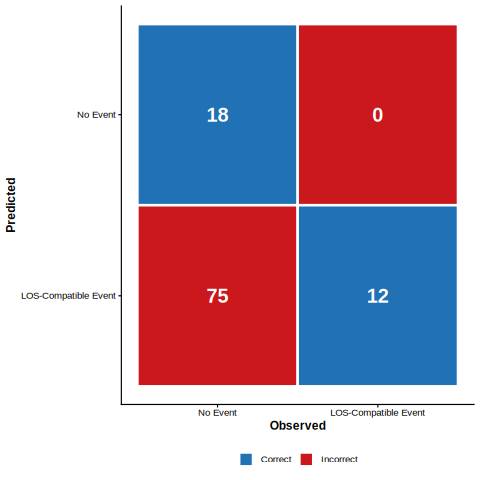

In [ ]:
%%R
# Classification threshold (chosen on cross-validated predictions) and confusion matrix
perf_xval <- h2o.performance(best_model, xval = TRUE)
thz <- as.data.frame(h2o.thresholds_and_metric_scores(perf_xval))
target_recall  <- 0.70
best_row       <- thz %>% dplyr::filter(tpr >= target_recall) %>% dplyr::arrange(dplyr::desc(precision)) %>% dplyr::slice(1)
best_threshold <- best_row$threshold
pred_class <- factor(ifelse(pred_prob >= best_threshold, "LOS", "Healthy"), levels = c("Healthy", "LOS"))
cm <- table(Predicted = pred_class, Actual = test_df$LOS_final)
cat("Threshold:", round(best_threshold, 4), "| cross-validated recall:", round(best_row$tpr, 3),
    "| precision:", round(best_row$precision, 3), "\n"); print(cm)

cm_df <- as.data.frame(cm) %>%
  dplyr::mutate(Correct = ifelse(Predicted == Actual, "Correct", "Incorrect"),
                Predicted = factor(ifelse(Predicted == "LOS", "LOS-Compatible Event", "No Event"), levels = c("LOS-Compatible Event", "No Event")),
                Actual    = factor(ifelse(Actual == "LOS", "LOS-Compatible Event", "No Event"), levels = c("No Event", "LOS-Compatible Event")))
p_cm <- ggplot(cm_df, aes(x = Actual, y = Predicted, fill = Correct)) +
  geom_tile(colour = "white", linewidth = 1.2) +
  geom_text(aes(label = Freq), size = 7, fontface = "bold", colour = "white") +
  scale_fill_manual(values = c("Correct" = COL_BLUE, "Incorrect" = COL_RED), name = NULL) +
  labs(title = "Confusion Matrix (Test Set)", subtitle = paste0(MODEL_LABEL, " | threshold = ", round(best_threshold, 3)),
       x = "Observed", y = "Predicted") +
  theme_los()
SaveFig(p_cm, "Fig03_ConfusionMatrix", width = 5.5, height = 4.5)
print(p_cm)

                                     Variable Scaled_Importance Percentage
 Proportion of Oocytes with ≥3 Cumulus Layers             1.000       16.9
                          Cleavage per Oocyte             0.604       10.2
                      Superovulation Protocol             0.588        9.9
                        Recipient Age (years)             0.524        8.9
                        Frozen Storage (days)             0.493        8.3
                    Donor Age at OPU (months)             0.435        7.3
                                     Calf Sex             0.323        5.5
                 Follicle Ratio (large/small)             0.304        5.1
                           Season of Transfer             0.271        4.6
               Viable Embryos per OPU Session             0.264        4.5
                           Embryos per Oocyte             0.242        4.1
                        Coasting Duration (h)             0.220        3.7
           Proportion of 

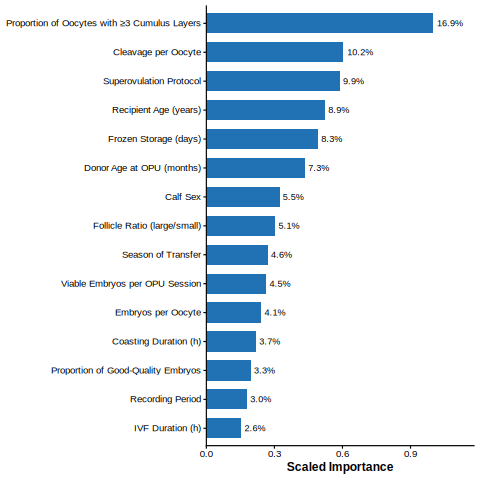

In [ ]:
%%R
# Variable importance of the interpreted model
# H2O variable importance = relative reduction in squared error attributable to each variable across all splits.
vi <- as.data.frame(h2o.varimp(best_model))
vi_tab <- vi %>% dplyr::transmute(Variable = CleanLabel(variable), Scaled_Importance = round(scaled_importance, 3),
                                  Percentage = round(100 * percentage, 1))
print(vi_tab, row.names = FALSE)
SaveTab(vi_tab, "Table_VariableImportance")
top_vi <- vi %>% dplyr::slice(1:15) %>% dplyr::mutate(label = CleanLabel(variable))
p_vi <- ggplot(top_vi, aes(x = reorder(label, scaled_importance), y = scaled_importance)) +
  geom_col(fill = COL_BLUE, width = 0.7) +
  geom_text(aes(label = sprintf("%.1f%%", 100 * percentage)), hjust = -0.15, size = 3.2) +
  coord_flip() + scale_y_continuous(expand = expansion(mult = c(0, 0.18))) +
  labs(title = paste(MODEL_LABEL, "Variable Importance (Top 15)"), x = NULL, y = "Scaled Importance") +
  theme_los()
SaveFig(p_vi, "Fig04_VariableImportance", width = 7, height = 5.5)
print(p_vi)

# A tibble: 23 × 3
   Variable                                 mean_abs_shap spearman_value_vs_shap
   <chr>                                            <dbl>                  <dbl>
 1 Proportion of Oocytes with ≥3 Cumulus L…         0.308                   0.27
 2 Superovulation Protocol                          0.185                  NA   
 3 Calf Sex                                         0.134                  NA   
 4 Season of Transfer                               0.118                  NA   
 5 Coasting Duration (h)                            0.115                  -0.82
 6 Recording Period                                 0.11                   NA   
 7 Cleavage per Oocyte                              0.107                   0.55
 8 Frozen Storage (days)                            0.105                  -0.41
 9 Recipient Age (years)                            0.096                   0.1 
10 Donor Age at OPU (months)                        0.087                  -0.75
# ℹ 13 mo

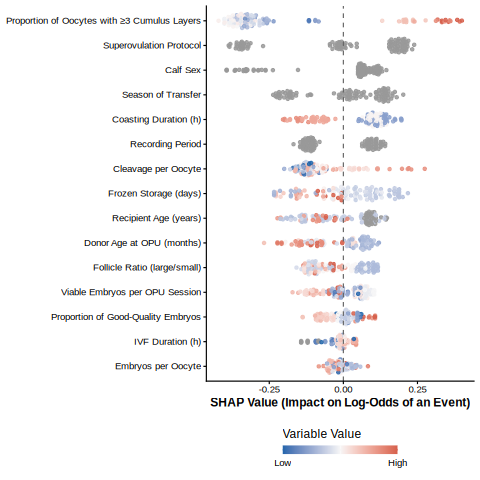

In [ ]:
%%R
# SHAP values of the interpreted model on the test set
shap_mat  <- as.data.frame(h2o.predict_contributions(best_model, test_hf)) %>% dplyr::select(-BiasTerm)
test_vals <- as.data.frame(test_hf) %>% dplyr::select(-LOS_final)
numeric_cols <- names(test_vals)[sapply(test_vals, is.numeric)]
test_scaled <- test_vals %>%
  dplyr::mutate(dplyr::across(dplyr::all_of(numeric_cols), ~ as.numeric(scale(.x)))) %>%
  dplyr::mutate(dplyr::across(dplyr::everything(), as.character), row_id = dplyr::row_number()) %>%
  tidyr::pivot_longer(-row_id, names_to = "variable", values_to = "feature_val_scaled")
shap_long <- shap_mat %>% dplyr::mutate(row_id = dplyr::row_number()) %>%
  tidyr::pivot_longer(-row_id, names_to = "variable", values_to = "shap") %>%
  dplyr::left_join(test_scaled, by = c("row_id", "variable")) %>%
  dplyr::mutate(feature_val_scaled = suppressWarnings(as.numeric(feature_val_scaled)))

# ranking and direction (Spearman correlation between a numeric variable and its SHAP value)
shap_summary <- shap_long %>% dplyr::group_by(variable) %>%
  dplyr::summarise(mean_abs_shap = mean(abs(shap)),
                   spearman_value_vs_shap = if (variable[1] %in% numeric_cols)
                     suppressWarnings(cor(as.numeric(test_vals[[variable[1]]]), shap, method = "spearman", use = "complete.obs")) else NA_real_,
                   .groups = "drop") %>%
  dplyr::arrange(dplyr::desc(mean_abs_shap)) %>%
  dplyr::mutate(Variable = CleanLabel(variable), mean_abs_shap = round(mean_abs_shap, 3), spearman_value_vs_shap = round(spearman_value_vs_shap, 2))
print(shap_summary %>% dplyr::select(Variable, mean_abs_shap, spearman_value_vs_shap), row.names = FALSE)
SaveTab(shap_summary %>% dplyr::select(Variable, mean_abs_shap, spearman_value_vs_shap), "Table_SHAPSummary")

top_vars <- head(shap_summary$variable, 15)
shap_plot_df <- shap_long %>% dplyr::filter(variable %in% top_vars) %>%
  dplyr::mutate(label = factor(CleanLabel(variable), levels = CleanLabel(rev(top_vars))))
p_shap <- ggplot(shap_plot_df, aes(x = shap, y = label, colour = feature_val_scaled)) +
  ggbeeswarm::geom_quasirandom(orientation = "y", size = 1.4, alpha = 0.85, width = 0.3) +
  geom_vline(xintercept = 0, linetype = "dashed", colour = COL_GREY) +
  scale_colour_gradient2(low = "#2166AC", mid = "#F7F7F7", high = "#D6604D", midpoint = 0, limits = c(-2, 2),
                         oob = scales::squish, na.value = "grey60", name = "Variable Value",
                         breaks = c(-2, 0, 2), labels = c("Low", "", "High"),
                         guide = guide_colourbar(title.position = "top", barwidth = 8, barheight = 0.6, ticks = FALSE)) +
  labs(title = "SHAP Summary (Test Set)", subtitle = paste(MODEL_LABEL, "| top 15 variables by mean |SHAP|"),
       x = "SHAP Value (Impact on Log-Odds of an Event)", y = NULL) +
  theme_los()
SaveFig(p_shap, "Fig05_SHAPSummary", width = 8, height = 6)
print(p_shap)

# A tibble: 13 × 7
   variable    level            mean_shap      se     n label          direction
   <chr>       <chr>                <dbl>   <dbl> <int> <chr>          <chr>    
 1 calf_gender Female             0.0826  0.00295    82 Calf Sex       Towards …
 2 calf_gender Male              -0.318   0.0118     23 Calf Sex       Away Fro…
 3 rec_period  Before July 2024  -0.117   0.00227    55 Recording Per… Away Fro…
 4 rec_period  From July 2024     0.101   0.00279    50 Recording Per… Towards …
 5 season      Autumn            -0.184   0.00735    18 Season of Tra… Away Fro…
 6 season      Spring             0.0242  0.00451    34 Season of Tra… Towards …
 7 season      Summer            -0.194   0.0104     12 Season of Tra… Away Fro…
 8 season      Winter             0.139   0.00322    41 Season of Tra… Towards …
 9 spo_program 1.5 cc FSH x 6     0.190   0.00312    46 Superovulatio… Towards …
10 spo_program 2 cc FSH x 6      -0.343   0.00439    28 Superovulatio… Away Fro…
11 spo_pr

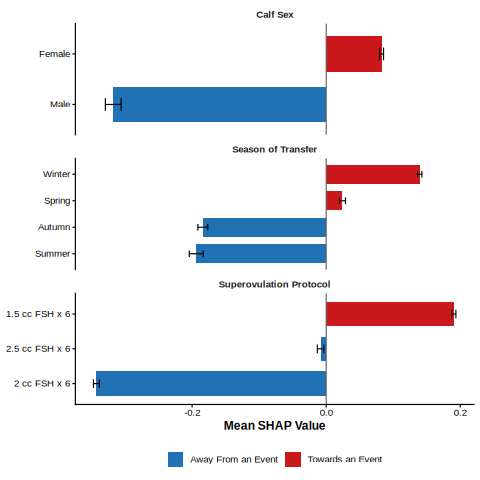

In [ ]:
%%R
# Mean SHAP value per level of the categorical variables
CAT_VARS <- intersect(c("spo_program", "season", "rec_period", "calf_gender"), unique(shap_long$variable))
test_levels <- as.data.frame(test_hf) %>% dplyr::select(dplyr::all_of(CAT_VARS)) %>%
  dplyr::mutate(dplyr::across(dplyr::everything(), as.character), row_id = dplyr::row_number()) %>%
  tidyr::pivot_longer(-row_id, names_to = "variable", values_to = "level")
cat_shap <- shap_long %>% dplyr::filter(variable %in% CAT_VARS) %>%
  dplyr::left_join(test_levels, by = c("row_id", "variable")) %>% dplyr::filter(!is.na(level)) %>%
  dplyr::group_by(variable, level) %>%
  dplyr::summarise(mean_shap = mean(shap), se = sd(shap) / sqrt(dplyr::n()), n = dplyr::n(), .groups = "drop") %>%
  dplyr::mutate(label = CleanLabel(variable), level = CleanLevel(level),
                direction = ifelse(mean_shap > 0, "Towards an Event", "Away From an Event"))
print(cat_shap)
SaveTab(cat_shap, "Table_SHAPCategorical")
p_cat_shap <- ggplot(dplyr::filter(cat_shap, n >= 4, variable != "rec_period"), aes(x = reorder(level, mean_shap), y = mean_shap, fill = direction)) +
  geom_col(width = 0.7) +
  geom_errorbar(aes(ymin = mean_shap - se, ymax = mean_shap + se), width = 0.25) +
  geom_hline(yintercept = 0, colour = COL_GREY) +
  scale_fill_manual(values = c("Towards an Event" = COL_RED, "Away From an Event" = COL_BLUE), name = NULL) +
  facet_wrap(~ label, scales = "free_y", ncol = 1) + coord_flip() +
  labs(title = "Mean SHAP Value by Category (Test Set)",
       subtitle = paste(MODEL_LABEL, "| mean ± SE; levels with < 4 test calves omitted"),
       x = NULL, y = "Mean SHAP Value") +
  theme_los()
SaveFig(p_cat_shap, "Fig06_SHAPCategorical", width = 7, height = 8)
print(p_cat_shap)

                                     Variable Drop_in_PR_AUC
                                     Calf Sex         0.1582
 Proportion of Oocytes with ≥3 Cumulus Layers         0.1093
                      Superovulation Protocol         0.0540
                        Frozen Storage (days)         0.0489
                             Recording Period         0.0375
                    Donor Age at OPU (months)         0.0364
                          Cleavage per Oocyte         0.0301
                        Recipient Age (years)         0.0279
                        Coasting Duration (h)         0.0184
               Viable Embryos per OPU Session         0.0081
                           Season of Transfer         0.0074
                             IVM Duration (h)         0.0011
                 Follicle Ratio (large/small)         0.0010
                                 Embryo Grade         0.0000
                          Recipient Cycle Day         0.0000
                  Cumulu

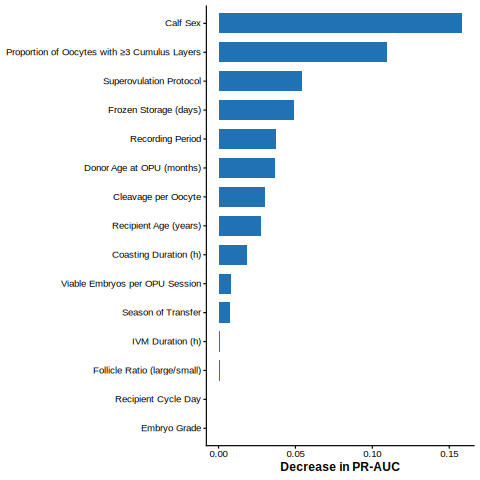

In [ ]:
%%R
# Permutation importance on the test set (drop in PR-AUC when a variable is shuffled)
set.seed(123)
N_PERM <- 20
test_df_perm   <- as.data.frame(test_hf)
baseline_aucpr <- h2o.aucpr(h2o.performance(best_model, newdata = test_hf))
vars <- setdiff(colnames(test_df_perm), "LOS_final")
perm_scores <- sapply(vars, function(v) {
  mean(replicate(N_PERM, {
    tmp <- test_df_perm; tmp[[v]] <- sample(tmp[[v]])
    tmp_hf <- as.h2o(tmp); tmp_hf[, "LOS_final"] <- as.factor(tmp_hf[, "LOS_final"])
    s <- h2o.aucpr(h2o.performance(best_model, newdata = tmp_hf)); h2o.rm(tmp_hf); baseline_aucpr - s
  }))
})
perm_df <- data.frame(Variable = CleanLabel(vars), Drop_in_PR_AUC = round(perm_scores, 4)) %>%
  dplyr::arrange(dplyr::desc(Drop_in_PR_AUC))
print(perm_df, row.names = FALSE)
SaveTab(perm_df, "TableS_PermutationImportance")
p_perm <- ggplot(head(perm_df, 15), aes(x = reorder(Variable, Drop_in_PR_AUC), y = Drop_in_PR_AUC, fill = Drop_in_PR_AUC > 0)) +
  geom_col(width = 0.7) + coord_flip() +
  scale_fill_manual(values = c("TRUE" = COL_BLUE, "FALSE" = COL_GREY), guide = "none") +
  labs(title = "Permutation Importance (Test Set)",
       subtitle = paste0(MODEL_LABEL, " | ", N_PERM, " permutations | baseline PR-AUC = ", round(baseline_aucpr, 3)),
       x = NULL, y = "Decrease in PR-AUC") +
  theme_los()
SaveFig(p_perm, "FigS_PermutationImportance", width = 7, height = 5.5)
print(p_perm)

Hosmer-Lemeshow (g = 10): chi2 = 26.49, df = 8, P = 0.001


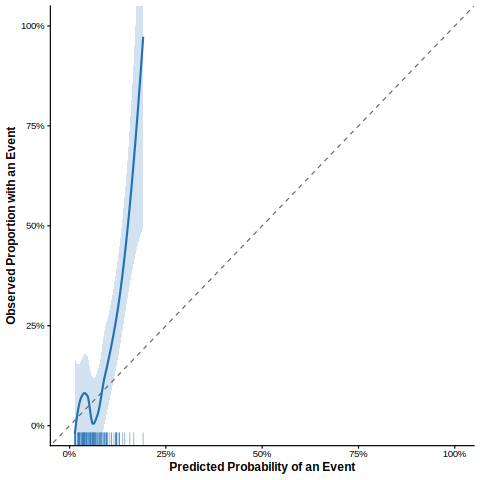

In [ ]:
%%R
# Calibration (test set)
cal_df <- data.frame(obs = test_labels, pred = pred_prob)
hl <- ResourceSelection::hoslem.test(cal_df$obs, cal_df$pred, g = 10)
cat(sprintf("Hosmer-Lemeshow (g = 10): chi2 = %.2f, df = %d, P = %.3f\n", hl$statistic, hl$parameter, hl$p.value))
p_cal <- ggplot(cal_df, aes(x = pred, y = obs)) +
  geom_smooth(method = "loess", span = 0.75, formula = y ~ x, colour = COL_BLUE, fill = COL_BLUE, alpha = 0.2, linewidth = 1) +
  geom_abline(slope = 1, intercept = 0, linetype = "dashed", colour = COL_GREY) +
  geom_rug(sides = "b", alpha = 0.4, colour = COL_BLUE) +
  scale_x_continuous(limits = c(0, 1), labels = scales::percent_format(accuracy = 1)) +
  scale_y_continuous(labels = scales::percent_format(accuracy = 1)) +
  coord_cartesian(ylim = c(0, 1)) +
  labs(title = paste("Calibration (Test Set):", MODEL_LABEL),
       x = "Predicted Probability of an Event", y = "Observed Proportion with an Event") +
  theme_los()
SaveFig(p_cal, "Fig07_Calibration", width = 5.5, height = 5)
print(p_cal)

   threshold    Treat All Treat None        GBM
1       0.00  0.114285714          0 0.11428571
2       0.01  0.105339105          0 0.10533911
3       0.02  0.096209913          0 0.09757046
4       0.03  0.086892489          0 0.09219440
5       0.04  0.077380952          0 0.06111111
6       0.05  0.067669173          0 0.05864662
7       0.06  0.057750760          0 0.05957447
8       0.07  0.047619048          0 0.06277522
9       0.08  0.037267081          0 0.05465839
10      0.09  0.026687598          0 0.05735217
11      0.10  0.015873016          0 0.04338624
12      0.11  0.004815409          0 0.04537186
13      0.12 -0.006493506          0 0.04545455
14      0.13 -0.018062397          0 0.02572523
15      0.14 -0.029900332          0 0.01594684
16      0.15 -0.042016807          0 0.01736695
17      0.16 -0.054421769          0 0.01904762
18      0.17 -0.067125645          0 0.00952381
19      0.18 -0.080139373          0 0.00952381
20      0.19 -0.093474427          0 0.0

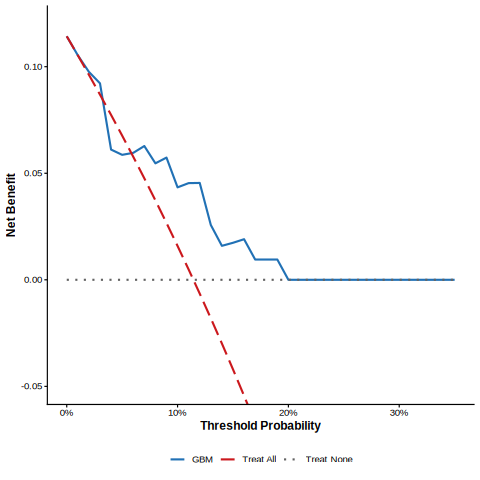

In [ ]:
%%R
# Decision curve analysis (test set)
dca_res <- dcurves::dca(obs ~ pred, data = cal_df, thresholds = seq(0, 0.35, by = 0.01), label = list(pred = MODEL_LABEL))
dca_data <- dca_res$dca %>% dplyr::mutate(label = as.character(label))
print(dca_data %>% dplyr::select(label, threshold, net_benefit) %>% tidyr::pivot_wider(names_from = label, values_from = net_benefit) %>% as.data.frame())
lv <- c(MODEL_LABEL, "Treat All", "Treat None")
p_dca <- ggplot(dplyr::filter(dca_data, label %in% lv) %>% dplyr::mutate(label = factor(label, levels = lv)),
                aes(x = threshold, y = net_benefit, colour = label, linetype = label)) +
  geom_line(linewidth = 1) +
  scale_colour_manual(values = setNames(c(COL_BLUE, COL_RED, COL_GREY), lv), name = NULL) +
  scale_linetype_manual(values = setNames(c("solid", "longdash", "dotted"), lv), name = NULL) +
  scale_x_continuous(labels = scales::percent_format(accuracy = 1)) +
  coord_cartesian(xlim = c(0, 0.35), ylim = c(-0.05, 0.12)) +
  labs(title = paste("Decision Curve (Test Set):", MODEL_LABEL), x = "Threshold Probability", y = "Net Benefit") +
  theme_los()
SaveFig(p_dca, "Fig08_DecisionCurve", width = 6.5, height = 4.5)
print(p_dca)

# Statistical models: LASSO-selected Firth regression and pre-specified exposures

Complete cases used for selection: 369 of 547 training calves ( 29 events ) | lambda.min = 0.0209 
Selected: Recording Period: From July 2024 Proportion of Oocytes with ≥3 Cumulus Layers Calf Sex: Male


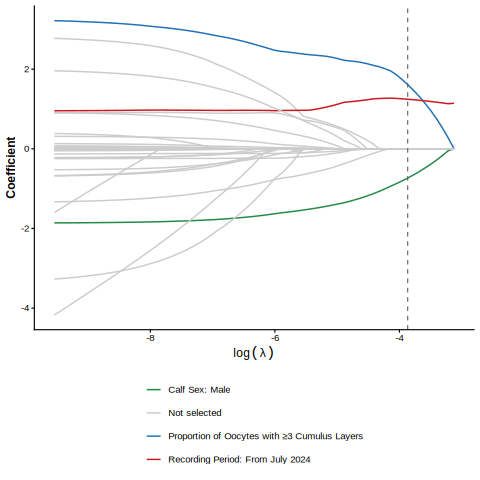

In [ ]:
%%R
# LASSO variable selection (training set)
# Recording period is always kept (penalty.factor = 0); cross-validation folds are grouped by donor cluster.
train_df_firth <- train_df %>% dplyr::select(-fold_id) %>%
  dplyr::mutate(LOS_num = as.integer(LOS_final == "LOS"), donor_cluster = train_cluster)
lasso_df <- na.omit(train_df_firth)
x_train  <- model.matrix(LOS_num ~ . - LOS_final - donor_cluster, data = lasso_df)[, -1]
y_train  <- lasso_df$LOS_num
pf       <- ifelse(grepl("^rec_period", colnames(x_train)), 0, 1)
foldid   <- as.integer(factor(lasso_df$donor_cluster)) %% 10 + 1
set.seed(123)
cv_lasso    <- cv.glmnet(x_train, y_train, family = "binomial", alpha = 1, type.measure = "auc", penalty.factor = pf, foldid = foldid)
lasso_model <- glmnet(x_train, y_train, family = "binomial", alpha = 1, lambda = cv_lasso$lambda.min, penalty.factor = pf)
coef_mat      <- as.matrix(coef(lasso_model))
selected_vars <- setdiff(rownames(coef_mat)[coef_mat[, 1] != 0], "(Intercept)")
cat("Complete cases used for selection:", nrow(lasso_df), "of", nrow(train_df_firth), "training calves (",
    sum(y_train), "events ) | lambda.min =", signif(cv_lasso$lambda.min, 3), "\nSelected:", CleanLabel(selected_vars), sep = " ")
cat("\n")

# coefficient paths (Figure 9)
fit_path <- glmnet(x_train, y_train, family = "binomial", alpha = 1, penalty.factor = pf)
path_df  <- as.data.frame(t(as.matrix(fit_path$beta))) %>% dplyr::mutate(log_lambda = log(fit_path$lambda)) %>%
  tidyr::pivot_longer(-log_lambda, names_to = "variable", values_to = "coef") %>%
  dplyr::mutate(selected = variable %in% selected_vars, label = ifelse(selected, CleanLabel(variable), "Not selected"))
p_lasso <- ggplot(path_df, aes(x = log_lambda, y = coef, group = variable, colour = label)) +
  geom_line(linewidth = 0.7) +
  geom_vline(xintercept = log(cv_lasso$lambda.min), linetype = "dashed", colour = COL_GREY) +
  scale_colour_manual(values = c(setNames(c(COL_RED, COL_BLUE, COL_GREEN, COL_ORANGE, "#756bb1", "#636363")[seq_along(unique(CleanLabel(selected_vars)))],
                                          unique(CleanLabel(selected_vars))), "Not selected" = "grey80"), name = NULL) +
  labs(title = "LASSO Coefficient Paths", x = expression(log(lambda)), y = "Coefficient") +
  theme_los() + guides(colour = guide_legend(ncol = 1))
SaveFig(p_lasso, "Fig09_LassoPaths", width = 7, height = 5)
print(p_lasso)

Firth model: n = 547 , events = 42 | likelihood-ratio chi2 = 29.8, df = 3, P = 1.5e-06
                                     Variable    OR Lower_CI Upper_CI P_value
             Recording Period: From July 2024  2.94     1.46     5.89 2.4e-03
 Proportion of Oocytes with ≥3 Cumulus Layers 13.51     3.00    60.92 7.0e-04
                               Calf Sex: Male  0.27     0.15     0.47 4.3e-06
      OR_per_10pp
             <NA>
 1.30 (1.12–1.51)
             <NA>


Training AUC 0.714 | test AUC 0.722 (95% CI 0.562-0.881) | test PR-AUC 0.343 | test n = 105, events = 12


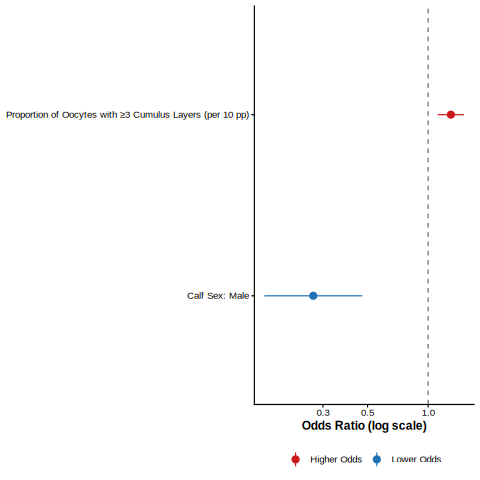

In [ ]:
%%R
# Firth logistic regression on the LASSO-selected variables (training set)
# Complete cases of the selected variables only; 95% CI from donor-cluster-robust standard errors.
base_vars <- names(train_df_firth)[sapply(names(train_df_firth), function(v) any(startsWith(selected_vars, v)))]
base_vars <- union(setdiff(base_vars, c("LOS_final", "LOS_num", "donor_cluster")), "rec_period")
firth_data <- train_df_firth %>% dplyr::select(LOS_num, donor_cluster, dplyr::all_of(base_vars)) %>% na.omit()
firth_fit  <- glm(as.formula(paste("LOS_num ~", paste(base_vars, collapse = " + "))),
                  data = firth_data, family = binomial, method = "brglmFit")
ct <- lmtest::coeftest(firth_fit, vcov. = sandwich::vcovCL(firth_fit, cluster = firth_data$donor_cluster, type = "HC0"))
firth_tab <- data.frame(term = rownames(ct), OR = exp(ct[, 1]), Lower_CI = exp(ct[, 1] - 1.96 * ct[, 2]),
                        Upper_CI = exp(ct[, 1] + 1.96 * ct[, 2]), P_value = ct[, 4]) %>% dplyr::filter(term != "(Intercept)")
# proportions are also reported per 10 percentage points
per10 <- grepl("^prop_", firth_tab$term)
firth_tab$OR_per_10pp <- ifelse(per10, sprintf("%.2f (%.2f–%.2f)", firth_tab$OR^0.1, firth_tab$Lower_CI^0.1, firth_tab$Upper_CI^0.1), NA)
firth_tab$Variable <- CleanLabel(firth_tab$term)
null_fit <- glm(LOS_num ~ 1, data = firth_data, family = binomial, method = "brglmFit")
lr_chi2  <- deviance(null_fit) - deviance(firth_fit); lr_df <- length(coef(firth_fit)) - 1
cat("Firth model: n =", nrow(firth_data), ", events =", sum(firth_data$LOS_num),
    sprintf("| likelihood-ratio chi2 = %.1f, df = %d, P = %.2g\n", lr_chi2, lr_df, pchisq(lr_chi2, lr_df, lower.tail = FALSE)))
print(firth_tab %>% dplyr::transmute(Variable, OR = round(OR, 2), Lower_CI = round(Lower_CI, 2), Upper_CI = round(Upper_CI, 2),
                                     P_value = signif(P_value, 2), OR_per_10pp), row.names = FALSE)
SaveTab(firth_tab %>% dplyr::transmute(Variable, OR = round(OR, 3), Lower_CI = round(Lower_CI, 3), Upper_CI = round(Upper_CI, 3),
                                       P_value = signif(P_value, 3), OR_per_10pp), "Table_FirthLassoSelected")

# test-set discrimination
test_firth <- test_df %>% dplyr::mutate(LOS_num = as.integer(LOS_final == "LOS")) %>% dplyr::select(LOS_num, dplyr::all_of(base_vars)) %>% na.omit()
firth_prob_test  <- as.numeric(predict(firth_fit, newdata = test_firth, type = "response"))
firth_prob_train <- as.numeric(predict(firth_fit, newdata = firth_data, type = "response"))
roc_firth <- pROC::roc(test_firth$LOS_num, firth_prob_test, quiet = TRUE, direction = "<")
pr_firth  <- PRROC::pr.curve(scores.class0 = firth_prob_test, weights.class0 = test_firth$LOS_num, curve = TRUE)
cat(sprintf("Training AUC %.3f | test AUC %.3f (95%% CI %.3f-%.3f) | test PR-AUC %.3f | test n = %d, events = %d\n",
            pROC::auc(pROC::roc(firth_data$LOS_num, firth_prob_train, quiet = TRUE)), pROC::auc(roc_firth),
            pROC::ci.auc(roc_firth)[1], pROC::ci.auc(roc_firth)[3], pr_firth$auc.integral, nrow(test_firth), sum(test_firth$LOS_num)))

# proportions plotted per 10 percentage points
plot_df <- firth_tab %>%
  dplyr::mutate(OR = ifelse(per10, OR^0.1, OR), Lower_CI = ifelse(per10, Lower_CI^0.1, Lower_CI),
                Upper_CI = ifelse(per10, Upper_CI^0.1, Upper_CI), Variable = ifelse(per10, paste0(Variable, " (per 10 pp)"), Variable)) %>%
  dplyr::filter(!grepl("^rec_period", term)) %>%   # recording period is an adjustment, not plotted
  dplyr::arrange(OR) %>% dplyr::mutate(Variable = factor(Variable, levels = Variable),
                                       direction = ifelse(OR > 1, "Higher Odds", "Lower Odds"))
p_firth <- ggplot(plot_df, aes(x = Variable, y = OR, colour = direction)) +
  geom_hline(yintercept = 1, linetype = "dashed", colour = COL_GREY) +
  geom_pointrange(aes(ymin = Lower_CI, ymax = Upper_CI), size = 0.6) +
  coord_flip() + scale_y_log10() +
  scale_colour_manual(values = c("Higher Odds" = COL_RED, "Lower Odds" = COL_BLUE), name = NULL) +
  labs(title = "Firth Logistic Regression (LASSO-Selected Variables)",
       subtitle = "Odds ratios with donor-cluster-robust 95% CI", x = NULL, y = "Odds Ratio (log scale)") +
  theme_los()
SaveFig(p_firth, "Fig10_FirthForest", width = 7, height = 4)
print(p_firth)

In [ ]:
%%R
# Stability of the LASSO selection, samples of donor clusters (training set)
# and selection without recipient age (the variable with most missing values, 29%), which enlarges the
# complete-case set.
set.seed(123)
lasso_select <- function(df) {
  x  <- model.matrix(LOS_num ~ . - LOS_final - donor_cluster, data = df)[, -1]
  pf <- ifelse(grepl("^rec_period", colnames(x)), 0, 1)
  fid <- as.integer(factor(df$donor_cluster)) %% 10 + 1
  cv <- tryCatch(cv.glmnet(x, df$LOS_num, family = "binomial", alpha = 1, type.measure = "auc", penalty.factor = pf, foldid = fid),
                 error = function(e) NULL)
  if (is.null(cv)) return(character(0))
  b <- as.matrix(coef(cv, s = "lambda.min")); setdiff(rownames(b)[b[, 1] != 0], "(Intercept)")
}
cl <- unique(lasso_df$donor_cluster)
boot_sel <- replicate(200, {
  s <- sample(cl, replace = TRUE)
  d <- do.call(rbind, lapply(s, function(z) lasso_df[lasso_df$donor_cluster == z, ]))
  lasso_select(d)
}, simplify = FALSE)
sel_freq <- sort(table(unlist(boot_sel)) / length(boot_sel), decreasing = TRUE)
stab_tab <- data.frame(Variable = CleanLabel(names(sel_freq)), Selected_in_pct_of_bootstraps = round(100 * as.numeric(sel_freq)))
print(head(stab_tab, 15), row.names = FALSE)
SaveTab(stab_tab, "TableS_LassoSelectionStability")

no_recip <- train_df_firth %>% dplyr::select(-recipient_age_years) %>% na.omit()
cat("Without recipient age:", nrow(no_recip), "complete training calves (", sum(no_recip$LOS_num), "events ); selected:",
    paste(CleanLabel(lasso_select(no_recip)), collapse = "; "), "\n")

                                     Variable Selected_in_pct_of_bootstraps
             Recording Period: From July 2024                           100
                               Calf Sex: Male                            89
 Proportion of Oocytes with ≥3 Cumulus Layers                            86
                          Cleavage per Oocyte                            28
        Superovulation Protocol: 2 cc FSH x 6                            28
                              Embryo Grade: 2                            28
           Proportion of Good-Quality Embryos                            27
                        Coasting Duration (h)                            25
           Cumulus Expansion After IVM: Not A                            22
                   Season of Transfer: Spring                            20
                        Frozen Storage (days)                            20
                        Recipient Age (years)                            20
            

Without recipient age: 499 complete training calves ( 41 events ); selected: Superovulation Protocol: 2 cc FSH x 6; Cumulus Expansion After IVM: Not A; Recording Period: From July 2024; Proportion of Oocytes with ≥3 Cumulus Layers; Calf Sex: Male 


In [ ]:
%%R
# Pre-specified exposures (inference)
# Each exposure modelled with recording period, Firth regression with donor-cluster-robust 95% CI, all calves of
# the analysis set with the exposure recorded. Because LASSO-Firth estimates are biased by selection, these
# estimates are used for inference.
prespec_vars <- c("donor_age_le9", "donor_age_3mo", "fsh15", "ivm_duration_h", "ivf_duration_h", "cum_10pp",
                  "heparin_concentration_in_fertilisation_droplets", "sire_a_semen_type", "season", "male_calf")
prespec_labels <- c(donor_age_le9 = "Donor Age ≤ 9 Months", donor_age_3mo = "Donor Age at OPU (per 3 months)",
                    fsh15 = "Superovulation Protocol: 1.5 cc FSH × 6", ivm_duration_h = "IVM Duration (per h)",
                    ivf_duration_h = "IVF Duration (per h)", cum_10pp = "Oocytes with ≥3 Cumulus Layers (per 10 pp)",
                    heparin_concentration_in_fertilisation_droplets = "Heparin Concentration (per µg/mL)",
                    sire_a_semen_type = "Semen Type", season = "Season of Transfer", male_calf = "Male Calf")
add_exposures <- function(d, outcome = "LOS_final") d %>%
  dplyr::mutate(y = as.integer(as.character(.data[[outcome]]) %in% c("1", "LOS")),
                fsh15 = as.integer(spo_program == "1.5 cc FSH x 6"), donor_age_3mo = dam_age_at_opu_months / 3,
                cum_10pp = prop_good_cumulus * 10, male_calf = as.integer(calf_gender == "Male"))
firth_robust <- function(d, v, adjust = "rec_period") {
  d <- d %>% dplyr::filter(!is.na(.data[[v]]))
  f <- glm(as.formula(paste("y ~", paste(c(v, adjust), collapse = " + "))), data = d, family = binomial, method = "brglmFit")
  ct <- lmtest::coeftest(f, vcov. = sandwich::vcovCL(f, cluster = d$donor_cluster, type = "HC0"))
  r <- ct[grepl(paste0("^", v), rownames(ct)), , drop = FALSE]
  data.frame(exposure = v, term = rownames(r), n = nrow(d), events = sum(d$y), OR = exp(r[, 1]),
             lo = exp(r[, 1] - 1.96 * r[, 2]), hi = exp(r[, 1] + 1.96 * r[, 2]), p = r[, 4])
}
pre_df <- add_exposures(lab_farm_data)
prespec_tab <- do.call(rbind, lapply(prespec_vars, function(v) firth_robust(pre_df, v)))
prespec_tab <- prespec_tab %>%
  dplyr::mutate(Exposure = ifelse(exposure %in% c("season", "sire_a_semen_type"),
                                  paste0(prespec_labels[exposure], ": ", CleanLevel(mapply(function(e, t) sub(paste0("^", e), "", t), exposure, term))),
                                  prespec_labels[exposure]),
                `OR (95% CI)` = fmt_or(OR, lo, hi), P = signif(p, 2))
print(prespec_tab %>% dplyr::select(Exposure, n, events, `OR (95% CI)`, P), row.names = FALSE)
SaveTab(prespec_tab %>% dplyr::select(Exposure, n, events, `OR (95% CI)`, P), "TableS_PrespecifiedExposures")

# gestation length of calves with and without an event (validity check)
g   <- lm(gestation_length ~ y + male_calf + rec_period, data = pre_df)
gct <- lmtest::coeftest(g, vcov. = sandwich::vcovCL(g, cluster = pre_df$donor_cluster, type = "HC0"))["y", ]
cat(sprintf("Gestation length, calves with vs without an event: %.1f d (95%% CI %.1f to %.1f)\n",
            gct[1], gct[1] - 1.96 * gct[2], gct[1] + 1.96 * gct[2]))

                                   Exposure   n events      OR (95% CI)       P
                       Donor Age ≤ 9 Months 652     54 2.24 (1.16–4.32) 1.6e-02
            Donor Age at OPU (per 3 months) 652     54 0.84 (0.62–1.13) 2.5e-01
    Superovulation Protocol: 1.5 cc FSH × 6 652     54 2.30 (1.11–4.77) 2.5e-02
                       IVM Duration (per h) 597     53 0.99 (0.76–1.29) 9.3e-01
                       IVF Duration (per h) 597     53 0.89 (0.67–1.19) 4.3e-01
 Oocytes with ≥3 Cumulus Layers (per 10 pp) 652     54 1.20 (1.07–1.35) 2.5e-03
          Heparin Concentration (per µg/mL) 652     54 1.02 (0.98–1.05) 4.0e-01
                 Semen Type: Sexed (Female) 652     54 1.30 (0.70–2.42) 4.1e-01
                 Season of Transfer: Spring 652     54 1.27 (0.63–2.56) 5.0e-01
                 Season of Transfer: Summer 652     54 1.29 (0.40–4.16) 6.7e-01
                 Season of Transfer: Winter 652     54 1.14 (0.55–2.34) 7.3e-01
                                  Male C

Gestation length, calves with vs without an event: 0.8 d (95% CI -0.7 to 2.2)


In [ ]:
%%R
# Donor age: the <= 9-month cut-point was derived from a conditional inference tree in exploratory analyses,
# so alternative cut-points and categories are reported (Firth regression with recording period, robust 95% CI).
age_df <- pre_df %>% dplyr::mutate(age_le10 = as.integer(dam_age_at_opu_months <= 10), age_le12 = as.integer(dam_age_at_opu_months <= 12),
                                   age_cat = factor(cut(dam_age_at_opu_months, c(0, 9, 12, Inf), labels = c("≤ 9", "10–12", "> 12")),
                                                    levels = c("> 12", "10–12", "≤ 9")))
print(table(Donor_age_months = age_df$age_cat, Event = age_df$y))
donor_age_tab <- do.call(rbind, lapply(c("donor_age_le9", "age_le10", "age_le12", "age_cat", "donor_age_3mo"), function(v) {
  r <- firth_robust(age_df, v)
  data.frame(Definition = c(donor_age_le9 = "≤ 9 vs > 9 months", age_le10 = "≤ 10 vs > 10 months", age_le12 = "≤ 12 vs > 12 months",
                            age_cat = "Category vs > 12 months", donor_age_3mo = "Per 3 months (continuous)")[[v]],
             Term = if (v == "age_cat") sub("^age_cat", "", r$term) else "", `OR (95% CI)` = fmt_or(r$OR, r$lo, r$hi),
             P = signif(r$p, 2), check.names = FALSE)
}))
print(donor_age_tab, row.names = FALSE)
SaveTab(donor_age_tab, "TableS_DonorAgeDefinitions")

                Event
Donor_age_months   0   1
           > 12  225  13
           10–12 184   8
           ≤ 9   189  33
                Definition  Term      OR (95% CI)     P
         ≤ 9 vs > 9 months       2.24 (1.16–4.32) 0.016
       ≤ 10 vs > 10 months       1.72 (0.93–3.19) 0.083
       ≤ 12 vs > 12 months       0.96 (0.50–1.86) 0.910
   Category vs > 12 months 10–12 0.55 (0.24–1.27) 0.160
   Category vs > 12 months   ≤ 9 1.56 (0.73–3.33) 0.250
 Per 3 months (continuous)       0.84 (0.62–1.13) 0.250


## Gestation length and time of day of laboratory procedures
Gestation length is recorded for every calf and does not depend on the outcome files; the clock-time fields are tested as operational variables.

In [ ]:
%%R
# Gestation length: a second, objectively recorded outcome
# Gestation length (calving date - transfer date + 7 d) is recorded for every calf whenever it was born, so it
# does not depend on the outcome files and every laboratory-linked singleton born from 2023 can be used
# (1,017 calves). Calf sex and twin status come from the calving remarks, which cover January 2023 to March 2025;
# calves born later are kept with sex 'unknown'. Linkage accepted implied gestations of 250-310 d only.
gl_df <- add_exposures(lab_farm_all) %>%
  dplyr::mutate(sex3 = factor(ifelse(is.na(calf_gender), "Unknown", as.character(calf_gender)), levels = c("Female", "Male", "Unknown")),
                transfer_year = factor(format(embryo_transfer_date, "%Y")),
                stage_expanded = as.integer(embryo_age == 7), grade2 = as.integer(embryo_grade == "2"),
                storage_30d = storage_days / 30, session = paste(dam_ID_chr, opu_date, sep = "_"),
                ivm_start_h = in_vitro_maturation_time / 60, ivf_start_h = in_vitro_fertilisation_time / 60,
                denudation_start_h = stripping_time / 60)
gl_vars <- c(donor_age_le9 = "Donor Age ≤ 9 Months", donor_age_3mo = "Donor Age at OPU (per 3 months)",
             fsh15 = "Superovulation Protocol: 1.5 cc FSH × 6", cum_10pp = "Oocytes with ≥3 Cumulus Layers (per 10 pp)",
             ivm_duration_h = "IVM Duration (per h)", ivf_duration_h = "IVF Duration (per h)",
             heparin_concentration_in_fertilisation_droplets = "Heparin Concentration (per µg/mL)",
             sire_a_semen_type = "Semen Type: Sexed (Female)", stage_expanded = "Embryo Stage 7 (Expanded Blastocyst) vs Other",
             grade2 = "Embryo Quality Grade 2 vs 1", storage_30d = "Frozen-Storage Time (per 30 d)",
             recipient_age_years = "Recipient Age (per year)", sync_abs = "Recipient–Embryo Asynchrony (per day)")
lm_robust <- function(d, v, adjust, cluster = "donor_cluster") {
  d <- d[!is.na(d[[v]]), ]
  f <- lm(as.formula(paste("gestation_length ~", paste(c(v, adjust), collapse = " + "))), data = d)
  ct <- lmtest::coeftest(f, vcov. = sandwich::vcovCL(f, cluster = d[[cluster]], type = "HC0"))
  r <- ct[grepl(paste0("^", v), rownames(ct)), , drop = FALSE][1, ]
  list(txt = sprintf("%.1f (%.1f to %.1f)", r[1], r[1] - 1.96 * r[2], r[1] + 1.96 * r[2]), p = r[4], n = nrow(d))
}
gest_tab <- do.call(rbind, lapply(names(gl_vars), function(v) {
  a <- lm_robust(gl_df, v, "sex3"); b <- lm_robust(gl_df, v, c("sex3", "transfer_year"))
  w <- if (v %in% c("stage_expanded", "grade2", "storage_30d", "recipient_age_years", "sync_abs"))
         lm_robust(gl_df, v, c("sex3", "factor(session)"), cluster = "session")$txt else "—"
  data.frame(Variable = gl_vars[[v]], Calves = a$n, `Difference in Days (95% CI)` = a$txt, P = signif(a$p, 2),
             `Adjusted for Transfer Year` = b$txt, `Within Donor OPU Session` = w, check.names = FALSE)
}))
print(gest_tab, row.names = FALSE)
SaveTab(gest_tab, "TableS_GestationLength")
gl_w <- gl_df %>% dplyr::filter(in_window)
ev_gl <- lm_robust(gl_w, "y", c("sex3", "rec_period"))
cat("Gestation length, all calves: mean", round(mean(gl_df$gestation_length), 1), "d (SD", round(sd(gl_df$gestation_length), 1),
    ") | calves with vs without an event (recording window):", ev_gl$txt, "d\n")
cat("Males vs females:", lm_robust(gl_df, "sex3", character(0))$txt, "d\n")

                                      Variable Calves
                          Donor Age ≤ 9 Months   1017
               Donor Age at OPU (per 3 months)   1017
       Superovulation Protocol: 1.5 cc FSH × 6   1017
    Oocytes with ≥3 Cumulus Layers (per 10 pp)   1017
                          IVM Duration (per h)    962
                          IVF Duration (per h)    962
             Heparin Concentration (per µg/mL)   1017
                    Semen Type: Sexed (Female)   1017
 Embryo Stage 7 (Expanded Blastocyst) vs Other   1017
                   Embryo Quality Grade 2 vs 1   1017
                Frozen-Storage Time (per 30 d)   1017
                      Recipient Age (per year)    813
         Recipient–Embryo Asynchrony (per day)   1017
 Difference in Days (95% CI)       P Adjusted for Transfer Year
           0.3 (-0.5 to 1.2) 4.5e-01          0.1 (-0.6 to 0.8)
          -0.2 (-0.5 to 0.1) 1.9e-01         -0.1 (-0.4 to 0.1)
           0.5 (-0.3 to 1.3) 2.2e-01          0.3 (-

Gestation length, all calves: mean 278.8 d (SD 4.3 ) | calves with vs without an event (recording window): 0.8 (-0.7 to 2.2) d
Males vs females: 0.6 (-0.2 to 1.3) d


In [ ]:
%%R
# Time of day at which laboratory procedures began (operational variables)
# The clock-time fields are not durations, but they do record when the work was done: the hour at which
# maturation, fertilisation and denudation began. Each is tested once (pre-specified), for the LOS-compatible
# outcome (Firth regression with recording period) and for gestation length (adjusted for calf sex).
clock_vars <- c(ivm_start_h = "IVM Start (hour of day)", ivf_start_h = "IVF Start (hour of day)",
                denudation_start_h = "Denudation Start (hour of day)")
clock_df <- pre_df %>% dplyr::mutate(ivm_start_h = in_vitro_maturation_time / 60, ivf_start_h = in_vitro_fertilisation_time / 60,
                                     denudation_start_h = stripping_time / 60)
clock_tab <- do.call(rbind, lapply(names(clock_vars), function(v) {
  r <- firth_robust(clock_df, v); g <- lm_robust(gl_df, v, "sex3")
  data.frame(Variable = clock_vars[[v]],
             `Range (h)` = sprintf("%.1f–%.1f", min(clock_df[[v]], na.rm = TRUE), max(clock_df[[v]], na.rm = TRUE)),
             `LOS-Compatible Event: OR per Hour (95% CI)` = fmt_or(r$OR, r$lo, r$hi), `P (Event)` = signif(r$p, 2),
             `Gestation Length: Days per Hour (95% CI)` = g$txt, `P (Gestation)` = signif(g$p, 2), check.names = FALSE)
}))
print(clock_tab, row.names = FALSE)
SaveTab(clock_tab, "TableS_ProcedureTimeOfDay")

                       Variable Range (h)
        IVM Start (hour of day)  8.2–14.5
        IVF Start (hour of day) 10.3–15.4
 Denudation Start (hour of day)  7.0–12.3
 LOS-Compatible Event: OR per Hour (95% CI) P (Event)
                           1.14 (0.93–1.38)      0.21
                           1.14 (0.93–1.39)      0.20
                           1.23 (0.59–2.55)      0.59
 Gestation Length: Days per Hour (95% CI) P (Gestation)
                        0.2 (-0.0 to 0.5)          0.10
                       -0.2 (-0.5 to 0.1)          0.21
                       -0.1 (-0.5 to 0.2)          0.40


# Decision trees: CART and conditional inference tree


Classification tree:
rpart(formula = LOS_factor ~ ., data = tree_plot_data, weights = tree_weights, 
    method = "class", control = rpart.control(cp = 0.001, minsplit = 20, 
        minbucket = 10, maxdepth = 5))

Variables actually used in tree construction:
 [1] Cleavage per Oocyte                         
 [2] Coasting Duration (h)                       
 [3] Embryos per Oocyte                          
 [4] Follicle Ratio (large/small)                
 [5] Frozen Storage (days)                       
 [6] IVF Duration (h)                            
 [7] Proportion of Oocytes with ≥3 Cumulus Layers
 [8] Recipient Age (years)                       
 [9] Season of Transfer                          
[10] Superovulation Protocol                     

Root node error: 210/547 = 0.38391

n= 547 

         CP nsplit rel error xerror     xstd
1 0.0365079      0   1.00000 1.0000 0.057994
2 0.0333333      4   0.82857 1.1286 0.059940
3 0.0095238      5   0.79524 1.1190 0.059811
4 0.0079365 

CART test AUC 0.475 | PR-AUC 0.102


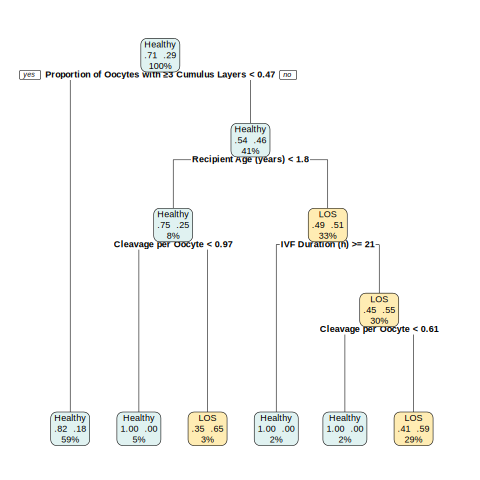

In [ ]:
%%R
# Classification tree (CART)
# Case weights 1:5 address class imbalance; node proportions are reported UNWEIGHTED (observed proportion of
# calves with an event). Columns carry their figure labels so the tree shows readable names.
tree_data <- train_df %>% dplyr::select(-fold_id) %>%
  dplyr::mutate(LOS_factor = factor(ifelse(LOS_final == "LOS", "LOS", "Healthy"), levels = c("Healthy", "LOS")))
tree_plot_data <- tree_data %>% dplyr::select(-LOS_final) %>% dplyr::rename_with(CleanLabel, -LOS_factor)
tree_weights <- ifelse(tree_plot_data$LOS_factor == "LOS", 5, 1)
set.seed(123)
tree_fit <- rpart(LOS_factor ~ ., data = tree_plot_data, weights = tree_weights, method = "class",
                  control = rpart.control(cp = 0.001, minsplit = 20, minbucket = 10, maxdepth = 5))
printcp(tree_fit)
best_cp_cv <- tree_fit$cptable[which.min(tree_fit$cptable[, "xerror"]), "CP"]
cat("Cross-validation-optimal cp:", round(best_cp_cv, 4), "(root only if this is the first row)\n")
tree_pruned <- prune(tree_fit, cp = 0.021)    # exploratory tree; cross-validation favours the root-only tree
leaf <- factor(tree_pruned$where)
cart_nodes <- data.frame(node = rownames(tree_pruned$frame)[as.integer(levels(leaf))], n = as.vector(table(leaf)),
                         events = as.vector(tapply(tree_plot_data$LOS_factor == "LOS", leaf, sum))) %>%
  dplyr::mutate(pct_event = round(100 * events / n, 1))
print(tree_pruned); print(cart_nodes)
SaveTab(cart_nodes, "Table_CARTTerminalNodes")
draw_tree <- function() rpart.plot(tree_pruned, type = 2, extra = 104, box.palette = list("#E0F2F1", "#FFECB3", "#FFCCBC"),
                                   shadow.col = 0, cex = 0.75, fallen.leaves = TRUE, faclen = 0, varlen = 0)
for (dev in c("pdf", "tiff", "png")) {
  f <- file.path(FigDir, paste0("Fig11_CART.", dev))
  if (dev == "pdf") cairo_pdf(f, width = 12, height = 7) else if (dev == "tiff") tiff(f, width = 12, height = 7, units = "in", res = 600, compression = "lzw") else png(f, width = 12, height = 7, units = "in", res = 300)
  draw_tree(); invisible(dev.off())
}
draw_tree()

# test-set performance of the pruned tree
cart_test <- test_df %>% dplyr::select(-LOS_final) %>% dplyr::rename_with(CleanLabel)
cart_pred <- predict(tree_pruned, newdata = cart_test, type = "prob")[, "LOS"]
roc_cart  <- pROC::roc(test_labels, cart_pred, quiet = TRUE, direction = "<")
pr_cart   <- PRROC::pr.curve(scores.class0 = cart_pred, weights.class0 = test_labels, curve = TRUE)
cat(sprintf("CART test AUC %.3f | PR-AUC %.3f\n", pROC::auc(roc_cart), pr_cart$auc.integral))


Model formula:
LOS_final ~ `Embryo Stage (IETS Code)` + `Embryo Grade` + `Recipient Cycle Day` + 
    `Semen Type` + `Superovulation Protocol` + `Coasting Duration (h)` + 
    `Cumulus Expansion After IVM` + `Heparin Concentration (µg/mL)` + 
    `Proportion of Good-Quality Embryos` + `Frozen Storage (days)` + 
    `Recording Period` + `Donor Age at OPU (months)` + `Recipient Age (years)` + 
    `Season of Transfer` + `Follicle Ratio (large/small)` + `Proportion of Oocytes with ≥3 Cumulus Layers` + 
    `Embryos per Oocyte` + `Cleavage per Oocyte` + `Sire Birth Year` + 
    `Calf Sex` + `IVM Duration (h)` + `IVF Duration (h)` + `Viable Embryos per OPU Session`

Fitted party:
[1] root
|   [2] Proportion of Oocytes with ≥3 Cumulus Layers <= 0.47368: Healthy (n = 361, err = 4.2%)
|   [3] Proportion of Oocytes with ≥3 Cumulus Layers > 0.47368: Healthy (n = 186, err = 14.5%)

Number of inner nodes:    1
Number of terminal nodes: 2


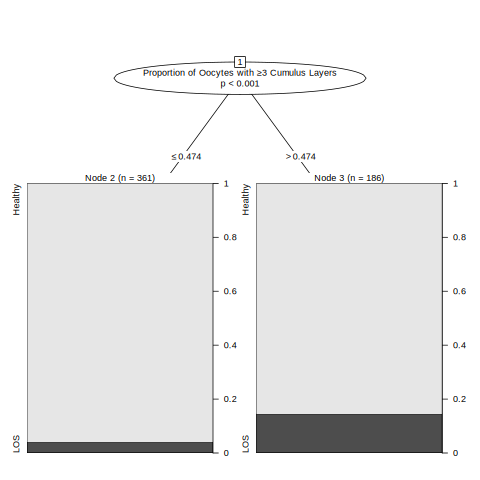

In [ ]:
%%R
# Conditional inference tree (partykit)
ctree_data <- train_df %>% dplyr::select(-fold_id) %>%
  dplyr::mutate(dplyr::across(dplyr::where(is.character), as.factor)) %>%
  dplyr::rename_with(CleanLabel, -LOS_final)
set.seed(123)
ctree_fit <- partykit::ctree(LOS_final ~ ., data = ctree_data,
                             control = partykit::ctree_control(mincriterion = 0.75, minsplit = 15, minbucket = 8, maxdepth = 4))
print(ctree_fit)
for (dev in c("pdf", "tiff", "png")) {
  f <- file.path(FigDir, paste0("FigS_ConditionalInferenceTree.", dev))
  if (dev == "pdf") cairo_pdf(f, width = 10, height = 6) else if (dev == "tiff") tiff(f, width = 10, height = 6, units = "in", res = 600, compression = "lzw") else png(f, width = 10, height = 6, units = "in", res = 300)
  plot(ctree_fit, gp = grid::gpar(fontsize = 9)); invisible(dev.off())
}
plot(ctree_fit, gp = grid::gpar(fontsize = 9))

# Clustering of outcomes within donors, laboratory lots and sibling embryos
Intraclass correlation, concentration of events among sibling calves (same OPU lot or same donor and OPU day), within-session comparison of siblings, and the power of these tests.

In [ ]:
%%R
# Clustering of outcomes within donors and laboratory lots
# (1) latent-scale intraclass correlation from a logistic mixed model adjusted for recording period
icc_df  <- master_data %>% dplyr::mutate(LOS_num = as.integer(LOS_final == "LOS"), donor_cluster = master_cluster, lot = cluster_df$embryo_lot)
icc_mod <- lme4::glmer(LOS_num ~ rec_period + (1 | donor_cluster) + (1 | lot), data = icc_df, family = binomial,
                       control = lme4::glmerControl(optimizer = "bobyqa"))
vc <- as.data.frame(lme4::VarCorr(icc_mod))
print(setNames(round(vc$vcov / (sum(vc$vcov) + pi^2 / 3), 3), vc$grp))

# (2) permutation test: are events more concentrated in some lots/donors than expected by chance?
# Outcomes are shuffled within recording period (5,000 times) and a chi-square-type dispersion statistic is compared.
disp <- function(y, g) { t <- tapply(y, g, sum); n <- tapply(y, g, length); sum((t - n * mean(y))^2 / (n * mean(y))) }
set.seed(123)
cluster_test <- do.call(rbind, lapply(c(lot = "lot", donor = "donor_cluster"), function(g) {
  obs  <- disp(icc_df$LOS_num, icc_df[[g]])
  perm <- replicate(5000, { yy <- icc_df$LOS_num
    for (p in levels(icc_df$rec_period)) { i <- which(icc_df$rec_period == p); yy[i] <- sample(yy[i]) }
    disp(yy, icc_df[[g]]) })
  tab <- tapply(icc_df$LOS_num, icc_df[[g]], sum)
  data.frame(unit = ifelse(g == "lot", "Laboratory lot (OPU collection date)", "Donor cluster"),
             clusters = length(tab), clusters_with_event = sum(tab > 0), max_events_per_cluster = max(tab),
             observed = round(obs, 1), permuted_median = round(median(perm), 1), P = round(mean(perm >= obs), 3))
}))
print(cluster_test, row.names = FALSE)
SaveTab(cluster_test, "TableS_ClusteringOfEvents")

donor_cluster           lot 
        0.017         0.000 
                                 unit clusters clusters_with_event
 Laboratory lot (OPU collection date)       51                  28
                        Donor cluster       65                  28
 max_events_per_cluster observed permuted_median     P
                      4     52.0            52.2 0.511
                      5     81.8            79.6 0.447


In [ ]:
%%R
# Sibling embryos: are events concentrated among calves from the same OPU lot or donor session?
# Calves from the same donor and OPU day share the donor, her age and stimulation protocol, the oocyte cohort,
# the laboratory day and (in 99% of sessions) the sire. If LOS-compatible events arose mainly from these shared
# factors, the siblings of an affected calf would be affected more often than expected by chance.
sib_df <- lab_farm_all %>%
  dplyr::mutate(lot = cluster_all$embryo_lot, donor_cluster = cluster_all$donor_cluster,
                session = paste(dam_ID_chr, opu_date, sep = "_"),
                y = as.integer(as.character(LOS_final) %in% c("1", "LOS"))) %>%
  dplyr::filter(in_window)
sib_units <- c(lot = "OPU lot (collection date)", donor_cluster = "Donor cluster",
               session = "Donor OPU session (same donor, same day)")
perm_within <- function(y, period) {                     # permute the outcome within recording period
  for (p in unique(period)) { i <- which(period == p); y[i] <- y[i][sample.int(length(i))] }
  y }
sib_share <- function(y, g) { k <- tapply(y, g, sum)[as.character(g)]; sum(y == 1 & k >= 2) / sum(y) }
disp      <- function(y, g) { t <- tapply(y, g, sum); n <- tapply(y, g, length); sum((t - n * mean(y))^2 / (n * mean(y))) }
set.seed(123)
N_PERM_SIB <- 5000
sib_tab <- do.call(rbind, lapply(names(sib_units), function(u) {
  g <- sib_df[[u]]; y <- sib_df$y
  tt <- data.frame(g = g, y = y) %>% dplyr::group_by(g) %>% dplyr::summarise(n = dplyr::n(), ev = sum(y), .groups = "drop")
  disc <- tt$ev > 0 & tt$ev < tt$n
  obs_share <- sib_share(y, g); obs_disp <- disp(y, g)
  perm <- replicate(N_PERM_SIB, { yy <- perm_within(y, sib_df$rec_period); c(sib_share(yy, g), disp(yy, g)) })
  data.frame(Unit = sib_units[[u]], Units = nrow(tt), `Calves per Unit, Median (Range)` = sprintf("%d (%d–%d)", as.integer(median(tt$n)), min(tt$n), max(tt$n)),
             `Units with an Event` = sum(tt$ev > 0), `Units with Affected and Unaffected Calves` = sum(disc),
             `Events in These Units` = sprintf("%d of %d", sum(tt$ev[disc]), sum(y)),
             `Events with an Affected Sibling, Observed (%)` = round(100 * obs_share, 1),
             `Expected under Permutation (%)` = round(100 * median(perm[1, ]), 1),
             `P (Sibling Concordance)` = round((1 + sum(perm[1, ] >= obs_share)) / (N_PERM_SIB + 1), 3),
             `P (Dispersion)` = round((1 + sum(perm[2, ] >= obs_disp)) / (N_PERM_SIB + 1), 3), check.names = FALSE)
}))
print(sib_tab, row.names = FALSE)
SaveTab(sib_tab, "TableS_SiblingConcordance")
cat("Sessions with more than one sire:", sum(tapply(sib_df$sire_ID.y, sib_df$session, function(v) dplyr::n_distinct(v) > 1)),
    "of", dplyr::n_distinct(sib_df$session), "| transfer-date span within sessions with affected and unaffected calves, median (IQR):",
    paste(quantile(unlist(lapply(split(sib_df, sib_df$session), function(s) if (sum(s$y) > 0 && sum(s$y) < nrow(s))
      as.numeric(diff(range(s$embryo_transfer_date))) else NULL)), c(0.5, 0.25, 0.75)), collapse = ", "), "d\n")

                                     Unit Units Calves per Unit, Median (Range)
                OPU lot (collection date)    51                       10 (2–39)
                            Donor cluster    65                        7 (1–41)
 Donor OPU session (same donor, same day)   283                        2 (1–11)
 Units with an Event Units with Affected and Unaffected Calves
                  28                                        28
                  28                                        27
                  49                                        40
 Events in These Units Events with an Affected Sibling, Observed (%)
              54 of 54                                          79.6
              53 of 54                                          74.1
              44 of 54                                          18.5
 Expected under Permutation (%) P (Sibling Concordance) P (Dispersion)
                           75.9                   0.263          0.511
          

Sessions with more than one sire: 2 of 283 | transfer-date span within sessions with affected and unaffected calves, median (IQR): 5.5, 3, 9 d


In [ ]:
%%R
# Within-session comparison of sibling calves (conditional logistic regression)
# Stratifying on the donor OPU session removes every factor that siblings share (donor, donor age, stimulation
# protocol, oocyte cohort, laboratory day and sire), so only factors that differ between siblings can be
# estimated: the embryo (stage, grade, frozen-storage time), the recipient (age, synchrony) and calf sex.
# Only strata with at least one affected and one unaffected calf, and with variation in the factor, contribute.
sib_x <- sib_df %>%
  dplyr::mutate(male_calf = as.integer(calf_gender == "Male"), stage_expanded = as.integer(embryo_age == 7),
                grade2 = as.integer(embryo_grade == "2"), storage_30d = storage_days / 30)
sib_vars <- c(male_calf = "Male Calf", stage_expanded = "Embryo Stage 7 (Expanded Blastocyst) vs Other",
              grade2 = "Embryo Quality Grade 2 vs 1", storage_30d = "Frozen-Storage Time (per 30 d)",
              recipient_age_years = "Recipient Age (per year)", sync_abs = "Recipient–Embryo Asynchrony (per day)")
clogit_one <- function(d, v, outcome = "y", strata = "session") {
  d <- d[!is.na(d[[v]]), ]; d$yy <- d[[outcome]]
  keep <- d %>% dplyr::group_by(.data[[strata]]) %>%
    dplyr::summarise(ok = sum(yy) > 0 & sum(yy) < dplyr::n() & dplyr::n_distinct(.data[[v]]) > 1, .groups = "drop") %>%
    dplyr::filter(ok) %>% dplyr::pull(1)
  di <- d[d[[strata]] %in% keep, ]
  f  <- survival::clogit(as.formula(paste("yy ~", v, "+ strata(", strata, ")")), data = di, method = "exact")
  ci <- summary(f)$conf.int; p <- summary(f)$coefficients[1, 5]
  list(txt = fmt_or(ci[1, 1], ci[1, 3], ci[1, 4]), p = p, strata = length(keep), n = nrow(di), ev = sum(di$yy))
}
clogit_tab <- do.call(rbind, lapply(names(sib_vars), function(v) {
  m <- clogit_one(sib_x, v); s <- clogit_one(sib_x, v, outcome = "ev_strict"); l <- clogit_one(sib_x, v, strata = "lot")
  data.frame(Variable = sib_vars[[v]], `Sessions / Calves / Events` = sprintf("%d / %d / %d", m$strata, m$n, m$ev),
             `Within Session: OR (95% CI)` = m$txt, P = signif(m$p, 2),
             `Within Session, Excluding Antibiotic-Only Navel Events` = s$txt,
             `Within OPU Lot: OR (95% CI)` = l$txt, check.names = FALSE)
}))
print(clogit_tab, row.names = FALSE)
SaveTab(clogit_tab, "TableS_WithinSessionComparison")

                                      Variable Sessions / Calves / Events
                                     Male Calf               19 / 88 / 22
 Embryo Stage 7 (Expanded Blastocyst) vs Other               14 / 56 / 16
                   Embryo Quality Grade 2 vs 1               18 / 83 / 22
                Frozen-Storage Time (per 30 d)              36 / 155 / 40
                      Recipient Age (per year)              26 / 101 / 30
         Recipient–Embryo Asynchrony (per day)               15 / 63 / 17
 Within Session: OR (95% CI)     P
            0.31 (0.11–0.84) 0.021
            1.08 (0.35–3.31) 0.890
            0.77 (0.28–2.11) 0.610
           1.44 (0.14–15.36) 0.760
           1.56 (0.13–18.19) 0.720
            1.15 (0.51–2.58) 0.740
 Within Session, Excluding Antibiotic-Only Navel Events
                                       0.10 (0.01–0.89)
                                       1.32 (0.31–5.67)
                                       0.71 (0.14–3.70)
             

In [ ]:
%%R
# How much clustering could these tests detect? (simulation)
# Outcomes are simulated from a random-intercept logistic model with the observed structure (calves, units,
# recording period and its effect, prevalence) and a latent-scale intraclass correlation (ICC) for the unit;
# power = proportion of simulations in which the permutation test gives P < 0.05.
set.seed(123)
N_SIM <- 200; N_PERM_POW <- 199
b_period <- coef(glm(y ~ rec_period, data = sib_df, family = binomial))[2]
x_period <- as.integer(sib_df$rec_period == levels(sib_df$rec_period)[2])
power_one <- function(u, icc, stat) {
  g <- sib_df[[u]]; gi <- as.integer(factor(g)); sd_u <- sqrt(icc / (1 - icc) * pi^2 / 3)
  mean(replicate(N_SIM, {
    b <- rnorm(max(gi), 0, sd_u)[gi]
    a <- uniroot(function(a) mean(plogis(a + b + b_period * x_period)) - mean(sib_df$y), c(-15, 5))$root
    y <- rbinom(length(gi), 1, plogis(a + b + b_period * x_period))
    if (sum(y) == 0) return(FALSE)
    obs <- stat(y, g); perm <- replicate(N_PERM_POW, stat(perm_within(y, sib_df$rec_period), g))
    (1 + sum(perm >= obs)) / (N_PERM_POW + 1) < 0.05
  }))
}
pow_grid <- expand.grid(icc = c(0.05, 0.10, 0.20, 0.30), u = c("lot", "session"), stringsAsFactors = FALSE)
pow_grid$disp  <- mapply(function(u, icc) power_one(u, icc, disp), pow_grid$u, pow_grid$icc)
pow_grid$share <- mapply(function(u, icc) power_one(u, icc, sib_share), pow_grid$u, pow_grid$icc)
power_tab <- data.frame(Unit = sib_units[pow_grid$u], `Latent ICC` = sprintf("%.2f", pow_grid$icc),
                        `Power, Dispersion Test (%)` = round(100 * pow_grid$disp),
                        `Power, Sibling-Concordance Test (%)` = round(100 * pow_grid$share), check.names = FALSE)
print(power_tab, row.names = FALSE)
SaveTab(power_tab, "TableS_ClusteringPower")

                                     Unit Latent ICC Power, Dispersion Test (%)
                OPU lot (collection date)       0.05                         16
                OPU lot (collection date)       0.10                         42
                OPU lot (collection date)       0.20                         82
                OPU lot (collection date)       0.30                         96
 Donor OPU session (same donor, same day)       0.05                          8
 Donor OPU session (same donor, same day)       0.10                         10
 Donor OPU session (same donor, same day)       0.20                         26
 Donor OPU session (same donor, same day)       0.30                         44
 Power, Sibling-Concordance Test (%)
                                   4
                                   7
                                  12
                                  24
                                   9
                                  14
                     

# Model comparison on the test set

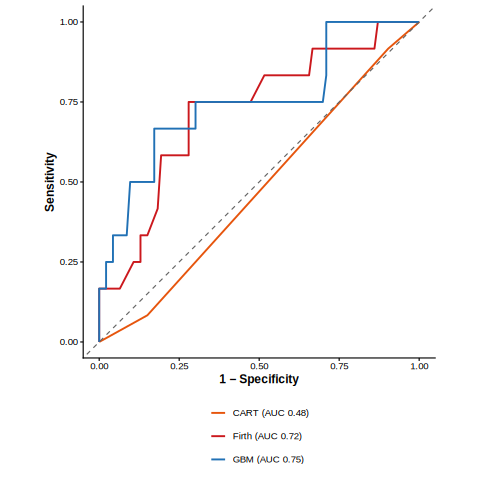

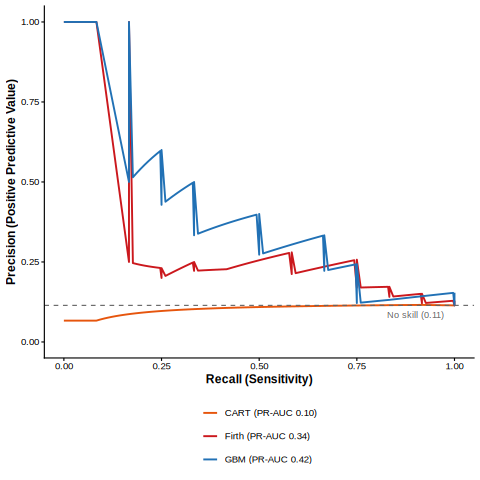

In [ ]:
%%R
# Test-set comparison of the three model families (Figures 12 and 13)
pr_ml <- PRROC::pr.curve(scores.class0 = pred_prob, weights.class0 = test_labels, curve = TRUE)
lab_ml    <- sprintf("%s (AUC %.2f)", MODEL_LABEL, pROC::auc(roc_ml))
lab_firth <- sprintf("Firth (AUC %.2f)", pROC::auc(roc_firth))
lab_cart  <- sprintf("CART (AUC %.2f)", pROC::auc(roc_cart))
roc_df <- dplyr::bind_rows(
  data.frame(FPR = 1 - roc_ml$specificities,    TPR = roc_ml$sensitivities,    Model = lab_ml),
  data.frame(FPR = 1 - roc_firth$specificities, TPR = roc_firth$sensitivities, Model = lab_firth),
  data.frame(FPR = 1 - roc_cart$specificities,  TPR = roc_cart$sensitivities,  Model = lab_cart))
p_roc_all <- ggplot(roc_df, aes(FPR, TPR, colour = Model)) +
  geom_path(linewidth = 0.9) + geom_abline(linetype = "dashed", colour = COL_GREY) +
  scale_colour_manual(values = setNames(c(COL_BLUE, COL_RED, COL_ORANGE), c(lab_ml, lab_firth, lab_cart)), name = NULL) +
  labs(title = "ROC Curves (Test Set)", x = "1 − Specificity", y = "Sensitivity") +
  coord_equal() + theme_los() + guides(colour = guide_legend(ncol = 1))
SaveFig(p_roc_all, "Fig12_ROCComparison", width = 5.5, height = 6)
print(p_roc_all)

plab <- function(name, pr) sprintf("%s (PR-AUC %.2f)", name, pr$auc.integral)
pr_df <- dplyr::bind_rows(
  data.frame(Recall = pr_ml$curve[, 1],    Precision = pr_ml$curve[, 2],    Model = plab(MODEL_LABEL, pr_ml)),
  data.frame(Recall = pr_firth$curve[, 1], Precision = pr_firth$curve[, 2], Model = plab("Firth", pr_firth)),
  data.frame(Recall = pr_cart$curve[, 1],  Precision = pr_cart$curve[, 2],  Model = plab("CART", pr_cart)))
p_pr_all <- ggplot(pr_df, aes(Recall, Precision, colour = Model)) +
  geom_line(linewidth = 0.9) +
  geom_hline(yintercept = mean(test_labels), linetype = "dashed", colour = COL_GREY) +
  annotate("text", x = 0.9, y = mean(test_labels) - 0.03, label = sprintf("No skill (%.2f)", mean(test_labels)), colour = COL_GREY, size = 3.2) +
  scale_colour_manual(values = setNames(c(COL_BLUE, COL_RED, COL_ORANGE), c(plab(MODEL_LABEL, pr_ml), plab("Firth", pr_firth), plab("CART", pr_cart))), name = NULL) +
  coord_cartesian(xlim = c(0, 1), ylim = c(0, 1)) +
  labs(title = "Precision-Recall Curves (Test Set)", x = "Recall (Sensitivity)", y = "Precision (Positive Predictive Value)") +
  theme_los() + guides(colour = guide_legend(ncol = 1))
SaveFig(p_pr_all, "Fig13_PRComparison", width = 5.5, height = 6)
print(p_pr_all)

# Methodological safeguards and sensitivity analyses
0. Embryo-level laboratory records: completeness and an independent check of the lot linkage.
0b. Sensitivity of the results to the linkage rules, and a multiverse (specification-curve) analysis of the main associations.
1. Keeping calves born after the outcome files ended (outcome-recording window).
2. Outcome definition, calf sex and linkage ambiguity.
3. Apparent performance as each safeguard is added (fixed learner, repeated cross-validation). Requires `conventional_analysis_dataset.csv` (conventional analysis of the same records).
4. Optimism of selecting a model on one small validation set (100 random splits).
5. Label-permutation test of the cross-validated signal.

In [ ]:
%%R
# Embryo-level laboratory records: completeness and an independent check of the lot linkage
# The laboratory 'Details' exports list every embryo produced (stage, quality, destiny, freezing protocol, shipping
# date). Embryos are numbered within lots only, so a calf cannot be linked to its own embryo; instead we check
# that the lot each calf was linked to contains a frozen embryo of the stage and quality recorded on the transfer
# sheet, shipped on or before the transfer date, and compare this with randomly assigned lots.
read_details <- function(f, lab) {
  d <- readxl::read_excel(f); names(d) <- trimws(names(d)); d$lab <- lab; d
}
details <- dplyr::bind_rows(
  read_details(file.path(BASE_DIR, "raw_data/lab_data/Aurora Ridge Syracuse NY - Details.xlsx"), "ny"),
  read_details(file.path(BASE_DIR, "raw_data/lab_data/Aurora Ridge Madison Wi - Details.xlsx"), "wi"))
emb_fields <- c("Embryo Stage", "Embryo Quality", "ICM Grade", "Is Biopsy Taken", "Embryo Sexing", "Genotyping",
                "Embryo Destiny", "Freezing Protocol", "Zona Intact", "Shipping or Transfer Date")
field_tab <- data.frame(Field = emb_fields,
                        Recorded_pct = sapply(emb_fields, function(v) round(100 * mean(!is.na(details[[v]]) & !(details[[v]] %in% c("Unchecked", ""))), 1)),
                        Distinct_values = sapply(emb_fields, function(v) dplyr::n_distinct(details[[v]], na.rm = TRUE)))
cat("Embryo records:", nrow(details), "from", dplyr::n_distinct(details$`Embryo Lot`), "lots\n"); print(field_tab, row.names = FALSE)
SaveTab(field_tab, "TableS_EmbryoRecordCompleteness")

frozen <- details %>% dplyr::filter(`Embryo Destiny` == "Frozen") %>%
  dplyr::transmute(lot = `Embryo Lot`, lab, stage = as.numeric(`Embryo Stage`), quality = as.character(`Embryo Quality`),
                   ship = as.Date(`Shipping or Transfer Date`))
calf_keys <- data.frame(lot = cluster_all$embryo_lot, lab = lab_farm_all$boviteq_lab_ID, stage = lab_farm_all$embryo_age,
                        grade = as.character(lab_farm_all$embryo_grade), transfer = as.Date(lab_farm_all$embryo_transfer_date),
                        in_window = lab_farm_all$in_window)
match_lot <- function(k, lot_vec) {
  vapply(seq_len(nrow(k)), function(i) {
    e <- frozen[frozen$lot == lot_vec[i], ]
    nrow(e[e$stage %in% k$stage[i] & e$quality %in% k$grade[i] & !is.na(e$ship) & e$ship <= k$transfer[i], ])
  }, integer(1))
}
k <- calf_keys[calf_keys$in_window, ]
n_cand <- match_lot(k, k$lot)
set.seed(123)
lots_by_ship <- frozen %>% dplyr::group_by(lot) %>% dplyr::summarise(first_ship = min(ship, na.rm = TRUE), .groups = "drop")
random_rate <- replicate(20, {
  rl <- vapply(seq_len(nrow(k)), function(i) { cand <- setdiff(lots_by_ship$lot[lots_by_ship$first_ship <= k$transfer[i]], k$lot[i]); sample(cand, 1) }, character(1))
  mean(match_lot(k, rl) > 0)
})
rare <- !(k$stage %in% 7 & k$grade %in% "1")
link_check <- data.frame(
  Check = c("Linked lot contains a frozen embryo of the recorded stage and quality, shipped before transfer",
            "Same check with a randomly assigned lot (mean of 20 draws)",
            "Calves with a less common stage/quality: linked lot", "Calves with a less common stage/quality: random lot",
            "Candidate embryos per calf in the linked lot (median)", "Calves with a single candidate embryo"),
  Value = c(sprintf("%.1f%%", 100 * mean(n_cand > 0)), sprintf("%.1f%%", 100 * mean(random_rate)),
            sprintf("%.1f%% (n = %d)", 100 * mean(n_cand[rare] > 0), sum(rare)), NA,
            as.character(median(n_cand[n_cand > 0])), sprintf("%.1f%%", 100 * mean(n_cand == 1))))
set.seed(123)
link_check$Value[4] <- sprintf("%.1f%%", 100 * mean(replicate(20, {
  kr <- k[rare, ]
  rl <- vapply(seq_len(nrow(kr)), function(i) { cand <- setdiff(lots_by_ship$lot[lots_by_ship$first_ship <= kr$transfer[i]], kr$lot[i]); sample(cand, 1) }, character(1))
  mean(match_lot(kr, rl) > 0) })))
print(link_check, row.names = FALSE)
SaveTab(link_check, "TableS_LinkageCheckEmbryoRecords")

Embryo records: 11504 from 160 lots
                     Field Recorded_pct Distinct_values
              Embryo Stage        100.0               6
            Embryo Quality        100.0               4
                 ICM Grade          0.0               0
           Is Biopsy Taken          0.0               1
             Embryo Sexing          0.0               0
                Genotyping          0.0               1
            Embryo Destiny         99.9               2
         Freezing Protocol         79.2               2
               Zona Intact          0.8               2
 Shipping or Transfer Date         78.7             123


                                                                                          Check
 Linked lot contains a frozen embryo of the recorded stage and quality, shipped before transfer
                                     Same check with a randomly assigned lot (mean of 20 draws)
                                            Calves with a less common stage/quality: linked lot
                                            Calves with a less common stage/quality: random lot
                                          Candidate embryos per calf in the linked lot (median)
                                                          Calves with a single candidate embryo
           Value
           98.0%
           86.5%
 96.4% (n = 253)
           71.6%
              29
            1.2%


In [ ]:
%%R
# Sensitivity of the results to the linkage rules
# Main rule: transfers diagnosed pregnant with implied gestation 250-310 d (closest to 280 d); laboratory lot =
# most recent lot of the donor and sire produced on or before the transfer date. Alternatives:
#  (a) implied gestation restricted to 260-300 d or 265-295 d;
#  (b) embryo-record-assisted lot choice: for calves with several candidate lots, the most recent lot that contains
#      a frozen embryo of the stage and quality on the transfer sheet, shipped on or before the transfer date
#      (the most recent lot if none does); uses `frozen` from the embryo-record cell;
#  (c) calves with a single candidate lot only.
link_ids <- lf_2023 %>% dplyr::filter(!grepl("/|TWIN|^FF|^MM|TRIPLET", toupper(calf_gender_remark)))
stopifnot(nrow(link_ids) == nrow(lab_farm_all), all(link_ids$embryo_transfer_date == lab_farm_all$embryo_transfer_date))
cand <- farm_data %>%
  dplyr::filter(calf_ID %in% link_ids$calf_ID) %>%
  dplyr::inner_join(lab_data, by = dplyr::join_by(donor_ID == donor_number, sire_ID == sire_ID,
                                                   embryo_transfer_date >= embryo_collection_date),
                    relationship = "many-to-many") %>%
  dplyr::mutate(storage_cand = as.numeric(embryo_transfer_date - embryo_collection_date),
                stage = as.numeric(as.character(embryo_age)), quality = as.character(embryo_grade))
emb_ok <- cand %>% dplyr::select(calf_ID, embryo_lot, stage, quality, embryo_transfer_date) %>% dplyr::distinct() %>%
  dplyr::inner_join(frozen %>% dplyr::select(lot, stage, quality, ship) %>% dplyr::distinct(),
                    by = c("embryo_lot" = "lot", "stage", "quality"), relationship = "many-to-many") %>%
  dplyr::filter(!is.na(ship), ship <= embryo_transfer_date) %>% dplyr::distinct(calf_ID, embryo_lot) %>% dplyr::mutate(emb_match = TRUE)
relinked <- cand %>% dplyr::left_join(emb_ok, by = c("calf_ID", "embryo_lot")) %>%
  dplyr::mutate(emb_match = !is.na(emb_match)) %>%
  dplyr::group_by(calf_ID) %>%
  dplyr::arrange(dplyr::desc(emb_match), storage_cand, .by_group = TRUE) %>% dplyr::slice(1) %>% dplyr::ungroup()
rl <- relinked[match(link_ids$calf_ID, relinked$calf_ID), ]
lab_farm_relinked <- lab_farm_all %>% dplyr::mutate(spo_program = as.character(spo_program))
changed <- !is.na(rl$embryo_lot) & rl$embryo_lot != cluster_all$embryo_lot
lab_farm_relinked$spo_program[changed]            <- rl$spo_program[changed]
lab_farm_relinked$dam_age_at_opu_months[changed]  <- as.numeric(sub(" months", "", rl$dam_age_at_opu[changed]))
lab_farm_relinked$prop_good_cumulus[changed]      <- as.numeric(rl$greater_than_or_equal_to_3_layers_of_cumulus[changed]) /
                                                     as.numeric(rl$total_structures_found[changed])
lab_farm_relinked$storage_days[changed]           <- rl$storage_cand[changed]
lab_farm_relinked$donor_cluster <- ifelse(lab_farm_all$dam_resolved, paste0("D", lab_farm_all$dam_ID_chr),
                                          paste0("L", ifelse(changed, rl$embryo_lot, cluster_all$embryo_lot)))
amb <- lab_farm_all$n_candidate_lots > 1
cat("Calves with more than one candidate lot:", sum(amb), "| most recent lot contains a matching embryo:",
    sum(amb & !changed & rl$emb_match), "| re-linked to an earlier lot with a matching embryo:", sum(changed),
    "| no candidate lot with a matching embryo:", sum(amb & !rl$emb_match), "\n")

all_rl  <- add_exposures(lab_farm_relinked)
link_sets <- list(
  "Main rule (gestation 250–310 d; most recent lot)"   = pre_df,
  "Implied gestation 260–300 d"                         = pre_df %>% dplyr::filter(dplyr::between(gestation_length, 260, 300)),
  "Implied gestation 265–295 d"                         = pre_df %>% dplyr::filter(dplyr::between(gestation_length, 265, 295)),
  "Embryo-record-assisted lot choice"                   = all_rl %>% dplyr::filter(in_window),
  "Single candidate lot only"                           = pre_df %>% dplyr::filter(n_candidate_lots == 1))
relink_tab <- do.call(rbind, lapply(names(link_sets), function(s) {
  d <- link_sets[[s]]
  r <- do.call(rbind, lapply(c("donor_age_le9", "fsh15", "cum_10pp"), function(v) firth_robust(d, v)))
  data.frame(`Linkage Rule` = s, Calves = nrow(d), Events = sum(d$y),
             `Donor Age ≤ 9 Months` = fmt_or(r$OR[1], r$lo[1], r$hi[1]), `1.5 cc FSH × 6` = fmt_or(r$OR[2], r$lo[2], r$hi[2]),
             `Oocytes with ≥3 Cumulus Layers (per 10 pp)` = fmt_or(r$OR[3], r$lo[3], r$hi[3]), check.names = FALSE)
}))
print(relink_tab, row.names = FALSE)
SaveTab(relink_tab, "TableS_LinkageRuleSensitivity")

Calves with more than one candidate lot: 240 | most recent lot contains a matching embryo: 227 | re-linked to an earlier lot with a matching embryo: 13 | no candidate lot with a matching embryo: 0 
                                     Linkage Rule Calves Events
 Main rule (gestation 250–310 d; most recent lot)    652     54
                      Implied gestation 260–300 d    650     53
                      Implied gestation 265–295 d    646     52
                Embryo-record-assisted lot choice    652     54
                        Single candidate lot only    493     42
 Donor Age ≤ 9 Months   1.5 cc FSH × 6
     2.24 (1.16–4.32) 2.30 (1.11–4.77)
     2.43 (1.27–4.63) 2.58 (1.30–5.16)
     2.38 (1.24–4.57) 2.90 (1.48–5.70)
     2.24 (1.16–4.32) 2.30 (1.11–4.77)
     2.23 (1.18–4.21) 2.79 (1.25–6.24)
 Oocytes with ≥3 Cumulus Layers (per 10 pp)
                           1.20 (1.07–1.35)
                           1.19 (1.05–1.34)
                           1.20 (1.06–1.36)
        

# A tibble: 3 × 6
  Exposure                                   Specifications `Median OR (IQR)`
  <chr>                                               <int> <chr>            
1 Oocytes with ≥3 Cumulus Layers (per 10 pp)             72 1.24 (1.12–1.35) 
2 Superovulation Protocol: 1.5 cc FSH × 6                72 3.35 (2.12–4.77) 
3 Young Donor Age                                       216 2.08 (1.40–3.65) 
  `Range of OR` `OR > 1 (%)` `95% CI Above 1 (%)`
  <chr>                <dbl>                <dbl>
1 1.04–1.42              100                   67
2 1.32–9.07              100                   69
3 0.50–8.88               86                   50
# A tibble: 15 × 5
   Choice              Level                          
   <chr>               <chr>                          
 1 Analysis set        All calvings from 2023         
 2 Analysis set        Recording window               
 3 Recording period    Adjusted                       
 4 Recording period    Not adjusted             

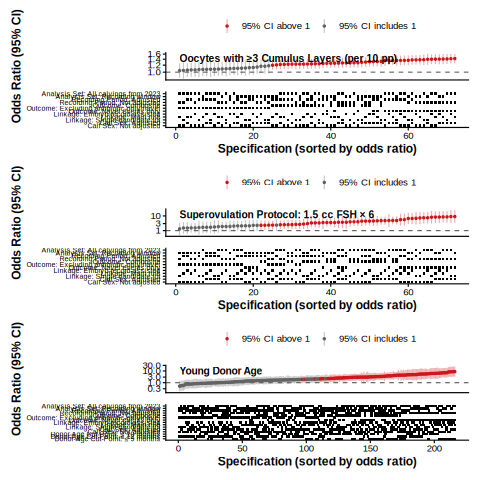

In [ ]:
%%R
# Multiverse (specification-curve) analysis of the main associations
# Every combination of defensible analytic choices is fitted (Firth regression, donor-cluster-robust 95% CI):
#   analysis set: outcome-recording window / all calvings from 2023
#   recording period: adjusted / not adjusted
#   outcome: composite / excluding antibiotic-only navel events / navel events only
#   linkage: main rule / embryo-record-assisted lot choice / single candidate lot only
#   calf sex: not adjusted / adjusted (sex unknown kept as a category)
#   donor-age cut-point (donor age only): <= 9 / <= 10 / <= 12 months
mv_prep <- function(d) d %>% dplyr::mutate(
  sex3 = factor(ifelse(is.na(calf_gender), "Unknown", as.character(calf_gender)), levels = c("Female", "Male", "Unknown")),
  age_le10 = as.integer(dam_age_at_opu_months <= 10), age_le12 = as.integer(dam_age_at_opu_months <= 12),
  donor_age_le9 = as.integer(dam_age_at_opu_months <= 9))
mv_data <- list("Main rule" = mv_prep(add_exposures(lab_farm_all)), "Embryo-record-assisted" = mv_prep(all_rl))
mv_data[["Single candidate lot"]] <- mv_data[["Main rule"]] %>% dplyr::filter(n_candidate_lots == 1)
mv_grid <- expand.grid(window = c("Recording window", "All calvings from 2023"), period = c("Adjusted", "Not adjusted"),
                       outcome = c("Composite", "Excluding antibiotic-only navel", "Navel events only"),
                       linkage = names(mv_data), sex = c("Not adjusted", "Adjusted"), stringsAsFactors = FALSE)
mv_exposures <- list(cum_10pp = list(label = "Oocytes with ≥3 Cumulus Layers (per 10 pp)", vars = c("Not applicable" = "cum_10pp")),
                     fsh15 = list(label = "Superovulation Protocol: 1.5 cc FSH × 6", vars = c("Not applicable" = "fsh15")),
                     donor_age = list(label = "Young Donor Age", vars = c("≤ 9 months" = "donor_age_le9", "≤ 10 months" = "age_le10", "≤ 12 months" = "age_le12")))
mv_res <- do.call(rbind, lapply(names(mv_exposures), function(ex) {
  do.call(rbind, lapply(names(mv_exposures[[ex]]$vars), function(cut) {
    v <- mv_exposures[[ex]]$vars[[cut]]
    do.call(rbind, lapply(seq_len(nrow(mv_grid)), function(i) {
      g <- mv_grid[i, ]; d <- mv_data[[g$linkage]]
      if (g$window == "Recording window") d <- d %>% dplyr::filter(in_window)
      d$y <- switch(g$outcome, "Composite" = d$y, "Excluding antibiotic-only navel" = d$ev_strict, "Navel events only" = d$ev_navel)
      adj <- c(if (g$period == "Adjusted") "rec_period", if (g$sex == "Adjusted") "sex3")
      if (g$window == "Recording window" && g$sex == "Adjusted") adj[adj == "sex3"] <- "male_calf"
      r <- tryCatch(firth_robust(d, v, adjust = adj), error = function(e) NULL)
      if (is.null(r)) return(NULL)
      data.frame(exposure = mv_exposures[[ex]]$label, cut = cut, g, n = r$n, events = r$events, OR = r$OR, lo = r$lo, hi = r$hi)
    }))
  }))
}))
mv_summary <- mv_res %>% dplyr::group_by(Exposure = exposure) %>%
  dplyr::summarise(Specifications = dplyr::n(), `Median OR (IQR)` = sprintf("%.2f (%.2f–%.2f)", median(OR), quantile(OR, 0.25), quantile(OR, 0.75)),
                   `Range of OR` = sprintf("%.2f–%.2f", min(OR), max(OR)), `OR > 1 (%)` = round(100 * mean(OR > 1)),
                   `95% CI Above 1 (%)` = round(100 * mean(lo > 1)), .groups = "drop")
# which choice moves the estimate: median OR by level of each choice
mv_by <- do.call(rbind, lapply(names(c(window = 1, period = 1, outcome = 1, linkage = 1, sex = 1, cut = 1)), function(dim) {
  mv_res %>% dplyr::group_by(Choice = c(window = "Analysis set", period = "Recording period", outcome = "Outcome",
                                        linkage = "Linkage", sex = "Calf sex", cut = "Donor-age cut-point")[[dim]],
                             Level = .data[[dim]], exposure) %>%
    dplyr::summarise(v = sprintf("%.2f [%d%%]", median(OR), round(100 * mean(lo > 1))), .groups = "drop") %>%
    tidyr::pivot_wider(names_from = exposure, values_from = v)
})) %>% dplyr::filter(Level != "Not applicable")
mv_by[is.na(mv_by)] <- "—"
print(mv_summary, width = Inf); print(mv_by, n = Inf, width = Inf)
SaveTab(mv_summary, "TableS_MultiverseSummary")
SaveTab(mv_by, "TableS_MultiverseByChoice")
SaveTab(mv_res %>% dplyr::mutate(dplyr::across(c(OR, lo, hi), ~ round(.x, 3))), "TableS_MultiverseAllSpecifications")

# Specification-curve figure: estimates sorted by size (top) and the choices behind each estimate (bottom)
spec_plot <- function(ex) {
  d <- mv_res %>% dplyr::filter(exposure == ex) %>% dplyr::arrange(OR) %>% dplyr::mutate(rank = dplyr::row_number(),
         sig = ifelse(lo > 1, "95% CI above 1", ifelse(hi < 1, "95% CI below 1", "95% CI includes 1")))
  top <- ggplot(d, aes(rank, OR, colour = sig)) + geom_hline(yintercept = 1, linetype = "dashed", colour = COL_GREY) +
    geom_linerange(aes(ymin = lo, ymax = hi), alpha = 0.35) + geom_point(size = 0.9) + scale_y_log10() +
    scale_colour_manual(values = c("95% CI above 1" = COL_RED, "95% CI includes 1" = COL_GREY, "95% CI below 1" = COL_BLUE), name = NULL, drop = FALSE) +
    annotate("text", x = 1, y = max(d$hi), label = ex, hjust = 0, vjust = 1, fontface = "bold", size = 3.6) +
    labs(x = NULL, y = "Odds Ratio (95% CI)") + theme_los() +
    theme(axis.text.x = element_blank(), axis.ticks.x = element_blank(), legend.position = "top")
  dims <- c(window = "Analysis Set", period = "Recording Period", outcome = "Outcome", linkage = "Linkage", sex = "Calf Sex")
  if (dplyr::n_distinct(d$cut) > 1) dims <- c(dims, cut = "Donor-Age Cut-Point")
  ind <- do.call(rbind, lapply(names(dims), function(k) data.frame(rank = d$rank, Choice = dims[[k]], Level = d[[k]])))
  row_levels <- unlist(lapply(names(dims), function(k) paste(dims[[k]], sort(unique(d[[k]])), sep = ": ")))
  ind$Row <- factor(paste(ind$Choice, ind$Level, sep = ": "), levels = rev(row_levels))
  bot <- ggplot(ind, aes(rank, Row)) + geom_point(shape = 15, size = 0.8) + labs(x = "Specification (sorted by odds ratio)", y = NULL) +
    theme_los() + theme(axis.text.y = element_text(size = 7))
  patchwork::wrap_plots(top, bot, ncol = 1, heights = c(1, 1.3))
}
p_spec <- patchwork::wrap_plots(lapply(unique(mv_res$exposure), spec_plot), ncol = 1)
SaveFig(p_spec, "FigS_SpecificationCurve", width = 9, height = 15)
print(p_spec)

In [ ]:
%%R
# Sensitivity analysis 1: what happens if calves born after the outcome files ended are kept?
# Crude Firth odds ratios with donor-cluster-robust 95% CI, (A) all laboratory-linked calves from 2023,
# (B) outcome-recording window, (C) window + recording period (the main analysis).
all_df <- add_exposures(lab_farm_all)
win_df <- add_exposures(lab_farm_data)
window_tab <- do.call(rbind, lapply(c("fsh15", "donor_age_le9", "cum_10pp", "season"), function(v) {
  a <- firth_robust(all_df, v, adjust = NULL); b <- firth_robust(win_df, v, adjust = NULL); c <- firth_robust(win_df, v)
  data.frame(Exposure = if (v == "season") paste0("Season of Transfer: ", CleanLevel(sub("^season", "", a$term))) else prespec_labels[[v]],
             `A: All Calvings` = fmt_or(a$OR, a$lo, a$hi), `B: Recording Window` = fmt_or(b$OR, b$lo, b$hi),
             `C: Window + Recording Period` = fmt_or(c$OR, c$lo, c$hi), check.names = FALSE)
}))
cat("A:", nrow(all_df), "calves,", sum(all_df$y), "events | B, C:", nrow(win_df), "calves,", sum(win_df$y), "events\n")
print(window_tab, row.names = FALSE)
SaveTab(window_tab, "TableS_WindowSensitivity")
# why season looked like a risk factor: share of calves per transfer season born during intensive recording
# (within the window) and after the outcome files ended
print(lab_farm_all %>% dplyr::group_by(Season = CleanLevel(as.character(season))) %>%
        dplyr::summarise(calves = dplyr::n(), pct_intensive_recording = round(100 * mean(rec_period == "intensive" & in_window)),
                         pct_after_files_ended = round(100 * mean(!in_window)), .groups = "drop"))

# (D) all calvings, adjusted for recording period
window_tab$`D: All Calvings + Recording Period` <- unlist(lapply(c("fsh15", "donor_age_le9", "cum_10pp", "season"), function(v) {
  d <- firth_robust(all_df, v); fmt_or(d$OR, d$lo, d$hi) }))
print(window_tab, row.names = FALSE)
SaveTab(window_tab, "TableS_WindowSensitivity")

A: 1017 calves, 57 events | B, C: 652 calves, 54 events
                                   Exposure  A: All Calvings
    Superovulation Protocol: 1.5 cc FSH × 6 4.00 (2.07–7.74)
                       Donor Age ≤ 9 Months 3.83 (1.95–7.50)
 Oocytes with ≥3 Cumulus Layers (per 10 pp) 1.23 (1.09–1.39)
                 Season of Transfer: Spring 1.30 (0.56–3.01)
                 Season of Transfer: Summer 0.44 (0.15–1.32)
                 Season of Transfer: Winter 2.68 (1.15–6.23)
 B: Recording Window C: Window + Recording Period
    3.54 (1.92–6.52)             2.30 (1.11–4.77)
    3.37 (1.77–6.41)             2.24 (1.16–4.32)
    1.26 (1.12–1.41)             1.20 (1.07–1.35)
    0.90 (0.43–1.90)             1.27 (0.63–2.56)
    0.61 (0.23–1.62)             1.29 (0.40–4.16)
    1.47 (0.67–3.19)             1.14 (0.55–2.34)


# A tibble: 4 × 4
  Season calves pct_intensive_recording pct_after_files_ended
  <chr>   <int>                   <dbl>                 <dbl>
1 Autumn    250                      27                    44
2 Spring    280                      15                    35
3 Summer    264                       0                    59
4 Winter    223                      72                     0
                                   Exposure  A: All Calvings
    Superovulation Protocol: 1.5 cc FSH × 6 4.00 (2.07–7.74)
                       Donor Age ≤ 9 Months 3.83 (1.95–7.50)
 Oocytes with ≥3 Cumulus Layers (per 10 pp) 1.23 (1.09–1.39)
                 Season of Transfer: Spring 1.30 (0.56–3.01)
                 Season of Transfer: Summer 0.44 (0.15–1.32)
                 Season of Transfer: Winter 2.68 (1.15–6.23)
 B: Recording Window C: Window + Recording Period
    3.54 (1.92–6.52)             2.30 (1.11–4.77)
    3.37 (1.77–6.41)             2.24 (1.16–4.32)
    1.26 (1.12–1.41)             

In [ ]:
%%R
# Sensitivity analysis 2: outcome definition, calf sex and linkage
# Main pre-specified associations re-estimated (with recording period) under alternative definitions.
sens_sets <- list(
  "Main analysis"                                        = win_df,
  "Excluding antibiotic-only navel events"               = win_df %>% dplyr::mutate(y = ev_strict),
  "Navel events only as outcome"                         = win_df %>% dplyr::mutate(y = ev_navel),
  "Female calves only"                                   = win_df %>% dplyr::filter(calf_gender == "Female"),
  "Unambiguous laboratory linkage (one candidate lot)"   = win_df %>% dplyr::filter(n_candidate_lots == 1))
sens_tab <- do.call(rbind, lapply(names(sens_sets), function(s) {
  d <- sens_sets[[s]]
  r <- do.call(rbind, lapply(c("donor_age_le9", "fsh15", "cum_10pp"), function(v) firth_robust(d, v)))
  data.frame(Analysis = s, Calves = nrow(d), Events = sum(d$y),
             `Donor Age ≤ 9 Months` = fmt_or(r$OR[1], r$lo[1], r$hi[1]),
             `1.5 cc FSH × 6` = fmt_or(r$OR[2], r$lo[2], r$hi[2]),
             `Oocytes with ≥3 Cumulus Layers (per 10 pp)` = fmt_or(r$OR[3], r$lo[3], r$hi[3]), check.names = FALSE)
}))
print(sens_tab, row.names = FALSE)
SaveTab(sens_tab, "TableS_OutcomeSensitivity")

                                           Analysis Calves Events
                                      Main analysis    652     54
             Excluding antibiotic-only navel events    652     29
                       Navel events only as outcome    652     39
                                 Female calves only    491     45
 Unambiguous laboratory linkage (one candidate lot)    493     42
 Donor Age ≤ 9 Months   1.5 cc FSH × 6
     2.24 (1.16–4.32) 2.30 (1.11–4.77)
     1.28 (0.60–2.73) 1.51 (0.60–3.76)
     2.98 (1.40–6.35) 2.12 (0.87–5.15)
     2.64 (1.20–5.78) 2.17 (0.97–4.88)
     2.23 (1.18–4.21) 2.79 (1.25–6.24)
 Oocytes with ≥3 Cumulus Layers (per 10 pp)
                           1.20 (1.07–1.35)
                           1.07 (0.90–1.28)
                           1.26 (1.13–1.41)
                           1.32 (1.11–1.57)
                           1.23 (1.08–1.40)


In [ ]:
%%R
# How much does each safeguard change apparent model performance?
# One fixed gradient-boosting learner (gbm package; same settings everywhere, class-weighted like
# balance_classes) is evaluated with 10 x 5-fold cross-validation while the safeguards are added one at a time.
# PR-AUC is computed as average precision; its no-skill value equals the prevalence.
avg_prec <- function(y, p) { o <- order(p, decreasing = TRUE); y <- y[o]; sum((cumsum(y) / seq_along(y))[y == 1]) / sum(y) }
auc_fast <- function(y, p) { r <- rank(p); n1 <- sum(y == 1); n0 <- sum(y == 0); (sum(r[y == 1]) - n1 * (n1 + 1) / 2) / (n1 * n0) }
prep_gbm <- function(df) {
  df <- as.data.frame(df)
  for (v in names(df)) if (is.character(df[[v]]) || is.logical(df[[v]])) df[[v]] <- factor(df[[v]])
  df <- df[, vapply(df, function(v) dplyr::n_distinct(v, na.rm = TRUE) > 1, logical(1)), drop = FALSE]
  df$y <- as.integer(as.character(df$LOS_final) == "LOS"); df$LOS_final <- NULL; df
}
GBM_ARGS <- list(n.trees = 200, interaction.depth = 3, shrinkage = 0.05, n.minobsinnode = 10, bag.fraction = 0.8)
fit_gbm <- function(tr, args = GBM_ARGS) {
  w <- ifelse(tr$y == 1, sum(tr$y == 0) / sum(tr$y == 1), 1)
  suppressWarnings(do.call(gbm::gbm, c(list(formula = y ~ ., data = tr, distribution = "bernoulli", weights = w, verbose = FALSE), args)))
}
pred_gbm <- function(m, te) suppressWarnings(predict(m, newdata = te, n.trees = m$n.trees, type = "response"))
strat_folds <- function(y, k = 5) { f <- integer(length(y)); for (cl in 0:1) { i <- which(y == cl); f[i] <- sample(rep(1:k, length.out = length(i))) }; f }
group_folds <- function(g, k = 5) { u <- unique(g); a <- setNames(sample(rep(1:k, length.out = length(u))), u); unname(a[g]) }
cv_gbm <- function(df, groups = NULL, reps = 10, seed = 123) {
  set.seed(seed)
  res <- t(replicate(reps, {
    f <- if (is.null(groups)) strat_folds(df$y) else group_folds(groups)
    p <- numeric(nrow(df)); for (k in unique(f)) { m <- fit_gbm(df[f != k, ]); p[f == k] <- pred_gbm(m, df[f == k, ]) }
    c(auc_fast(df$y, p), avg_prec(df$y, p))
  }))
  c(AUC = mean(res[, 1]), PR_AUC = mean(res[, 2]), PR_AUC_sd = sd(res[, 2]))
}

conventional_file <- file.path(BASE_DIR, "conventional_analysis_dataset.csv")   # analysis file of the conventional analysis (comparator)
d_init <- if (file.exists(conventional_file)) prep_gbm(readr::read_csv(conventional_file, show_col_types = FALSE)) else NULL
d_all  <- prep_gbm(master_all %>% dplyr::select(-rec_period))                      # safeguarded linkage and variables, all calvings
d_win  <- prep_gbm(master_data %>% dplyr::select(-rec_period))                     # + recording window
d_per  <- prep_gbm(master_data)                                                    # + recording period
steps <- list(
  list("1. Conventional analysis file (laboratory fields as labelled, linkage without pregnancy confirmation, navel treatments at any age, all calvings), random folds", d_init, NULL),
  list("2. Safeguarded linkage, outcome definition and laboratory variables, all calvings, random folds", d_all, NULL),
  list("3. + Outcome-recording window", d_win, NULL),
  list("4. + Recording period as a predictor", d_per, NULL),
  list("5. + Folds grouped by donor cluster", d_per, master_cluster))
safeguard_tab <- do.call(rbind, lapply(steps, function(s) {
  if (is.null(s[[2]])) return(NULL)
  r <- cv_gbm(s[[2]], s[[3]])
  data.frame(Step = s[[1]], Calves = nrow(s[[2]]), Events = sum(s[[2]]$y), Prevalence = round(mean(s[[2]]$y), 3),
             AUC = round(r["AUC"], 3), PR_AUC = round(r["PR_AUC"], 3), PR_AUC_SD = round(r["PR_AUC_sd"], 3),
             PR_AUC_vs_No_Skill = round(r["PR_AUC"] / mean(s[[2]]$y), 2), row.names = NULL)
}))
print(safeguard_tab, row.names = FALSE)
SaveTab(safeguard_tab, "Table_SafeguardComparison")

                                                                                                                                                           Step
 1. Conventional analysis file (laboratory fields as labelled, linkage without pregnancy confirmation, navel treatments at any age, all calvings), random folds
                                                                2. Safeguarded linkage, outcome definition and laboratory variables, all calvings, random folds
                                                                                                                                  3. + Outcome-recording window
                                                                                                                           4. + Recording period as a predictor
                                                                                                                            5. + Folds grouped by donor cluster
 Calves Events Prevalence   AUC PR_AUC P

In [ ]:
%%R
# How optimistic is model selection on one small validation set?
# The conventional protocol: one random stratified 70/15/15 split, the best of several models chosen on the 15%
# validation set, and that model's validation and test PR-AUC reported. Repeated over 100 random splits with
# 12 gbm configurations, on the conventional and the safeguarded analysis files.
GRID <- expand.grid(interaction.depth = c(1, 3, 5), shrinkage = c(0.01, 0.1), n.trees = c(100, 300), n.minobsinnode = 10, bag.fraction = 0.8)
split_sim <- function(df, n_splits = 100, seed = 123) {
  set.seed(seed)
  t(replicate(n_splits, {
    idx <- split(seq_len(nrow(df)), df$y); part <- integer(nrow(df))
    for (i in idx) { i <- sample(i); n <- length(i); part[i] <- c(rep(1L, floor(0.7 * n)), rep(2L, floor(0.15 * n)), rep(3L, n - floor(0.7 * n) - floor(0.15 * n))) }
    tr <- df[part == 1, ]; va <- df[part == 2, ]; te <- df[part == 3, ]
    sc <- sapply(seq_len(nrow(GRID)), function(j) { m <- fit_gbm(tr, as.list(GRID[j, ])); avg_prec(va$y, pred_gbm(m, va)) })
    best <- fit_gbm(tr, as.list(GRID[which.max(sc), ]))
    c(valid_best = max(sc), test = avg_prec(te$y, pred_gbm(best, te)), valid_events = sum(va$y), test_events = sum(te$y))
  }))
}
q <- function(v) sprintf("%.2f (%.2f–%.2f)", median(v), quantile(v, 0.05), quantile(v, 0.95))
sim_sets <- list("Conventional analysis file" = d_init, "Safeguarded analysis file" = d_per)
single_split_tab <- do.call(rbind, lapply(names(sim_sets), function(nm) {
  if (is.null(sim_sets[[nm]])) return(NULL)
  s <- split_sim(sim_sets[[nm]])
  data.frame(Dataset = nm, Validation_Events = median(s[, "valid_events"]), Test_Events = median(s[, "test_events"]),
             `Best Validation PR-AUC, Median (5th-95th Percentile)` = q(s[, "valid_best"]),
             `Test PR-AUC of That Model` = q(s[, "test"]),
             `Splits with Test PR-AUC >= 0.30 (%)` = round(100 * mean(s[, "test"] >= 0.30)), check.names = FALSE)
}))
print(single_split_tab, row.names = FALSE)
SaveTab(single_split_tab, "TableS_SingleSplitSelection")

                    Dataset Validation_Events Test_Events
 Conventional analysis file                 9          11
  Safeguarded analysis file                 8           9
 Best Validation PR-AUC, Median (5th-95th Percentile) Test PR-AUC of That Model
                                     0.20 (0.09–0.37)          0.14 (0.08–0.26)
                                     0.24 (0.12–0.45)          0.16 (0.10–0.33)
 Splits with Test PR-AUC >= 0.30 (%)
                                   2
                                   8


In [ ]:
%%R
# Is the cross-validated signal better than chance? (label-permutation test)
# Safeguarded analysis file, folds grouped by donor cluster (fixed fold assignment). Labels are permuted
# (a) completely and (b) within recording period; (b) asks whether the farm and laboratory variables add
# anything beyond the change in recording.
set.seed(123)
fixed_folds <- group_folds(master_cluster)
cv_once <- function(df) { p <- numeric(nrow(df)); for (k in unique(fixed_folds)) { m <- fit_gbm(df[fixed_folds != k, ]); p[fixed_folds == k] <- pred_gbm(m, df[fixed_folds == k, ]) }; avg_prec(df$y, p) }
obs_pr <- cv_once(d_per)
N_NULL <- 200
null_full   <- replicate(N_NULL, { dd <- d_per; dd$y <- sample(dd$y); cv_once(dd) })
null_period <- replicate(N_NULL, { dd <- d_per; for (p in levels(dd$rec_period)) { i <- which(dd$rec_period == p); dd$y[i] <- sample(dd$y[i]) }; cv_once(dd) })
perm_null_tab <- data.frame(
  Test = c("Labels permuted completely", "Labels permuted within recording period"),
  Observed_PR_AUC = round(obs_pr, 3),
  Null_Median = round(c(median(null_full), median(null_period)), 3),
  Null_95th_Percentile = round(c(quantile(null_full, 0.95), quantile(null_period, 0.95)), 3),
  P = round(c((1 + sum(null_full >= obs_pr)) / (N_NULL + 1), (1 + sum(null_period >= obs_pr)) / (N_NULL + 1)), 3))
print(perm_null_tab, row.names = FALSE)
SaveTab(perm_null_tab, "TableS_PermutationNull")

                                    Test Observed_PR_AUC Null_Median
              Labels permuted completely           0.152       0.088
 Labels permuted within recording period           0.152       0.107
 Null_95th_Percentile     P
                0.128 0.005
                0.157 0.070


In [ ]:
%%R
# Session information (for the Methods and the code repository)
writeLines(capture.output(sessionInfo()), file.path(OutDir, "sessionInfo.txt"))
sessionInfo()

R version 4.6.1 (2026-06-24)
Platform: x86_64-pc-linux-gnu
Running under: Ubuntu 24.04.5 LTS

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/openblas-pthread/libblas.so.3 
LAPACK: /usr/lib/x86_64-linux-gnu/openblas-pthread/liblapack.so.3;  LAPACK version 3.12.0

locale:
 [1] LC_CTYPE=en_US.UTF-8       LC_NUMERIC=C              
 [3] LC_TIME=en_US.UTF-8        LC_COLLATE=en_US.UTF-8    
 [5] LC_MONETARY=en_US.UTF-8    LC_MESSAGES=en_US.UTF-8   
 [7] LC_PAPER=en_US.UTF-8       LC_NAME=C                 
 [9] LC_ADDRESS=C               LC_TELEPHONE=C            
[11] LC_MEASUREMENT=en_US.UTF-8 LC_IDENTIFICATION=C       

time zone: Etc/UTC
tzcode source: system (glibc)

attached base packages:
[1] grid      tools     stats     graphics  grDevices utils     datasets 
[8] methods   base     

other attached packages:
 [1] patchwork_1.3.2         scales_1.4.0            ggbeeswarm_0.7.3       
 [4] ggplot2_4.0.3           h2o_3.44.0.3            partykit_1.3-0         
 [7] mvtno

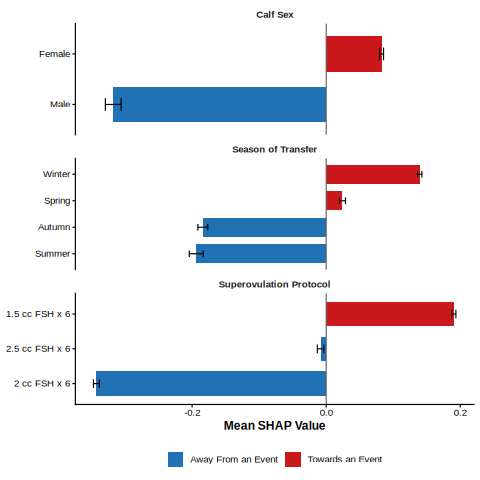

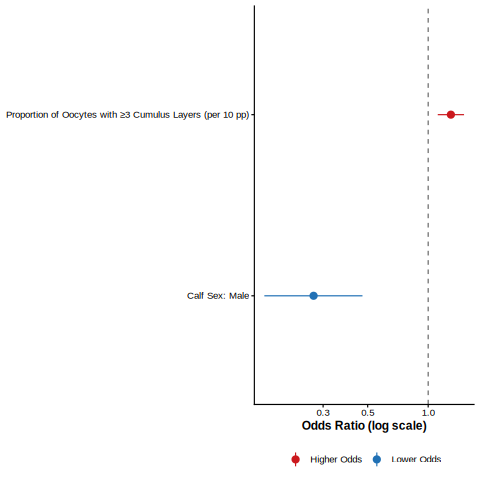

In [ ]:
%%R
# Redraw Figures 6 and 10 from the saved tables, without recording period
# (recording period is in the models only as an adjustment for the change in outcome recording, not a finding).
# Needs only the setup cells; no H2O and no model refitting.
cat_shap <- as.data.frame(readr::read_csv(file.path(TabDir, "Table_SHAPCategorical.csv"), show_col_types = FALSE))
p_cat_shap <- ggplot(dplyr::filter(cat_shap, Calves >= 4, variable != "rec_period"),
                     aes(x = reorder(level, mean_shap), y = mean_shap, fill = direction)) +
  geom_col(width = 0.7) +
  geom_errorbar(aes(ymin = mean_shap - se, ymax = mean_shap + se), width = 0.25) +
  geom_hline(yintercept = 0, colour = COL_GREY) +
  scale_fill_manual(values = c("Towards an Event" = COL_RED, "Away From an Event" = COL_BLUE), name = NULL) +
  facet_wrap(~ label, scales = "free_y", ncol = 1) + coord_flip() +
  labs(x = NULL, y = "Mean SHAP Value") +
  theme_los()
SaveFig(p_cat_shap, "Fig06_SHAPCategorical", width = 7, height = 7)
print(p_cat_shap)

firth_tab <- as.data.frame(readr::read_csv(file.path(TabDir, "Table_FirthLassoSelected.csv"), show_col_types = FALSE))
per10 <- !is.na(firth_tab[["Odds Ratio per 10 pp"]])
plot_df <- data.frame(Variable = firth_tab$Variable, OR = firth_tab[["Odds Ratio"]],
                      Lower_CI = firth_tab[["Lower 95% CI"]], Upper_CI = firth_tab[["Upper 95% CI"]], per10 = per10) %>%
  dplyr::filter(!grepl("^Recording Period", Variable)) %>%
  dplyr::mutate(OR = ifelse(per10, OR^0.1, OR), Lower_CI = ifelse(per10, Lower_CI^0.1, Lower_CI),
                Upper_CI = ifelse(per10, Upper_CI^0.1, Upper_CI),
                Variable = ifelse(per10, paste0(Variable, " (per 10 pp)"), Variable)) %>%
  dplyr::arrange(OR) %>%
  dplyr::mutate(Variable = factor(Variable, levels = Variable), direction = ifelse(OR > 1, "Higher Odds", "Lower Odds"))
p_firth <- ggplot(plot_df, aes(x = Variable, y = OR, colour = direction)) +
  geom_hline(yintercept = 1, linetype = "dashed", colour = COL_GREY) +
  geom_pointrange(aes(ymin = Lower_CI, ymax = Upper_CI), size = 0.6) +
  coord_flip() + scale_y_log10() +
  scale_colour_manual(values = c("Higher Odds" = COL_RED, "Lower Odds" = COL_BLUE), name = NULL) +
  labs(x = NULL, y = "Odds Ratio (log scale)") +
  theme_los()
SaveFig(p_firth, "Fig10_FirthForest", width = 7, height = 3.5)
print(p_firth)

In [ ]:
%%R
# Add the conventional-analysis rows to Supplementary Tables S5 (Table_SafeguardComparison) and
# S10 (TableS_SingleSplitSelection). These rows were skipped in the full run because
# conventional_analysis_dataset.csv was not in BASE_DIR. Same functions, settings and seed as the
# full cells; the other rows of both tables are kept as they are. Needs only the setup cells (gbm package, no H2O).
avg_prec <- function(y, p) { o <- order(p, decreasing = TRUE); y <- y[o]; sum((cumsum(y) / seq_along(y))[y == 1]) / sum(y) }
auc_fast <- function(y, p) { r <- rank(p); n1 <- sum(y == 1); n0 <- sum(y == 0); (sum(r[y == 1]) - n1 * (n1 + 1) / 2) / (n1 * n0) }
prep_gbm <- function(df) {
  df <- as.data.frame(df)
  for (v in names(df)) if (is.character(df[[v]]) || is.logical(df[[v]])) df[[v]] <- factor(df[[v]])
  df <- df[, vapply(df, function(v) dplyr::n_distinct(v, na.rm = TRUE) > 1, logical(1)), drop = FALSE]
  df$y <- as.integer(as.character(df$LOS_final) == "LOS"); df$LOS_final <- NULL; df
}
GBM_ARGS <- list(n.trees = 200, interaction.depth = 3, shrinkage = 0.05, n.minobsinnode = 10, bag.fraction = 0.8)
fit_gbm <- function(tr, args = GBM_ARGS) {
  w <- ifelse(tr$y == 1, sum(tr$y == 0) / sum(tr$y == 1), 1)
  suppressWarnings(do.call(gbm::gbm, c(list(formula = y ~ ., data = tr, distribution = "bernoulli", weights = w, verbose = FALSE), args)))
}
pred_gbm <- function(m, te) suppressWarnings(predict(m, newdata = te, n.trees = m$n.trees, type = "response"))
strat_folds <- function(y, k = 5) { f <- integer(length(y)); for (cl in 0:1) { i <- which(y == cl); f[i] <- sample(rep(1:k, length.out = length(i))) }; f }
cv_gbm <- function(df, reps = 10, seed = 123) {
  set.seed(seed)
  res <- t(replicate(reps, {
    f <- strat_folds(df$y)
    p <- numeric(nrow(df)); for (k in unique(f)) { m <- fit_gbm(df[f != k, ]); p[f == k] <- pred_gbm(m, df[f == k, ]) }
    c(auc_fast(df$y, p), avg_prec(df$y, p))
  }))
  c(AUC = mean(res[, 1]), PR_AUC = mean(res[, 2]), PR_AUC_sd = sd(res[, 2]))
}
GRID <- expand.grid(interaction.depth = c(1, 3, 5), shrinkage = c(0.01, 0.1), n.trees = c(100, 300), n.minobsinnode = 10, bag.fraction = 0.8)
split_sim <- function(df, n_splits = 100, seed = 123) {
  set.seed(seed)
  t(replicate(n_splits, {
    idx <- split(seq_len(nrow(df)), df$y); part <- integer(nrow(df))
    for (i in idx) { i <- sample(i); n <- length(i); part[i] <- c(rep(1L, floor(0.7 * n)), rep(2L, floor(0.15 * n)), rep(3L, n - floor(0.7 * n) - floor(0.15 * n))) }
    tr <- df[part == 1, ]; va <- df[part == 2, ]; te <- df[part == 3, ]
    sc <- sapply(seq_len(nrow(GRID)), function(j) { m <- fit_gbm(tr, as.list(GRID[j, ])); avg_prec(va$y, pred_gbm(m, va)) })
    best <- fit_gbm(tr, as.list(GRID[which.max(sc), ]))
    c(valid_best = max(sc), test = avg_prec(te$y, pred_gbm(best, te)), valid_events = sum(va$y), test_events = sum(te$y))
  }))
}
q <- function(v) sprintf("%.2f (%.2f–%.2f)", median(v), quantile(v, 0.05), quantile(v, 0.95))

d_init <- prep_gbm(readr::read_csv(file.path(BASE_DIR, "conventional_analysis_dataset.csv"), show_col_types = FALSE))

# S5, step 1
r <- cv_gbm(d_init)
step1 <- data.frame("1. Conventional analysis file (laboratory fields as labelled, linkage without pregnancy confirmation, navel treatments at any age, all calvings), random folds",
                    nrow(d_init), sum(d_init$y), round(mean(d_init$y), 3), round(r["AUC"], 3), round(r["PR_AUC"], 3),
                    round(r["PR_AUC_sd"], 3), round(r["PR_AUC"] / mean(d_init$y), 2))
safeguard_tab <- as.data.frame(readr::read_csv(file.path(TabDir, "Table_SafeguardComparison.csv"), show_col_types = FALSE))
safeguard_tab <- safeguard_tab[!startsWith(safeguard_tab$Step, "1."), ]
names(step1) <- names(safeguard_tab)
safeguard_tab <- rbind(step1, safeguard_tab)
print(safeguard_tab, row.names = FALSE)
SaveTab(safeguard_tab, "Table_SafeguardComparison")

# S10, conventional row
s <- split_sim(d_init)
conv <- data.frame("Conventional analysis file", median(s[, "valid_events"]), median(s[, "test_events"]),
                   q(s[, "valid_best"]), q(s[, "test"]), round(100 * mean(s[, "test"] >= 0.30)))
single_split_tab <- as.data.frame(readr::read_csv(file.path(TabDir, "TableS_SingleSplitSelection.csv"), show_col_types = FALSE))
single_split_tab <- single_split_tab[single_split_tab$Dataset != "Conventional analysis file", ]
names(conv) <- names(single_split_tab)
single_split_tab <- rbind(conv, single_split_tab)
print(single_split_tab, row.names = FALSE)
SaveTab(single_split_tab, "TableS_SingleSplitSelection")

                                                                                                                                                           Step
 1. Conventional analysis file (laboratory fields as labelled, linkage without pregnancy confirmation, navel treatments at any age, all calvings), random folds
                                                                2. Safeguarded linkage, outcome definition and laboratory variables, all calvings, random folds
                                                                                                                                  3. + Outcome-recording window
                                                                                                                           4. + Recording period as a predictor
                                                                                                                            5. + Folds grouped by donor cluster
 Calves Events Prevalence   AUC PR-AUC P

                    Dataset Validation Events (Median) Test Events (Median)
 Conventional analysis file                          9                   11
  Safeguarded analysis file                          8                    9
 Best Validation PR-AUC, Median (5th-95th Percentile) Test PR-AUC of That Model
                                     0.20 (0.09–0.37)          0.14 (0.08–0.26)
                                     0.24 (0.12–0.45)          0.16 (0.10–0.33)
 Splits with Test PR-AUC ≥ 0.30 (%)
                                  2
                                  8
